# Semana 02 — Pandas e Engenharia de Dados

## Exercício 36 — Carregamento e inspeção de dados

**Projeto:** AI Energy Auditor

**Objetivo:** carregar e inspecionar o dataset energético produzido na Semana 01.

In [2]:
import pandas as pd
from pathlib import Path

arquivo = Path('../dados/consumo_energetico_v1.csv')

print('Arquivo encontrado:', arquivo.exists())

if not arquivo.exists():
    raise FileNotFoundError(f'Dataset não encontrado: {arquivo.resolve()}')

df = pd.read_csv(arquivo)

print('\n=== PRIMEIROS REGISTROS ===')
print(df.head())

print('\n=== DIMENSÕES ===')
print(df.shape)

print('\n=== TIPOS DE DADOS ===')
print(df.dtypes)

print('\n=== INFORMAÇÕES GERAIS ===')
df.info()

Arquivo encontrado: True

=== PRIMEIROS REGISTROS ===
         data  horas_operacao  consumo_kwh
0  2026-09-01              11   240.631779
1  2026-09-02               7   171.154997
2  2026-09-03               6   164.579122
3  2026-09-04              10   228.434206
4  2026-09-05               8   177.506886

=== DIMENSÕES ===
(30, 3)

=== TIPOS DE DADOS ===
data                  str
horas_operacao      int64
consumo_kwh       float64
dtype: object

=== INFORMAÇÕES GERAIS ===
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   data            30 non-null     str    
 1   horas_operacao  30 non-null     int64  
 2   consumo_kwh     30 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 852.0 bytes



 SEMANA 02 — EXERCÍCIO 36 — ETAPA 2
 Conversão e validação da coluna de datas


In [3]:
import pandas as pd

# 1. Verificar o tipo original
print("=== TIPO ORIGINAL ===")
print(df["data"].dtype)

# 2. Converter texto para datetime
df["data"] = pd.to_datetime(
    df["data"],
    format="%Y-%m-%d",
    errors="raise"
)

# 3. Verificar o novo tipo
print("\n=== TIPO APÓS CONVERSÃO ===")
print(df["data"].dtype)

# 4. Verificar intervalo temporal
print("\n=== INTERVALO DOS DADOS ===")
print("Primeira data:", df["data"].min())
print("Última data:", df["data"].max())

# 5. Verificar datas ausentes e duplicadas
print("\n=== QUALIDADE DAS DATAS ===")
print("Datas ausentes:", df["data"].isna().sum())
print("Datas duplicadas:", df["data"].duplicated().sum())

# 6. Verificar estrutura atualizada
print("\n=== TIPOS DE DADOS ===")
print(df.dtypes)

print("\n=== PRIMEIROS REGISTROS ===")
print(df.head())


=== TIPO ORIGINAL ===
str

=== TIPO APÓS CONVERSÃO ===
datetime64[us]

=== INTERVALO DOS DADOS ===
Primeira data: 2026-09-01 00:00:00
Última data: 2026-09-30 00:00:00

=== QUALIDADE DAS DATAS ===
Datas ausentes: 0
Datas duplicadas: 0

=== TIPOS DE DADOS ===
data              datetime64[us]
horas_operacao             int64
consumo_kwh              float64
dtype: object

=== PRIMEIROS REGISTROS ===
        data  horas_operacao  consumo_kwh
0 2026-09-01              11   240.631779
1 2026-09-02               7   171.154997
2 2026-09-03               6   164.579122
3 2026-09-04              10   228.434206
4 2026-09-05               8   177.506886


SEMANA 02 — EXERCÍCIO 36 — ETAPA 3
Validação da continuidade temporal

In [4]:

import pandas as pd

# 1. Identificar o intervalo de datas
data_inicial = df["data"].min()
data_final = df["data"].max()

# 2. Gerar todas as datas esperadas no intervalo
datas_esperadas = pd.date_range(
    start=data_inicial,
    end=data_final,
    freq="D"
)

# 3. Identificar as datas existentes
datas_existentes = pd.DatetimeIndex(df["data"])

# 4. Encontrar datas ausentes
datas_faltantes = datas_esperadas.difference(
    datas_existentes
)

# 5. Exibir os resultados
print("=== VALIDAÇÃO TEMPORAL ===")

print(f"Data inicial: {data_inicial:%d/%m/%Y}")
print(f"Data final: {data_final:%d/%m/%Y}")

print(f"Datas esperadas: {len(datas_esperadas)}")
print(f"Datas registradas: {len(datas_existentes)}")
print(f"Datas faltantes: {len(datas_faltantes)}")

# 6. Avaliar a continuidade
print("\n=== RESULTADO ===")

if len(datas_faltantes) == 0:
    print("Série temporal contínua: nenhum dia ausente.")
else:
    print("Foram identificadas lacunas temporais.")

    for data in datas_faltantes:
        print(f"Data ausente: {data:%d/%m/%Y}")


=== VALIDAÇÃO TEMPORAL ===
Data inicial: 01/09/2026
Data final: 30/09/2026
Datas esperadas: 30
Datas registradas: 30
Datas faltantes: 0

=== RESULTADO ===
Série temporal contínua: nenhum dia ausente.



SEMANA 02 — EXERCÍCIO 36 — ETAPA 4
Validação de regras de negócio


In [5]:
import pandas as pd

# 1. Verificar valores ausentes nas variáveis analisadas
valores_ausentes = df[
    ["horas_operacao", "consumo_kwh"]
].isna().any(axis=1)

# 2. Validar horas de operação
horas_invalidas = ~df["horas_operacao"].between(
    0, 24,
    inclusive="both"
)

# 3. Validar consumo energético
consumo_invalido = df["consumo_kwh"] < 0

# 4. Identificar registros que violam alguma regra
registros_invalidos = (
    valores_ausentes
    | horas_invalidas
    | consumo_invalido
)

# 5. Exibir o relatório
print("=== VALIDAÇÃO DE REGRAS DE NEGÓCIO ===")

print(f"Total de registros: {len(df)}")
print(f"Registros com valores ausentes: {valores_ausentes.sum()}")
print(f"Registros com horas inválidas: {horas_invalidas.sum()}")
print(f"Registros com consumo negativo: {consumo_invalido.sum()}")
print(f"Total de registros inválidos: {registros_invalidos.sum()}")

print("\n=== RESULTADO ===")

if not registros_invalidos.any():
    print("Todos os registros atendem às regras definidas.")
else:
    print("Foram identificados registros inválidos:")
    print(df.loc[registros_invalidos])


=== VALIDAÇÃO DE REGRAS DE NEGÓCIO ===
Total de registros: 30
Registros com valores ausentes: 0
Registros com horas inválidas: 0
Registros com consumo negativo: 0
Total de registros inválidos: 0

=== RESULTADO ===
Todos os registros atendem às regras definidas.


SEMANA 02 — EXERCÍCIO 36 — ETAPA 5
Filtragem condicional com Pandas

In [7]:
import pandas as pd

# 1. Definir o limite de consumo
limite_consumo = 230.0

# 2. Filtrar dias com consumo acima do limite
df_alto_consumo = df.loc[
    df["consumo_kwh"] > limite_consumo
].copy()

# 3. Ordenar pelo maior consumo
df_alto_consumo = df_alto_consumo.sort_values(
    by="consumo_kwh",
    ascending=False
)

# 4. Exibir os registros encontrados
print("=== DIAS COM CONSUMO ACIMA DE 230 kWh ===")

print(
    df_alto_consumo.to_string(
        index=False
    )
)

# 5. Calcular indicadores
quantidade_dias = len(df_alto_consumo)

percentual_dias = (
    quantidade_dias / len(df)
) * 100

media_alto_consumo = (
    df_alto_consumo["consumo_kwh"].mean()
)

# 6. Exibir resumo
print("\n=== RESUMO DA FILTRAGEM ===")

print(f"Total de dias analisados: {len(df)}")
print(f"Dias acima de 230 kWh: {quantidade_dias}")
print(f"Percentual de dias: {percentual_dias:.2f}%")
print(f"Consumo médio dos dias filtrados: {media_alto_consumo:.2f} kWh")


=== DIAS COM CONSUMO ACIMA DE 230 kWh ===
      data  horas_operacao  consumo_kwh
2026-09-17              12   282.217498
2026-09-24              12   272.078445
2026-09-11              11   269.895324
2026-09-22              12   259.771840
2026-09-14              12   251.239847
2026-09-15              11   250.099731
2026-09-13              10   246.178482
2026-09-23              11   242.511376
2026-09-01              11   240.631779
2026-09-18              10   240.007076
2026-09-12              11   239.441736
2026-09-28              11   238.090202
2026-09-26              10   232.453043

=== RESUMO DA FILTRAGEM ===
Total de dias analisados: 30
Dias acima de 230 kWh: 13
Percentual de dias: 43.33%
Consumo médio dos dias filtrados: 251.12 kWh


SEMANA 02 — EXERCÍCIO 36 — ETAPA 6
Estatística descritiva do consumo energético

In [8]:
import pandas as pd

# 1. Selecionar as variáveis numéricas
colunas_numericas = [
    "horas_operacao",
    "consumo_kwh"
]

# 2. Gerar estatísticas descritivas
estatisticas = df[colunas_numericas].describe()

print("=== ESTATÍSTICAS DESCRITIVAS ===")
print(estatisticas.round(2))

# 3. Calcular indicadores energéticos
consumo_total = df["consumo_kwh"].sum()
consumo_medio = df["consumo_kwh"].mean()
consumo_mediano = df["consumo_kwh"].median()
desvio_padrao = df["consumo_kwh"].std()

# 4. Calcular horas totais e indicador agregado
horas_totais = df["horas_operacao"].sum()

consumo_por_hora = (
    consumo_total / horas_totais
    if horas_totais > 0
    else float("nan")
)

# 5. Apresentar indicadores
print("\n=== INDICADORES ENERGÉTICOS ===")

print(f"Consumo total: {consumo_total:.2f} kWh")
print(f"Consumo médio diário: {consumo_medio:.2f} kWh")
print(f"Consumo mediano diário: {consumo_mediano:.2f} kWh")
print(f"Desvio-padrão do consumo: {desvio_padrao:.2f} kWh")
print(f"Total de horas de operação: {horas_totais} h")
print(f"Consumo por hora de operação: {consumo_por_hora:.2f} kWh/h")


=== ESTATÍSTICAS DESCRITIVAS ===
       horas_operacao  consumo_kwh
count           30.00        30.00
mean             9.20       216.81
std              2.04        36.31
min              6.00       161.97
25%              7.25       183.58
50%             10.00       225.34
75%             11.00       242.04
max             12.00       282.22

=== INDICADORES ENERGÉTICOS ===
Consumo total: 6504.22 kWh
Consumo médio diário: 216.81 kWh
Consumo mediano diário: 225.34 kWh
Desvio-padrão do consumo: 36.31 kWh
Total de horas de operação: 276 h
Consumo por hora de operação: 23.57 kWh/h


SEMANA 02 — EXERCÍCIO 36 — ETAPA 7
Correlação entre horas de operação e consumo energético

In [9]:
import pandas as pd

# 1. Calcular a matriz de correlação
matriz_correlacao = df[
    ["horas_operacao", "consumo_kwh"]
].corr(method="pearson")

print("=== MATRIZ DE CORRELAÇÃO ===")
print(matriz_correlacao.round(4))

# 2. Extrair a correlação entre as duas variáveis
correlacao = matriz_correlacao.loc[
    "horas_operacao",
    "consumo_kwh"
]

print("\n=== CORRELAÇÃO DE PEARSON ===")
print(f"Coeficiente: {correlacao:.4f}")

# 3. Interpretar a direção
if correlacao > 0:
    direcao = "positiva"
elif correlacao < 0:
    direcao = "negativa"
else:
    direcao = "nula"

# 4. Interpretar a intensidade
valor_absoluto = abs(correlacao)

if valor_absoluto >= 0.9:
    intensidade = "muito forte"
elif valor_absoluto >= 0.7:
    intensidade = "forte"
elif valor_absoluto >= 0.4:
    intensidade = "moderada"
elif valor_absoluto >= 0.2:
    intensidade = "fraca"
else:
    intensidade = "muito fraca ou inexistente"

print(f"Direção: {direcao}")
print(f"Intensidade: {intensidade}")

print("\n=== CONCLUSÃO ===")

print(
    "A correlação descreve associação linear, "
    "mas não demonstra causalidade."
)


=== MATRIZ DE CORRELAÇÃO ===
                horas_operacao  consumo_kwh
horas_operacao          1.0000       0.9586
consumo_kwh             0.9586       1.0000

=== CORRELAÇÃO DE PEARSON ===
Coeficiente: 0.9586
Direção: positiva
Intensidade: muito forte

=== CONCLUSÃO ===
A correlação descreve associação linear, mas não demonstra causalidade.


SEMANA 02 — EXERCÍCIO 36 — ETAPA 8
Visualização da correlação com Matplotlib

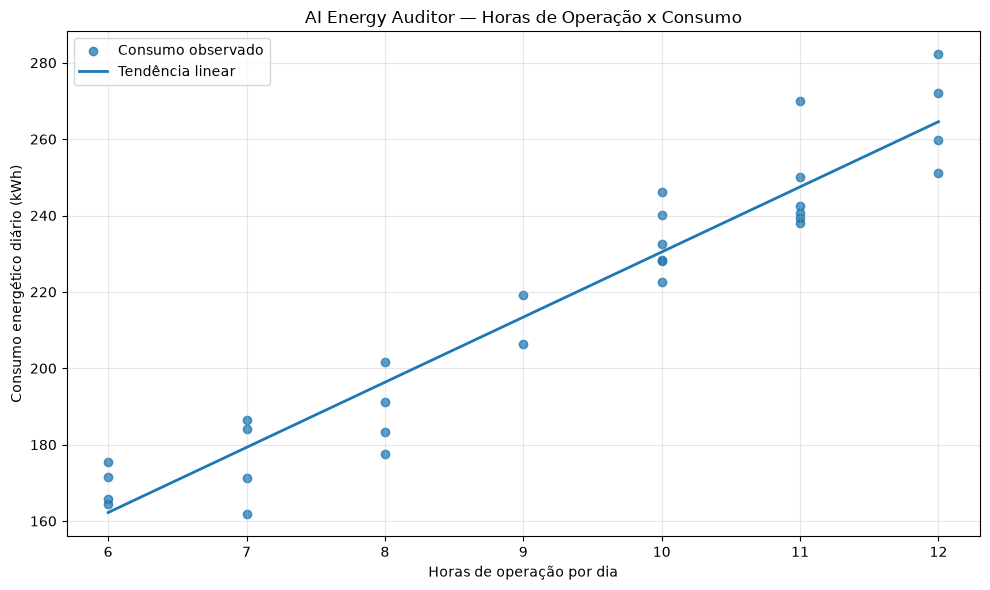

=== TENDÊNCIA LINEAR ===
Consumo estimado = 17.0558 × horas_operacao + 59.8946
Correlação de Pearson: 0.9586


In [10]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Selecionar as variáveis
x = df["horas_operacao"].to_numpy()
y = df["consumo_kwh"].to_numpy()

# 2. Calcular uma reta de tendência linear
coeficiente_angular, intercepto = np.polyfit(
    x, y, deg=1
)

# 3. Gerar pontos para desenhar a reta
x_linha = np.linspace(x.min(), x.max(), 100)

y_linha = (
    coeficiente_angular * x_linha
    + intercepto
)

# 4. Criar o gráfico
plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    alpha=0.75,
    label="Consumo observado"
)

plt.plot(
    x_linha,
    y_linha,
    linewidth=2,
    label="Tendência linear"
)

# 5. Configurar títulos e legendas
plt.title(
    "AI Energy Auditor — Horas de Operação x Consumo"
)

plt.xlabel("Horas de operação por dia")
plt.ylabel("Consumo energético diário (kWh)")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# 6. Exibir o gráfico
plt.show()

# 7. Apresentar a equação da reta
print("=== TENDÊNCIA LINEAR ===")

print(
    f"Consumo estimado = "
    f"{coeficiente_angular:.4f} × horas_operacao "
    f"+ {intercepto:.4f}"
)

print(f"Correlação de Pearson: {correlacao:.4f}")



## SEMANA 02 — EXERCÍCIO 37 
### ETAPA 1 - Feature Engineering: consumo por hora de operação


In [12]:



import numpy as np
import pandas as pd

# 1. Criar uma cópia para preservar o dataset original
df_features = df.copy()

# 2. Calcular consumo por hora
# Horas iguais a zero são tratadas como NaN para evitar divisão por zero
df_features["consumo_por_hora"] = (
    df_features["consumo_kwh"]
    / df_features["horas_operacao"].replace(0, np.nan)
)

# 3. Exibir os primeiros registros
print("=== DATASET COM NOVA VARIÁVEL ===")
print(df_features.head(10).to_string(index=False))

# 4. Verificar a estrutura
print("\n=== TIPOS DE DADOS ===")
print(df_features.dtypes)

# 5. Validar a nova variável
print("\n=== VALIDAÇÃO ===")
print(f"Total de registros: {len(df_features)}")
print(f"Total de colunas: {len(df_features.columns)}")
print(
    "Valores ausentes em consumo_por_hora:",
    df_features["consumo_por_hora"].isna().sum()
)

# 6. Calcular estatísticas da nova variável
print("\n=== ESTATÍSTICAS DO CONSUMO POR HORA ===")
print(df_features["consumo_por_hora"].describe().round(2))


=== DATASET COM NOVA VARIÁVEL ===
      data  horas_operacao  consumo_kwh  consumo_por_hora
2026-09-01              11   240.631779         21.875616
2026-09-02               7   171.154997         24.450714
2026-09-03               6   164.579122         27.429854
2026-09-04              10   228.434206         22.843421
2026-09-05               8   177.506886         22.188361
2026-09-06               9   206.272655         22.919184
2026-09-07               6   165.879459         27.646577
2026-09-08               8   191.212607         23.901576
2026-09-09              10   228.215206         22.821521
2026-09-10               8   201.702040         25.212755

=== TIPOS DE DADOS ===
data                datetime64[us]
horas_operacao               int64
consumo_kwh                float64
consumo_por_hora           float64
dtype: object

=== VALIDAÇÃO ===
Total de registros: 30
Total de colunas: 4
Valores ausentes em consumo_por_hora: 0

=== ESTATÍSTICAS DO CONSUMO POR HORA ===
count 

SEMANA 02 — EXERCÍCIO 37 — ETAPA 2.
Detecção exploratória de valores atípicos usando IQR

In [13]:
import pandas as pd

# 1. Calcular os quartis
q1 = df_features["consumo_por_hora"].quantile(0.25)
q3 = df_features["consumo_por_hora"].quantile(0.75)

# 2. Calcular o intervalo interquartil
iqr = q3 - q1

# 3. Definir limites estatísticos
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# 4. Criar uma coluna de sinalização
df_features["possivel_outlier"] = (
    (df_features["consumo_por_hora"] < limite_inferior)
    |
    (df_features["consumo_por_hora"] > limite_superior)
)

# 5. Selecionar registros sinalizados
df_outliers = df_features.loc[
    df_features["possivel_outlier"]
].copy()

# 6. Exibir limites
print("=== LIMITES ESTATÍSTICOS — IQR ===")
print(f"Primeiro quartil (Q1): {q1:.4f}")
print(f"Terceiro quartil (Q3): {q3:.4f}")
print(f"IQR: {iqr:.4f}")
print(f"Limite inferior: {limite_inferior:.4f}")
print(f"Limite superior: {limite_superior:.4f}")

# 7. Exibir resultados
print("\n=== RESULTADO DA DETECÇÃO ===")
print(f"Total de registros: {len(df_features)}")
print(f"Registros sinalizados: {len(df_outliers)}")

if df_outliers.empty:
    print("Nenhum valor atípico identificado pelo método IQR.")
else:
    print("\n=== REGISTROS SINALIZADOS ===")
    print(
        df_outliers[
            [
                "data",
                "horas_operacao",
                "consumo_kwh",
                "consumo_por_hora"
            ]
        ].to_string(index=False)
    )


=== LIMITES ESTATÍSTICOS — IQR ===
Primeiro quartil (Q1): 22.3531
Terceiro quartil (Q3): 24.5974
IQR: 2.2443
Limite inferior: 18.9867
Limite superior: 27.9638

=== RESULTADO DA DETECÇÃO ===
Total de registros: 30
Registros sinalizados: 2

=== REGISTROS SINALIZADOS ===
      data  horas_operacao  consumo_kwh  consumo_por_hora
2026-09-19               6   171.652601         28.608767
2026-09-29               6   175.331804         29.221967


SEMANA 02 — EXERCÍCIO 37 — ETAPA 3.
Investigação dos outliers usando resíduos da regressão

In [14]:

import numpy as np
import pandas as pd

# 1. Ajustar a reta usando os dados disponíveis
coef_angular, intercepto = np.polyfit(
    df_features["horas_operacao"],
    df_features["consumo_kwh"],
    deg=1
)

# 2. Calcular consumo estimado para cada dia
df_features["consumo_estimado_kwh"] = (
    coef_angular * df_features["horas_operacao"]
    + intercepto
)

# 3. Calcular os resíduos
df_features["residuo_kwh"] = (
    df_features["consumo_kwh"]
    - df_features["consumo_estimado_kwh"]
)

# 4. Selecionar os dois dias sinalizados pelo IQR
df_investigacao = df_features.loc[
    df_features["possivel_outlier"]
].copy()

# 5. Exibir os resultados
print("=== INVESTIGAÇÃO DOS REGISTROS SINALIZADOS ===")

colunas = [
    "data",
    "horas_operacao",
    "consumo_kwh",
    "consumo_estimado_kwh",
    "residuo_kwh",
    "consumo_por_hora"
]

print(
    df_investigacao[colunas]
    .round(4)
    .to_string(index=False)
)

# 6. Calcular a dispersão dos resíduos
desvio_residuos = df_features["residuo_kwh"].std()

print("\n=== DISPERSÃO DOS RESÍDUOS ===")
print(f"Desvio-padrão amostral: {desvio_residuos:.4f} kWh")

# 7. Comparar os resíduos dos dias investigados
print("\n=== RESÍDUOS PADRONIZADOS ===")

if desvio_residuos > 0:
    df_investigacao["residuo_padronizado"] = (
        df_investigacao["residuo_kwh"]
        / desvio_residuos
    )

    print(
        df_investigacao[
            ["data", "residuo_padronizado"]
        ]
        .round(4)
        .to_string(index=False)
    )
else:
    print("Não há dispersão residual para padronizar.")


=== INVESTIGAÇÃO DOS REGISTROS SINALIZADOS ===
      data  horas_operacao  consumo_kwh  consumo_estimado_kwh  residuo_kwh  consumo_por_hora
2026-09-19               6     171.6526              162.2291       9.4235           28.6088
2026-09-29               6     175.3318              162.2291      13.1027           29.2220

=== DISPERSÃO DOS RESÍDUOS ===
Desvio-padrão amostral: 10.3417 kWh

=== RESÍDUOS PADRONIZADOS ===
      data  residuo_padronizado
2026-09-19               0.9112
2026-09-29               1.2670


C:\Users\luism\AppData\Local\Temp\ipykernel_3304\3737317074.py:42: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(4)
C:\Users\luism\AppData\Local\Temp\ipykernel_3304\3737317074.py:65: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(4)


SEMANA 02 — EXERCÍCIO 37 — ETAPA 4.
Correção dos avisos e formatação dos resultados


In [15]:
# 1. Criar cópia dos resultados para apresentação
df_relatorio = df_investigacao.copy()

# 2. Formatar a data para apresentação
df_relatorio["data"] = (
    df_relatorio["data"].dt.strftime("%d/%m/%Y")
)

# 3. Selecionar somente as colunas numéricas
colunas_numericas = [
    "consumo_kwh",
    "consumo_estimado_kwh",
    "residuo_kwh",
    "consumo_por_hora",
    "residuo_padronizado"
]

# 4. Arredondar somente os valores numéricos
df_relatorio[colunas_numericas] = (
    df_relatorio[colunas_numericas].round(4)
)

# 5. Exibir o relatório corrigido
print("=== RELATÓRIO DE INVESTIGAÇÃO ENERGÉTICA ===")

print(
    df_relatorio[
        [
            "data",
            "horas_operacao",
            "consumo_kwh",
            "consumo_estimado_kwh",
            "residuo_kwh",
            "consumo_por_hora",
            "residuo_padronizado"
        ]
    ].to_string(index=False)
)

# 6. Verificar a execução
print("\n=== VALIDAÇÃO ===")
print(f"Registros investigados: {len(df_relatorio)}")
print("Relatório gerado com formatação específica por tipo.")


=== RELATÓRIO DE INVESTIGAÇÃO ENERGÉTICA ===
      data  horas_operacao  consumo_kwh  consumo_estimado_kwh  residuo_kwh  consumo_por_hora  residuo_padronizado
19/09/2026               6     171.6526              162.2291       9.4235           28.6088               0.9112
29/09/2026               6     175.3318              162.2291      13.1027           29.2220               1.2670

=== VALIDAÇÃO ===
Registros investigados: 2
Relatório gerado com formatação específica por tipo.


SEMANA 02 — EXERCÍCIO 37 — ETAPA 5. 
Classificação exploratória dos registros energéticos

In [17]:

import numpy as np
import pandas as pd

# 1. Calcular resíduos padronizados para todos os registros
if desvio_residuos > 0:
    df_features["residuo_padronizado"] = (
        df_features["residuo_kwh"] / desvio_residuos
    )
else:
    df_features["residuo_padronizado"] = np.nan

# 2. Definir condições de classificação
condicao_investigar = (
    df_features["possivel_outlier"]
    & (df_features["residuo_padronizado"].abs() > 2)
)

condicao_monitorar = (
    df_features["possivel_outlier"]
    & ~condicao_investigar
)

# 3. Criar a variável categórica
df_features["classificacao_energetica"] = np.select(
    [
        condicao_investigar,
        condicao_monitorar
    ],
    [
        "Investigar",
        "Monitorar"
    ],
    default="Regular"
)

# 4. Exibir distribuição das classificações
print("=== CLASSIFICAÇÃO ENERGÉTICA ===")

print(
    df_features["classificacao_energetica"]
    .value_counts()
    .to_string()
)

# 5. Exibir registros que exigem acompanhamento
print("\n=== REGISTROS PARA ACOMPANHAMENTO ===")

df_acompanhamento = df_features.loc[
    df_features["classificacao_energetica"] != "Regular",
    [
        "data",
        "horas_operacao",
        "consumo_kwh",
        "consumo_por_hora",
        "residuo_padronizado",
        "classificacao_energetica"
    ]
].copy()

df_acompanhamento["data"] = (
    df_acompanhamento["data"].dt.strftime("%d/%m/%Y")
)

print(
    df_acompanhamento.to_string(index=False)
)

# 6. Verificar integridade
print("\n=== VALIDAÇÃO ===")
print(f"Total de registros: {len(df_features)}")
print(
    "Total classificado:",
    df_features["classificacao_energetica"].notna().sum()
)


=== CLASSIFICAÇÃO ENERGÉTICA ===
classificacao_energetica
Regular      28
Monitorar     2

=== REGISTROS PARA ACOMPANHAMENTO ===
      data  horas_operacao  consumo_kwh  consumo_por_hora  residuo_padronizado classificacao_energetica
19/09/2026               6   171.652601         28.608767             0.911219                Monitorar
29/09/2026               6   175.331804         29.221967             1.266984                Monitorar

=== VALIDAÇÃO ===
Total de registros: 30
Total classificado: 30



## SEMANA 02 — EXERCÍCIO 38 — ETAPA 1
### Persistência do dataset processado em CSV

In [18]:
from pathlib import Path
import pandas as pd

# 1. Definir o destino na estrutura existente
arquivo_saida = Path(
    "../dados/consumo_energetico_features_v1.csv"
)

# 2. Garantir que o arquivo original não seja sobrescrito
arquivo_original = Path(
    "../dados/consumo_energetico_v1.csv"
)

if arquivo_saida.resolve() == arquivo_original.resolve():
    raise ValueError(
        "O arquivo processado não pode substituir o original."
    )

# 3. Exportar o DataFrame enriquecido
df_features.to_csv(
    arquivo_saida,
    index=False,
    encoding="utf-8",
    date_format="%Y-%m-%d"
)

# 4. Verificar a criação
print("=== EXPORTAÇÃO DO DATASET ===")
print(f"Arquivo criado: {arquivo_saida.exists()}")
print(f"Destino: {arquivo_saida.resolve()}")

# 5. Recarregar o arquivo para conferir sua integridade
df_recarregado = pd.read_csv(
    arquivo_saida,
    parse_dates=["data"]
)

print("\n=== VALIDAÇÃO DO ARQUIVO ===")
print(f"Registros originais: {len(df_features)}")
print(f"Registros recarregados: {len(df_recarregado)}")
print(f"Colunas originais: {len(df_features.columns)}")
print(f"Colunas recarregadas: {len(df_recarregado.columns)}")

# 6. Comparar os dados após a leitura
pd.testing.assert_frame_equal(
    df_features.reset_index(drop=True),
    df_recarregado.reset_index(drop=True),
    check_dtype=False
)

print("\nIntegridade dos dados: APROVADA")


=== EXPORTAÇÃO DO DATASET ===
Arquivo criado: True
Destino: C:\Engenharia-IA\01-Fundamentos-Python-ML\dados\consumo_energetico_features_v1.csv

=== VALIDAÇÃO DO ARQUIVO ===
Registros originais: 30
Registros recarregados: 30
Colunas originais: 9
Colunas recarregadas: 9

Integridade dos dados: APROVADA


SEMANA 02 — EXERCÍCIO 38 — ETAPA 2. 
Validação dos tipos de dados após exportação CSV



In [19]:

import pandas as pd

# 1. Comparar os tipos de cada coluna
comparacao_tipos = pd.DataFrame({
    "tipo_original": df_features.dtypes.astype(str),
    "tipo_recarregado": df_recarregado.dtypes.astype(str)
})

# 2. Identificar diferenças
comparacao_tipos["tipos_iguais"] = (
    comparacao_tipos["tipo_original"]
    == comparacao_tipos["tipo_recarregado"]
)

# 3. Exibir a comparação
print("=== COMPARAÇÃO DOS TIPOS DE DADOS ===")
print(comparacao_tipos.to_string())

# 4. Resumir o resultado
total_colunas = len(comparacao_tipos)

tipos_iguais = comparacao_tipos["tipos_iguais"].sum()
tipos_diferentes = total_colunas - tipos_iguais

print("\n=== RESUMO ===")
print(f"Total de colunas: {total_colunas}")
print(f"Tipos preservados: {tipos_iguais}")
print(f"Tipos diferentes: {tipos_diferentes}")

# 5. Identificar colunas que precisam de atenção
if tipos_diferentes > 0:
    print("\n=== COLUNAS COM TIPOS DIFERENTES ===")

    print(
        comparacao_tipos.loc[
            ~comparacao_tipos["tipos_iguais"]
        ].to_string()
    )
else:
    print("\nTodos os tipos foram preservados.")


=== COMPARAÇÃO DOS TIPOS DE DADOS ===
                           tipo_original tipo_recarregado  tipos_iguais
data                      datetime64[us]   datetime64[us]          True
horas_operacao                     int64            int64          True
consumo_kwh                      float64          float64          True
consumo_por_hora                 float64          float64          True
possivel_outlier                    bool             bool          True
consumo_estimado_kwh             float64          float64          True
residuo_kwh                      float64          float64          True
residuo_padronizado              float64          float64          True
classificacao_energetica             str              str          True

=== RESUMO ===
Total de colunas: 9
Tipos preservados: 9
Tipos diferentes: 0

Todos os tipos foram preservados.


SEMANA 02 — EXERCÍCIO 38 — ETAPA 3.
Testes automatizados de integridade do dataset

In [20]:
import pandas as pd

print("=== TESTES DE INTEGRIDADE DO DATASET ===")

# TESTE 1 — Quantidade de registros
assert len(df_recarregado) == 30, (
    "ERRO: quantidade inesperada de registros."
)
print("TESTE 1: Quantidade de registros — APROVADO")

# TESTE 2 — Quantidade de colunas
assert len(df_recarregado.columns) == 9, (
    "ERRO: quantidade inesperada de colunas."
)
print("TESTE 2: Quantidade de colunas — APROVADO")

# TESTE 3 — Ausência de valores nulos
assert not df_recarregado.isna().any().any(), (
    "ERRO: existem valores nulos no dataset."
)
print("TESTE 3: Ausência de valores nulos — APROVADO")

# TESTE 4 — Validação de horas de operação
assert df_recarregado["horas_operacao"].between(
    0, 24
).all(), (
    "ERRO: horas de operação fora do intervalo permitido."
)
print("TESTE 4: Horas de operação — APROVADO")

# TESTE 5 — Consumo energético não negativo
assert (
    df_recarregado["consumo_kwh"] >= 0
).all(), (
    "ERRO: consumo energético negativo."
)
print("TESTE 5: Consumo energético — APROVADO")

# TESTE 6 — Datas sem duplicidade
assert not df_recarregado["data"].duplicated().any(), (
    "ERRO: existem datas duplicadas."
)
print("TESTE 6: Datas duplicadas — APROVADO")

# TESTE 7 — Classificações permitidas
categorias_validas = {
    "Regular",
    "Monitorar",
    "Investigar"
}

assert set(
    df_recarregado["classificacao_energetica"].unique()
).issubset(categorias_validas), (
    "ERRO: classificação energética desconhecida."
)
print("TESTE 7: Classificações permitidas — APROVADO")

# TESTE 8 — Consistência do indicador derivado
horas = df_recarregado["horas_operacao"]
consumo = df_recarregado["consumo_kwh"]

consumo_por_hora_esperado = (
    consumo / horas.replace(0, float("nan"))
)

pd.testing.assert_series_equal(
    df_recarregado["consumo_por_hora"],
    consumo_por_hora_esperado,
    check_names=False,
    rtol=1e-10,
    atol=1e-10
)

print("TESTE 8: Consumo por hora — APROVADO")

print("\n=== RESULTADO FINAL ===")
print("8 testes de integridade executados com sucesso.")


=== TESTES DE INTEGRIDADE DO DATASET ===
TESTE 1: Quantidade de registros — APROVADO
TESTE 2: Quantidade de colunas — APROVADO
TESTE 3: Ausência de valores nulos — APROVADO
TESTE 4: Horas de operação — APROVADO
TESTE 5: Consumo energético — APROVADO
TESTE 6: Datas duplicadas — APROVADO
TESTE 7: Classificações permitidas — APROVADO
TESTE 8: Consumo por hora — APROVADO

=== RESULTADO FINAL ===
8 testes de integridade executados com sucesso.


SEMANA 02 — EXERCÍCIO 38 — ETAPA 4. 
Função reutilizável de validação de dados energéticos

In [21]:
import numpy as np
import pandas as pd


def validar_dataset_energetico(df_entrada):
    """
    Valida a integridade de um dataset energético processado.

    Retorna um dicionário com os resultados dos testes.
    """

    resultados = {}

    # 1. Validar estrutura básica
    colunas_obrigatorias = {
        "data",
        "horas_operacao",
        "consumo_kwh",
        "consumo_por_hora",
        "possivel_outlier",
        "consumo_estimado_kwh",
        "residuo_kwh",
        "residuo_padronizado",
        "classificacao_energetica"
    }

    resultados["estrutura"] = (
        colunas_obrigatorias.issubset(df_entrada.columns)
    )

    if not resultados["estrutura"]:
        resultados["aprovado"] = False
        return resultados

    # 2. Verificar valores ausentes
    resultados["sem_nulos"] = (
        not df_entrada.isna().any().any()
    )

    # 3. Validar horas de operação
    resultados["horas_validas"] = (
        df_entrada["horas_operacao"]
        .between(0, 24)
        .all()
    )

    # 4. Validar consumo energético
    resultados["consumo_valido"] = (
        (df_entrada["consumo_kwh"] >= 0).all()
    )

    # 5. Verificar datas duplicadas
    resultados["datas_unicas"] = (
        not df_entrada["data"].duplicated().any()
    )

    # 6. Validar classificações
    categorias_validas = {
        "Regular",
        "Monitorar",
        "Investigar"
    }

    resultados["classificacoes_validas"] = (
        set(
            df_entrada["classificacao_energetica"].unique()
        ).issubset(categorias_validas)
    )

    # 7. Validar indicador derivado
    horas = df_entrada["horas_operacao"].replace(
        0, np.nan
    )

    consumo_calculado = (
        df_entrada["consumo_kwh"] / horas
    )

    resultados["indicador_consistente"] = bool(
        np.allclose(
            df_entrada["consumo_por_hora"],
            consumo_calculado,
            rtol=1e-10,
            atol=1e-10,
            equal_nan=True
        )
    )

    # 8. Resultado geral
    resultados["aprovado"] = all(
        bool(valor)
        for valor in resultados.values()
    )

    return resultados


# ============================================================
# EXECUÇÃO DA FUNÇÃO
# ============================================================

resultado_validacao = validar_dataset_energetico(
    df_recarregado
)

print("=== VALIDAÇÃO REUTILIZÁVEL ===")

for teste, resultado in resultado_validacao.items():
    status = "APROVADO" if resultado else "REPROVADO"
    print(f"{teste}: {status}")

print("\n=== RESULTADO FINAL ===")

if resultado_validacao["aprovado"]:
    print("Dataset aprovado nas regras de integridade.")
else:
    print("Dataset reprovado. Verificar as regras.")


=== VALIDAÇÃO REUTILIZÁVEL ===
estrutura: APROVADO
sem_nulos: APROVADO
horas_validas: APROVADO
consumo_valido: APROVADO
datas_unicas: APROVADO
classificacoes_validas: APROVADO
indicador_consistente: APROVADO
aprovado: APROVADO

=== RESULTADO FINAL ===
Dataset aprovado nas regras de integridade.



SEMANA 02 — EXERCÍCIO 38 — ETAPA 5.
Testes negativos da função de validação

In [22]:
import pandas as pd

print("=== TESTES NEGATIVOS DE INTEGRIDADE ===")

# TESTE 1 — Consumo energético negativo
df_teste_1 = df_recarregado.copy()
df_teste_1.loc[0, "consumo_kwh"] = -100.0

resultado_1 = validar_dataset_energetico(df_teste_1)

assert resultado_1["consumo_valido"] == False
assert resultado_1["aprovado"] == False

print("TESTE 1: Consumo negativo detectado — APROVADO")


# TESTE 2 — Horas de operação acima de 24
df_teste_2 = df_recarregado.copy()
df_teste_2.loc[0, "horas_operacao"] = 30

resultado_2 = validar_dataset_energetico(df_teste_2)

assert resultado_2["horas_validas"] == False
assert resultado_2["aprovado"] == False

print("TESTE 2: Horas inválidas detectadas — APROVADO")


# TESTE 3 — Data duplicada
df_teste_3 = df_recarregado.copy()
df_teste_3.loc[1, "data"] = df_teste_3.loc[0, "data"]

resultado_3 = validar_dataset_energetico(df_teste_3)

assert resultado_3["datas_unicas"] == False
assert resultado_3["aprovado"] == False

print("TESTE 3: Data duplicada detectada — APROVADO")


# TESTE 4 — Classificação desconhecida
df_teste_4 = df_recarregado.copy()

df_teste_4.loc[
    0, "classificacao_energetica"
] = "Desconhecido"

resultado_4 = validar_dataset_energetico(df_teste_4)

assert resultado_4["classificacoes_validas"] == False
assert resultado_4["aprovado"] == False

print("TESTE 4: Classificação inválida detectada — APROVADO")


# TESTE 5 — Indicador calculado incorretamente
df_teste_5 = df_recarregado.copy()
df_teste_5.loc[0, "consumo_por_hora"] = 999.0

resultado_5 = validar_dataset_energetico(df_teste_5)

assert resultado_5["indicador_consistente"] == False
assert resultado_5["aprovado"] == False

print("TESTE 5: Indicador inconsistente detectado — APROVADO")


# TESTE 6 — Coluna obrigatória ausente
df_teste_6 = df_recarregado.drop(
    columns=["consumo_kwh"]
).copy()

resultado_6 = validar_dataset_energetico(df_teste_6)

assert resultado_6["estrutura"] == False
assert resultado_6["aprovado"] == False

print("TESTE 6: Coluna ausente detectada — APROVADO")


# ============================================================
# VALIDAÇÃO FINAL
# ============================================================

print("\n=== RESULTADO FINAL ===")
print("6 testes negativos executados com sucesso.")

# Confirmar que o dataset original continua válido
resultado_original = validar_dataset_energetico(
    df_recarregado
)

assert resultado_original["aprovado"] == True

print("Dataset original permanece íntegro: SIM")


=== TESTES NEGATIVOS DE INTEGRIDADE ===
TESTE 1: Consumo negativo detectado — APROVADO
TESTE 2: Horas inválidas detectadas — APROVADO
TESTE 3: Data duplicada detectada — APROVADO
TESTE 4: Classificação inválida detectada — APROVADO
TESTE 5: Indicador inconsistente detectado — APROVADO
TESTE 6: Coluna ausente detectada — APROVADO

=== RESULTADO FINAL ===
6 testes negativos executados com sucesso.
Dataset original permanece íntegro: SIM


## SEMANA 02 — EXERCÍCIO 39 — ETAPA 1
### Análise temporal com média móvel de 7 dias

In [23]:
import pandas as pd

# 1. Criar uma cópia do dataset processado
df_temporal = df_recarregado.copy()

# 2. Garantir o tipo de data e a ordem cronológica
df_temporal["data"] = pd.to_datetime(
    df_temporal["data"]
)

df_temporal = (
    df_temporal
    .sort_values("data")
    .reset_index(drop=True)
)

# 3. Calcular a média móvel de 7 dias
df_temporal["media_movel_7d"] = (
    df_temporal["consumo_kwh"]
    .rolling(window=7, min_periods=7)
    .mean()
)

# 4. Exibir os resultados
print("=== ANÁLISE TEMPORAL DO CONSUMO ===")

print(
    df_temporal[
        ["data", "consumo_kwh", "media_movel_7d"]
    ].tail(10).to_string(index=False)
)

# 5. Validar o cálculo
print("\n=== VALIDAÇÃO ===")

print(f"Total de registros: {len(df_temporal)}")

print(
    "Médias móveis calculadas:",
    df_temporal["media_movel_7d"].notna().sum()
)

print(
    "Registros iniciais sem média móvel:",
    df_temporal["media_movel_7d"].isna().sum()
)

# 6. Confirmar o resultado matematicamente
media_ultimos_7_dias = (
    df_temporal["consumo_kwh"].tail(7).mean()
)

ultima_media_movel = (
    df_temporal["media_movel_7d"].iloc[-1]
)

assert abs(
    media_ultimos_7_dias - ultima_media_movel
) < 1e-10

print("Consistência matemática: APROVADA")


=== ANÁLISE TEMPORAL DO CONSUMO ===
      data  consumo_kwh  media_movel_7d
2026-09-21   184.214660      210.504402
2026-09-22   259.771840      211.886132
2026-09-23   242.511376      223.392665
2026-09-24   272.078445      221.944229
2026-09-25   186.520618      214.303306
2026-09-26   232.453043      222.989083
2026-09-27   222.464155      228.573448
2026-09-28   238.090202      236.269954
2026-09-29   175.331804      224.207092
2026-09-30   219.127351      220.866517

=== VALIDAÇÃO ===
Total de registros: 30
Médias móveis calculadas: 24
Registros iniciais sem média móvel: 6
Consistência matemática: APROVADA


SEMANA 02 — EXERCÍCIO 39 — ETAPA 2.
Visualização temporal do consumo energético

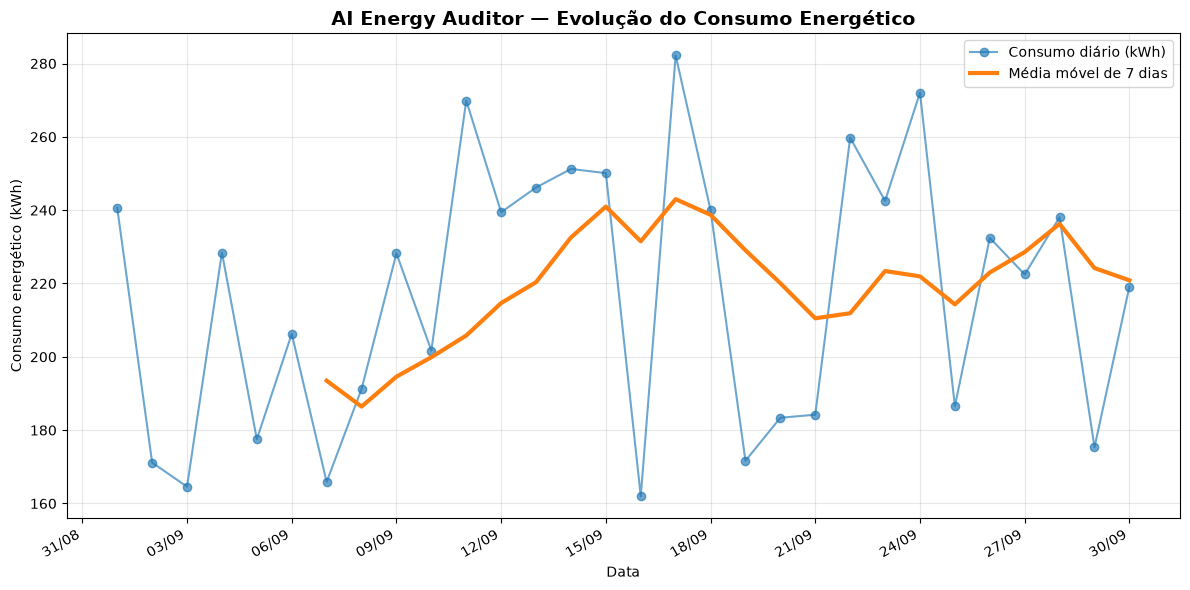

=== VALIDAÇÃO ===
Gráfico temporal gerado com sucesso.
Período analisado: 01/09/2026 a 30/09/2026


In [24]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. Criar figura
fig, ax = plt.subplots(figsize=(12, 6))

# 2. Plotar consumo diário
ax.plot(
    df_temporal["data"],
    df_temporal["consumo_kwh"],
    marker="o",
    linewidth=1.5,
    alpha=0.65,
    label="Consumo diário (kWh)"
)

# 3. Plotar média móvel de 7 dias
ax.plot(
    df_temporal["data"],
    df_temporal["media_movel_7d"],
    linewidth=3,
    label="Média móvel de 7 dias"
)

# 4. Configurar título e eixos
ax.set_title(
    "AI Energy Auditor — Evolução do Consumo Energético",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Data")
ax.set_ylabel("Consumo energético (kWh)")

# 5. Formatar datas no eixo horizontal
ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m")
)

# 6. Adicionar grade e legenda
ax.grid(True, alpha=0.3)
ax.legend()

# 7. Ajustar apresentação
fig.autofmt_xdate()
plt.tight_layout()

# 8. Exibir gráfico
plt.show()

print("=== VALIDAÇÃO ===")
print("Gráfico temporal gerado com sucesso.")
print(
    "Período analisado:",
    df_temporal["data"].min().strftime("%d/%m/%Y"),
    "a",
    df_temporal["data"].max().strftime("%d/%m/%Y")
)


SEMANA 02 — EXERCÍCIO 39 — ETAPA 3. 
Desvio percentual em relação à média móvel



In [25]:
import numpy as np
import pandas as pd

# 1. Calcular o desvio percentual
df_temporal["desvio_media_movel_pct"] = (
    (
        df_temporal["consumo_kwh"]
        - df_temporal["media_movel_7d"]
    )
    / df_temporal["media_movel_7d"]
) * 100

# 2. Selecionar somente dias com média móvel disponível
df_desvios = df_temporal.dropna(
    subset=["desvio_media_movel_pct"]
).copy()

# 3. Identificar maiores desvios positivos e negativos
maior_desvio = df_desvios.loc[
    df_desvios["desvio_media_movel_pct"].idxmax()
]

menor_desvio = df_desvios.loc[
    df_desvios["desvio_media_movel_pct"].idxmin()
]

print("=== ANÁLISE DE DESVIOS DA MÉDIA MÓVEL ===")

print(
    "Maior desvio positivo:",
    maior_desvio["data"].strftime("%d/%m/%Y"),
    f'{maior_desvio["desvio_media_movel_pct"]:.2f}%'
)

print(
    "Maior desvio negativo:",
    menor_desvio["data"].strftime("%d/%m/%Y"),
    f'{menor_desvio["desvio_media_movel_pct"]:.2f}%'
)

# 4. Exibir os cinco maiores desvios absolutos
df_ranking = df_desvios.copy()

df_ranking["desvio_absoluto_pct"] = (
    df_ranking["desvio_media_movel_pct"].abs()
)

df_ranking = df_ranking.nlargest(
    5,
    "desvio_absoluto_pct"
)

df_ranking["data"] = (
    df_ranking["data"].dt.strftime("%d/%m/%Y")
)

colunas_relatorio = [
    "data",
    "horas_operacao",
    "consumo_kwh",
    "media_movel_7d",
    "desvio_media_movel_pct"
]

print("\n=== CINCO MAIORES DESVIOS ABSOLUTOS ===")

print(
    df_ranking[colunas_relatorio]
    .round({
        "consumo_kwh": 2,
        "media_movel_7d": 2,
        "desvio_media_movel_pct": 2
    })
    .to_string(index=False)
)

# 5. Validação
print("\n=== VALIDAÇÃO ===")

print(f"Registros com desvio calculado: {len(df_desvios)}")

assert len(df_desvios) == 24

assert np.isfinite(
    df_desvios["desvio_media_movel_pct"]
).all()

print("Validação dos desvios: APROVADA")


=== ANÁLISE DE DESVIOS DA MÉDIA MÓVEL ===
Maior desvio positivo: 11/09/2026 31.14%
Maior desvio negativo: 16/09/2026 -30.04%

=== CINCO MAIORES DESVIOS ABSOLUTOS ===
      data  horas_operacao  consumo_kwh  media_movel_7d  desvio_media_movel_pct
11/09/2026              11       269.90          205.81                   31.14
16/09/2026               7       161.97          231.50                  -30.04
19/09/2026               6       171.65          229.05                  -25.06
22/09/2026              12       259.77          211.89                   22.60
24/09/2026              12       272.08          221.94                   22.59

=== VALIDAÇÃO ===
Registros com desvio calculado: 24
Validação dos desvios: APROVADA


SEMANA 02 — EXERCÍCIO 39 — ETAPA 4.
Referência temporal baseada nos 7 dias anteriores

In [26]:
import numpy as np
import pandas as pd

# 1. Criar a média dos 7 dias anteriores
# shift(1) exclui o dia atual do cálculo
df_temporal["media_7d_anterior"] = (
    df_temporal["consumo_kwh"]
    .shift(1)
    .rolling(window=7, min_periods=7)
    .mean()
)

# 2. Calcular o desvio percentual da referência histórica
df_temporal["desvio_historico_pct"] = (
    (
        df_temporal["consumo_kwh"]
        - df_temporal["media_7d_anterior"]
    )
    / df_temporal["media_7d_anterior"]
) * 100

# 3. Selecionar registros com histórico suficiente
df_historico = df_temporal.dropna(
    subset=["desvio_historico_pct"]
).copy()

# 4. Comparar as duas abordagens
print("=== COMPARAÇÃO DAS MÉDIAS TEMPORAIS ===")

df_comparacao = df_temporal[
    [
        "data",
        "consumo_kwh",
        "media_movel_7d",
        "media_7d_anterior",
        "desvio_historico_pct"
    ]
].tail(10).copy()

df_comparacao["data"] = (
    df_comparacao["data"].dt.strftime("%d/%m/%Y")
)

print(
    df_comparacao.round({
        "consumo_kwh": 2,
        "media_movel_7d": 2,
        "media_7d_anterior": 2,
        "desvio_historico_pct": 2
    }).to_string(index=False)
)

# 5. Validar a quantidade de registros
print("\n=== VALIDAÇÃO ===")

print(f"Total de registros: {len(df_temporal)}")

print(
    "Referências históricas válidas:",
    df_temporal["media_7d_anterior"].notna().sum()
)

print(
    "Registros iniciais sem histórico suficiente:",
    df_temporal["media_7d_anterior"].isna().sum()
)

# 6. Validar o último valor matematicamente
media_manual = (
    df_temporal["consumo_kwh"]
    .iloc[-8:-1]
    .mean()
)

media_calculada = (
    df_temporal["media_7d_anterior"].iloc[-1]
)

assert np.isclose(
    media_manual,
    media_calculada,
    rtol=1e-10,
    atol=1e-10
)

print("Referência temporal sem o dia atual: APROVADA")


=== COMPARAÇÃO DAS MÉDIAS TEMPORAIS ===
      data  consumo_kwh  media_movel_7d  media_7d_anterior  desvio_historico_pct
21/09/2026       184.21          210.50             220.08                -16.30
22/09/2026       259.77          211.89             210.50                 23.40
23/09/2026       242.51          223.39             211.89                 14.45
24/09/2026       272.08          221.94             223.39                 21.79
25/09/2026       186.52          214.30             221.94                -15.96
26/09/2026       232.45          222.99             214.30                  8.47
27/09/2026       222.46          228.57             222.99                 -0.24
28/09/2026       238.09          236.27             228.57                  4.16
29/09/2026       175.33          224.21             236.27                -25.79
30/09/2026       219.13          220.87             224.21                 -2.27

=== VALIDAÇÃO ===
Total de registros: 30
Referências históricas váli

SEMANA 02 — EXERCÍCIO 39 — ETAPA 5.
Avaliação de baseline temporal de 7 dias


In [28]:
import numpy as np
import pandas as pd

# 1. Selecionar apenas os dias com previsão disponível
df_avaliacao = df_temporal.dropna(
    subset=["media_7d_anterior"]
).copy()

# 2. Definir valores reais e previstos
y_real = df_avaliacao["consumo_kwh"].to_numpy()

y_previsto = (
    df_avaliacao["media_7d_anterior"].to_numpy()
)

# 3. Calcular os erros
erros = y_real - y_previsto
erros_absolutos = np.abs(erros)

# 4. Calcular MAE
mae = np.mean(erros_absolutos)

# 5. Calcular RMSE
rmse = np.sqrt(np.mean(erros ** 2))

# 6. Calcular MAPE
# A métrica exige consumos reais diferentes de zero
if np.any(y_real == 0):
    mape = np.nan
    print("MAPE indisponível: existem consumos reais iguais a zero.")
else:
    mape = np.mean(
        erros_absolutos / np.abs(y_real)
    ) * 100

# 7. Exibir métricas
print("=== BASELINE TEMPORAL — MÉDIA DOS 7 DIAS ANTERIORES ===")

print(f"Observações avaliadas: {len(y_real)}")
print(f"MAE: {mae:.4f} kWh")
print(f"RMSE: {rmse:.4f} kWh")
print(f"MAPE: {mape:.2f}%")

# 8. Verificar consistência
print("\n=== VALIDAÇÃO ===")

assert len(y_real) == 23
assert len(y_previsto) == 23
assert np.isfinite(mae)
assert np.isfinite(rmse)
assert rmse >= mae

print("Avaliação temporal: APROVADA")


=== BASELINE TEMPORAL — MÉDIA DOS 7 DIAS ANTERIORES ===
Observações avaliadas: 23
MAE: 33.6656 kWh
RMSE: 40.6111 kWh
MAPE: 15.83%

=== VALIDAÇÃO ===
Avaliação temporal: APROVADA



SEMANA 02 — EXERCÍCIO 40 — ETAPA 1. 
Diagnóstico dos erros da baseline temporal



In [29]:
import numpy as np
import pandas as pd

# 1. Criar uma cópia dos dados avaliados
df_erros = df_avaliacao.copy()

# 2. Calcular o erro com sinal
df_erros["erro_kwh"] = (
    df_erros["consumo_kwh"]
    - df_erros["media_7d_anterior"]
)

# 3. Calcular o erro absoluto
df_erros["erro_absoluto_kwh"] = (
    df_erros["erro_kwh"].abs()
)

# 4. Calcular o erro percentual absoluto
df_erros["erro_percentual_absoluto"] = (
    df_erros["erro_absoluto_kwh"]
    / df_erros["consumo_kwh"].replace(0, np.nan)
) * 100

# 5. Identificar os cinco maiores erros absolutos
df_maiores_erros = (
    df_erros
    .nlargest(5, "erro_absoluto_kwh")
    .copy()
)

# 6. Formatar datas somente para apresentação
df_maiores_erros["data"] = (
    df_maiores_erros["data"].dt.strftime("%d/%m/%Y")
)

print("=== CINCO MAIORES ERROS DA BASELINE ===")

colunas = [
    "data",
    "horas_operacao",
    "consumo_kwh",
    "media_7d_anterior",
    "erro_kwh",
    "erro_absoluto_kwh",
    "erro_percentual_absoluto"
]

print(
    df_maiores_erros[colunas]
    .round({
        "consumo_kwh": 2,
        "media_7d_anterior": 2,
        "erro_kwh": 2,
        "erro_absoluto_kwh": 2,
        "erro_percentual_absoluto": 2
    })
    .to_string(index=False)
)

# 7. Validar o diagnóstico
print("\n=== VALIDAÇÃO ===")

assert len(df_erros) == 23
assert len(df_maiores_erros) == 5

assert np.isclose(
    df_erros["erro_absoluto_kwh"].mean(),
    mae,
    rtol=1e-10,
    atol=1e-10
)

print("Registros avaliados:", len(df_erros))
print("Consistência com o MAE: APROVADA")


=== CINCO MAIORES ERROS DA BASELINE ===
      data  horas_operacao  consumo_kwh  media_7d_anterior  erro_kwh  erro_absoluto_kwh  erro_percentual_absoluto
16/09/2026               7       161.97             240.97    -79.00              79.00                     48.78
11/09/2026              11       269.90             199.89     70.01              70.01                     25.94
19/09/2026               6       171.65             238.74    -67.08              67.08                     39.08
29/09/2026               6       175.33             236.27    -60.94              60.94                     34.76
17/09/2026              12       282.22             231.50     50.71              50.71                     17.97

=== VALIDAÇÃO ===
Registros avaliados: 23
Consistência com o MAE: APROVADA


SEMANA 02 — EXERCÍCIO 40 — ETAPA 2.
Relação entre horas de operação e erros da baseline

=== RELAÇÃO ENTRE HORAS E ERROS ===
Correlação de Pearson: 0.8937

=== ERROS POR HORAS DE OPERAÇÃO ===
 horas_operacao  quantidade  erro_medio_kwh  mae_kwh
              6           2          -64.01    64.01
              7           3          -50.10    50.10
              8           3          -13.61    18.36
              9           1           -5.08     5.08
             10           5           17.59    18.99
             11           5           32.26    32.26
             12           4           44.89    44.89


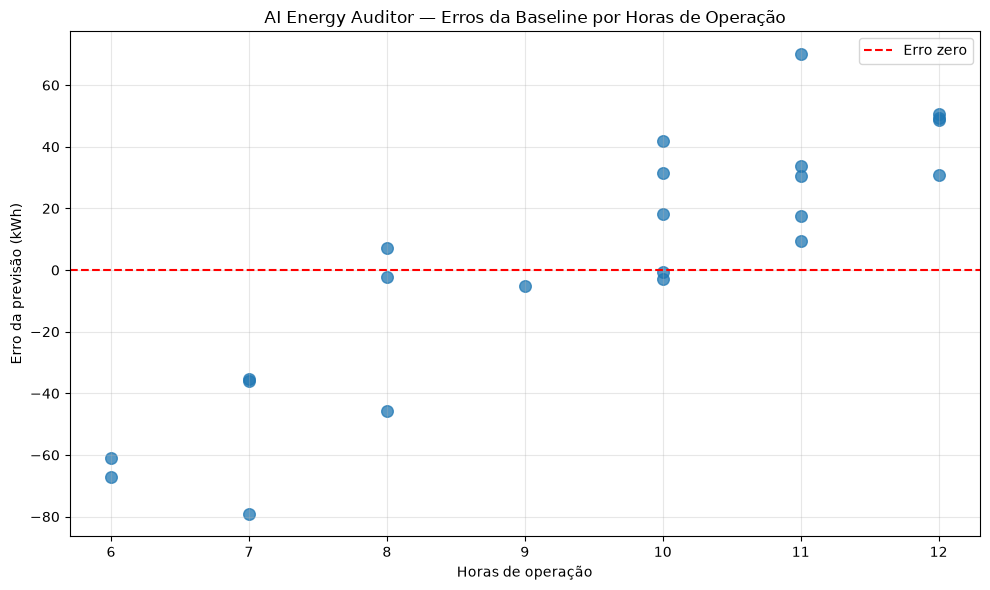


=== VALIDAÇÃO ===
Registros analisados: 23
Correlação e agrupamento: APROVADOS


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Calcular a correlação de Pearson
correlacao = df_erros[
    "horas_operacao"
].corr(
    df_erros["erro_kwh"]
)

# 2. Agrupar os erros por horas de operação
resumo_horas = (
    df_erros
    .groupby("horas_operacao")
    .agg(
        quantidade=("erro_kwh", "size"),
        erro_medio_kwh=("erro_kwh", "mean"),
        mae_kwh=("erro_absoluto_kwh", "mean")
    )
    .reset_index()
)

print("=== RELAÇÃO ENTRE HORAS E ERROS ===")
print(f"Correlação de Pearson: {correlacao:.4f}")

print("\n=== ERROS POR HORAS DE OPERAÇÃO ===")

print(
    resumo_horas.round({
        "erro_medio_kwh": 2,
        "mae_kwh": 2
    }).to_string(index=False)
)

# 3. Criar gráfico de dispersão
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    df_erros["horas_operacao"],
    df_erros["erro_kwh"],
    alpha=0.75,
    s=70
)

# Linha de referência: erro igual a zero
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Erro zero"
)

ax.set_title(
    "AI Energy Auditor — Erros da Baseline por Horas de Operação"
)

ax.set_xlabel("Horas de operação")
ax.set_ylabel("Erro da previsão (kWh)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# 4. Validação
print("\n=== VALIDAÇÃO ===")

assert len(df_erros) == 23
assert np.isfinite(correlacao)
assert -1 <= correlacao <= 1

assert resumo_horas["quantidade"].sum() == 23

print("Registros analisados: 23")
print("Correlação e agrupamento: APROVADOS")


SEMANA 02 — EXERCÍCIO 40 — ETAPA 3.
Separação cronológica para comparação de modelos


In [31]:
import pandas as pd

# 1. Preparar os dados em ordem cronológica
df_modelagem = (
    df_erros
    .sort_values("data")
    .reset_index(drop=True)
    .copy()
)

# 2. Definir o tamanho do conjunto de teste
n_teste = 7

# 3. Separar treino e teste sem embaralhamento
df_treino = df_modelagem.iloc[:-n_teste].copy()
df_teste = df_modelagem.iloc[-n_teste:].copy()

# 4. Exibir os períodos
print("=== DIVISÃO TEMPORAL ===")

print(f"Registros disponíveis: {len(df_modelagem)}")
print(f"Registros de treinamento: {len(df_treino)}")
print(f"Registros de teste: {len(df_teste)}")

print(
    "\nTreinamento:",
    df_treino["data"].min().strftime("%d/%m/%Y"),
    "até",
    df_treino["data"].max().strftime("%d/%m/%Y")
)

print(
    "Teste:",
    df_teste["data"].min().strftime("%d/%m/%Y"),
    "até",
    df_teste["data"].max().strftime("%d/%m/%Y")
)

# 5. Verificar a separação cronológica
assert len(df_treino) == 16
assert len(df_teste) == 7

assert (
    df_treino["data"].max()
    < df_teste["data"].min()
)

assert (
    set(df_treino["data"])
    .isdisjoint(set(df_teste["data"]))
)

# 6. Calcular a baseline somente no período de teste
erros_baseline_teste = (
    df_teste["consumo_kwh"]
    - df_teste["media_7d_anterior"]
)

mae_baseline_teste = (
    erros_baseline_teste.abs().mean()
)

rmse_baseline_teste = (
    (erros_baseline_teste.pow(2).mean()) ** 0.5
)

print("\n=== BASELINE NO PERÍODO DE TESTE ===")
print(f"MAE: {mae_baseline_teste:.4f} kWh")
print(f"RMSE: {rmse_baseline_teste:.4f} kWh")

print("\n=== VALIDAÇÃO ===")
print("Separação cronológica: APROVADA")
print("Baseline de teste calculada: APROVADA")


=== DIVISÃO TEMPORAL ===
Registros disponíveis: 23
Registros de treinamento: 16
Registros de teste: 7

Treinamento: 08/09/2026 até 23/09/2026
Teste: 24/09/2026 até 30/09/2026

=== BASELINE NO PERÍODO DE TESTE ===
MAE: 25.4741 kWh
RMSE: 33.3481 kWh

=== VALIDAÇÃO ===
Separação cronológica: APROVADA
Baseline de teste calculada: APROVADA


SEMANA 02 — EXERCÍCIO 40 — ETAPA 4
Regressão linear com separação temporal

In [33]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Definir a variável explicativa e o alvo
X_treino = df_treino[["horas_operacao"]]
y_treino = df_treino["consumo_kwh"]

X_teste = df_teste[["horas_operacao"]]
y_teste = df_teste["consumo_kwh"]

# 2. Criar o modelo
modelo_regressao = LinearRegression()

# 3. Treinar exclusivamente com dados anteriores ao teste
modelo_regressao.fit(X_treino, y_treino)

# 4. Gerar previsões para o período de teste
previsoes_regressao = modelo_regressao.predict(X_teste)

# 5. Calcular as métricas
mae_regressao = mean_absolute_error(
    y_teste,
    previsoes_regressao
)

rmse_regressao = np.sqrt(
    mean_squared_error(
        y_teste,
        previsoes_regressao
    )
)

# 6. Exibir os parâmetros aprendidos
print("=== MODELO DE REGRESSÃO LINEAR ===")

print(
    f"Intercepto: {modelo_regressao.intercept_:.4f}"
)

print(
    "Coeficiente das horas:",
    f"{modelo_regressao.coef_[0]:.4f}"
)

print("\n=== DESEMPENHO NO PERÍODO DE TESTE ===")

print(f"MAE da regressão: {mae_regressao:.4f} kWh")
print(f"RMSE da regressão: {rmse_regressao:.4f} kWh")

# 7. Comparar com a baseline nos mesmos sete dias
print("\n=== COMPARAÇÃO JUSTA ===")

print(
    f"MAE baseline: {mae_baseline_teste:.4f} kWh"
)

print(
    f"MAE regressão: {mae_regressao:.4f} kWh"
)

print(
    f"RMSE baseline: {rmse_baseline_teste:.4f} kWh"
)

print(
    f"RMSE regressão: {rmse_regressao:.4f} kWh"
)

# 8. Calcular a redução percentual dos erros
reducao_mae = (
    (mae_baseline_teste - mae_regressao)
    / mae_baseline_teste
) * 100

reducao_rmse = (
    (rmse_baseline_teste - rmse_regressao)
    / rmse_baseline_teste
) * 100

print("\n=== REDUÇÃO DOS ERROS ===")

print(f"Redução do MAE: {reducao_mae:.2f}%")
print(f"Redução do RMSE: {reducao_rmse:.2f}%")

# 9. Validar a execução
print("\n=== VALIDAÇÃO ===")

assert len(previsoes_regressao) == len(df_teste)
assert np.isfinite(previsoes_regressao).all()
assert np.isfinite(mae_regressao)
assert np.isfinite(rmse_regressao)

print("Treinamento e avaliação: APROVADOS")


=== MODELO DE REGRESSÃO LINEAR ===
Intercepto: 54.1453
Coeficiente das horas: 17.7752

=== DESEMPENHO NO PERÍODO DE TESTE ===
MAE da regressão: 7.6703 kWh
RMSE da regressão: 8.8188 kWh

=== COMPARAÇÃO JUSTA ===
MAE baseline: 25.4741 kWh
MAE regressão: 7.6703 kWh
RMSE baseline: 33.3481 kWh
RMSE regressão: 8.8188 kWh

=== REDUÇÃO DOS ERROS ===
Redução do MAE: 69.89%
Redução do RMSE: 73.56%

=== VALIDAÇÃO ===
Treinamento e avaliação: APROVADOS


SEMANA 02 — EXERCÍCIO 40 — ETAPA 5
Comparação diária das previsões dos dois modelos


In [34]:
import numpy as np
import pandas as pd

# 1. Criar relatório com os mesmos dias de teste
df_comparativo = df_teste[
    ["data", "horas_operacao", "consumo_kwh"]
].copy()

# 2. Adicionar previsões dos dois métodos
df_comparativo["previsao_baseline"] = (
    df_teste["media_7d_anterior"].to_numpy()
)

df_comparativo["previsao_regressao"] = (
    previsoes_regressao
)

# 3. Calcular erros absolutos
df_comparativo["erro_baseline"] = (
    df_comparativo["consumo_kwh"]
    - df_comparativo["previsao_baseline"]
).abs()

df_comparativo["erro_regressao"] = (
    df_comparativo["consumo_kwh"]
    - df_comparativo["previsao_regressao"]
).abs()

# 4. Identificar qual modelo teve menor erro em cada dia
df_comparativo["melhor_modelo"] = np.select(
    [
        df_comparativo["erro_regressao"]
        < df_comparativo["erro_baseline"],

        df_comparativo["erro_baseline"]
        < df_comparativo["erro_regressao"]
    ],
    [
        "Regressão",
        "Baseline"
    ],
    default="Empate"
)

# 5. Formatar apenas a cópia para apresentação
df_relatorio_comparativo = df_comparativo.copy()

df_relatorio_comparativo["data"] = (
    df_relatorio_comparativo["data"]
    .dt.strftime("%d/%m/%Y")
)

print("=== COMPARAÇÃO DIÁRIA DOS MODELOS ===")

print(
    df_relatorio_comparativo.round({
        "consumo_kwh": 2,
        "previsao_baseline": 2,
        "previsao_regressao": 2,
        "erro_baseline": 2,
        "erro_regressao": 2
    }).to_string(index=False)
)

# 6. Resumir os resultados
print("\n=== DESEMPENHO POR DIA ===")

print(
    df_comparativo["melhor_modelo"]
    .value_counts()
    .to_string()
)

# 7. Validar consistência das métricas
assert len(df_comparativo) == 7

assert np.isclose(
    df_comparativo["erro_baseline"].mean(),
    mae_baseline_teste
)

assert np.isclose(
    df_comparativo["erro_regressao"].mean(),
    mae_regressao
)

print("\n=== VALIDAÇÃO ===")
print("Comparação dos sete dias: APROVADA")
print("Consistência dos erros médios: APROVADA")


=== COMPARAÇÃO DIÁRIA DOS MODELOS ===
      data  horas_operacao  consumo_kwh  previsao_baseline  previsao_regressao  erro_baseline  erro_regressao melhor_modelo
24/09/2026              12       272.08             223.39              267.45          48.69            4.63     Regressão
25/09/2026               7       186.52             221.94              178.57          35.42            7.95     Regressão
26/09/2026              10       232.45             214.30              231.90          18.15            0.56     Regressão
27/09/2026              10       222.46             222.99              231.90           0.52            9.43      Baseline
28/09/2026              11       238.09             228.57              249.67           9.52           11.58      Baseline
29/09/2026               6       175.33             236.27              160.80          60.94           14.54     Regressão
30/09/2026               9       219.13             224.21              214.12           5.08 


## SEMANA 02 — EXERCÍCIO 41 — ETAPA 1.
### Preparação das janelas de validação Walk-Forward

In [36]:
import pandas as pd

# 1. Utilizar os dados cronologicamente ordenados
df_walk_forward = (
    df_modelagem
    .sort_values("data")
    .reset_index(drop=True)
    .copy()
)

# 2. Manter os últimos sete dias como período de avaliação
n_dias_teste = 7
inicio_teste = len(df_walk_forward) - n_dias_teste

# 3. Construir o calendário de janelas
janelas = []

for indice_teste in range(inicio_teste, len(df_walk_forward)):

    dados_treino = df_walk_forward.iloc[:indice_teste]
    dado_teste = df_walk_forward.iloc[indice_teste]

    janelas.append({
        "data_previsao": dado_teste["data"],
        "inicio_treino": dados_treino["data"].min(),
        "fim_treino": dados_treino["data"].max(),
        "registros_treino": len(dados_treino)
    })

# 4. Criar relatório das janelas
df_janelas = pd.DataFrame(janelas)

# 5. Formatar datas para apresentação
df_janelas_relatorio = df_janelas.copy()

for coluna in [
    "data_previsao",
    "inicio_treino",
    "fim_treino"
]:
    df_janelas_relatorio[coluna] = (
        df_janelas_relatorio[coluna]
        .dt.strftime("%d/%m/%Y")
    )

print("=== JANELAS DE VALIDAÇÃO WALK-FORWARD ===")

print(
    df_janelas_relatorio.to_string(index=False)
)

# 6. Validar as janelas
assert len(df_janelas) == 7

assert (
    df_janelas["fim_treino"]
    < df_janelas["data_previsao"]
).all()

assert (
    df_janelas["registros_treino"].tolist()
    == [16, 17, 18, 19, 20, 21, 22]
)

print("\n=== VALIDAÇÃO ===")
print("Total de janelas: 7")
print("Ordem cronológica: APROVADA")
print("Expansão progressiva do treinamento: APROVADA")


=== JANELAS DE VALIDAÇÃO WALK-FORWARD ===
data_previsao inicio_treino fim_treino  registros_treino
   24/09/2026    08/09/2026 23/09/2026                16
   25/09/2026    08/09/2026 24/09/2026                17
   26/09/2026    08/09/2026 25/09/2026                18
   27/09/2026    08/09/2026 26/09/2026                19
   28/09/2026    08/09/2026 27/09/2026                20
   29/09/2026    08/09/2026 28/09/2026                21
   30/09/2026    08/09/2026 29/09/2026                22

=== VALIDAÇÃO ===
Total de janelas: 7
Ordem cronológica: APROVADA
Expansão progressiva do treinamento: APROVADA


SEMANA 02 — EXERCÍCIO 41 — ETAPA 2.
Treinamento progressivo Walk-Forward

In [38]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# 1. Armazenar os resultados de cada previsão
resultados_walk_forward = []

# 2. Percorrer as sete janelas cronológicas
for indice_teste in range(
    inicio_teste,
    len(df_walk_forward)
):

    # 3. Selecionar somente dados anteriores ao teste
    dados_treino = df_walk_forward.iloc[
        :indice_teste
    ].copy()

    dados_teste = df_walk_forward.iloc[
        indice_teste:indice_teste + 1
    ].copy()

    # 4. Definir atributos e variável-alvo
    X_treino_wf = dados_treino[["horas_operacao"]]
    y_treino_wf = dados_treino["consumo_kwh"]

    X_teste_wf = dados_teste[["horas_operacao"]]

    # 5. Criar e treinar um novo modelo
    modelo_wf = LinearRegression()

    modelo_wf.fit(
        X_treino_wf,
        y_treino_wf
    )

    # 6. Prever o consumo do dia seguinte
    previsao = float(
        modelo_wf.predict(X_teste_wf)[0]
    )

    consumo_real = float(
        dados_teste["consumo_kwh"].iloc[0]
    )

    # 7. Registrar o resultado
    resultados_walk_forward.append({
        "data": dados_teste["data"].iloc[0],
        "registros_treino": len(dados_treino),
        "horas_operacao": int(
            dados_teste["horas_operacao"].iloc[0]
        ),
        "consumo_real_kwh": consumo_real,
        "previsao_kwh": previsao,
        "erro_kwh": consumo_real - previsao,
        "erro_absoluto_kwh": abs(
            consumo_real - previsao
        )
    })

# 8. Consolidar os resultados
df_resultados_wf = pd.DataFrame(
    resultados_walk_forward
)

# 9. Preparar relatório sem alterar os dados numéricos
df_relatorio_wf = df_resultados_wf.copy()

df_relatorio_wf["data"] = (
    df_relatorio_wf["data"]
    .dt.strftime("%d/%m/%Y")
)

print("=== RESULTADOS WALK-FORWARD ===")

print(
    df_relatorio_wf.round({
        "consumo_real_kwh": 2,
        "previsao_kwh": 2,
        "erro_kwh": 2,
        "erro_absoluto_kwh": 2
    }).to_string(index=False)
)

# 10. Validar o processo
print("\n=== VALIDAÇÃO ===")

assert len(df_resultados_wf) == 7

assert (
    df_resultados_wf["registros_treino"].tolist()
    == [16, 17, 18, 19, 20, 21, 22]
)

assert np.isfinite(
    df_resultados_wf["previsao_kwh"]
).all()

print("Previsões realizadas: 7")
print("Treinamento progressivo: APROVADO")
print("Previsões numéricas válidas: APROVADAS")


=== RESULTADOS WALK-FORWARD ===
      data  registros_treino  horas_operacao  consumo_real_kwh  previsao_kwh  erro_kwh  erro_absoluto_kwh
24/09/2026                16              12            272.08        267.45      4.63               4.63
25/09/2026                17               7            186.52        178.40      8.12               8.12
26/09/2026                18              10            232.45        232.54     -0.09               0.09
27/09/2026                19              10            222.46        232.54    -10.07              10.07
28/09/2026                20              11            238.09        249.61    -11.52              11.52
29/09/2026                21               6            175.33        161.84     13.49              13.49
30/09/2026                22               9            219.13        214.93      4.20               4.20

=== VALIDAÇÃO ===
Previsões realizadas: 7
Treinamento progressivo: APROVADO
Previsões numéricas válidas: APROVADAS


SEMANA 02 — EXERCÍCIO 41 — ETAPA 3
Avaliação comparativa do Walk-Forward

In [39]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Selecionar valores reais e previsões progressivas
y_real_wf = df_resultados_wf["consumo_real_kwh"].to_numpy()
y_previsto_wf = df_resultados_wf["previsao_kwh"].to_numpy()

# 2. Calcular métricas Walk-Forward
mae_wf = mean_absolute_error(
    y_real_wf,
    y_previsto_wf
)

rmse_wf = np.sqrt(
    mean_squared_error(
        y_real_wf,
        y_previsto_wf
    )
)

# 3. Consolidar resultados dos três métodos
df_metricas = pd.DataFrame({
    "modelo": [
        "Baseline histórica",
        "Regressão fixa",
        "Regressão Walk-Forward"
    ],
    "MAE_kWh": [
        mae_baseline_teste,
        mae_regressao,
        mae_wf
    ],
    "RMSE_kWh": [
        rmse_baseline_teste,
        rmse_regressao,
        rmse_wf
    ]
})

# 4. Ordenar pelo menor MAE
df_metricas = (
    df_metricas
    .sort_values("MAE_kWh")
    .reset_index(drop=True)
)

print("=== COMPARAÇÃO DOS TRÊS MÉTODOS ===")

print(
    df_metricas.round({
        "MAE_kWh": 4,
        "RMSE_kWh": 4
    }).to_string(index=False)
)

# 5. Comparar Walk-Forward com regressão fixa
diferenca_mae = mae_regressao - mae_wf
diferenca_rmse = rmse_regressao - rmse_wf

print("\n=== WALK-FORWARD VERSUS REGRESSÃO FIXA ===")

print(
    f"Diferença de MAE (fixa - WF): "
    f"{diferenca_mae:+.4f} kWh"
)

print(
    f"Diferença de RMSE (fixa - WF): "
    f"{diferenca_rmse:+.4f} kWh"
)

# 6. Calcular melhoria percentual frente à baseline
melhoria_mae_wf = (
    (mae_baseline_teste - mae_wf)
    / mae_baseline_teste
) * 100

melhoria_rmse_wf = (
    (rmse_baseline_teste - rmse_wf)
    / rmse_baseline_teste
) * 100

print("\n=== WALK-FORWARD VERSUS BASELINE ===")

print(f"Redução do MAE: {melhoria_mae_wf:.2f}%")
print(f"Redução do RMSE: {melhoria_rmse_wf:.2f}%")

# 7. Validar consistência
print("\n=== VALIDAÇÃO ===")

assert len(y_real_wf) == 7
assert len(df_metricas) == 3

assert np.allclose(
    y_real_wf,
    df_teste["consumo_kwh"].to_numpy()
)

assert np.isfinite(
    df_metricas[["MAE_kWh", "RMSE_kWh"]].to_numpy()
).all()

assert rmse_wf >= mae_wf

print("Mesmo período de avaliação: APROVADO")
print("Métricas dos três métodos: APROVADAS")


=== COMPARAÇÃO DOS TRÊS MÉTODOS ===
                modelo  MAE_kWh  RMSE_kWh
Regressão Walk-Forward   7.4455    8.6282
        Regressão fixa   7.6703    8.8188
    Baseline histórica  25.4741   33.3481

=== WALK-FORWARD VERSUS REGRESSÃO FIXA ===
Diferença de MAE (fixa - WF): +0.2248 kWh
Diferença de RMSE (fixa - WF): +0.1906 kWh

=== WALK-FORWARD VERSUS BASELINE ===
Redução do MAE: 70.77%
Redução do RMSE: 74.13%

=== VALIDAÇÃO ===
Mesmo período de avaliação: APROVADO
Métricas dos três métodos: APROVADAS


SEMANA 02 — EXERCÍCIO 41 — ETAPA 4
Consistência da melhoria com Walk-Forward

In [40]:
import numpy as np
import pandas as pd

# 1. Conferir alinhamento cronológico
datas_fixa = df_comparativo["data"].reset_index(drop=True)
datas_wf = df_resultados_wf["data"].reset_index(drop=True)

assert datas_fixa.equals(datas_wf), (
    "As datas dos dois métodos não estão alinhadas."
)

# 2. Construir relatório comparativo
df_consistencia = pd.DataFrame({
    "data": datas_fixa,
    "consumo_real_kwh": (
        df_comparativo["consumo_kwh"].to_numpy()
    ),
    "erro_fixa_kwh": (
        df_comparativo["erro_regressao"].to_numpy()
    ),
    "erro_wf_kwh": (
        df_resultados_wf["erro_absoluto_kwh"].to_numpy()
    )
})

# 3. Calcular vantagem diária do Walk-Forward
# Valor positivo: Walk-Forward errou menos
# Valor negativo: regressão fixa errou menos
df_consistencia["vantagem_wf_kwh"] = (
    df_consistencia["erro_fixa_kwh"]
    - df_consistencia["erro_wf_kwh"]
)

# 4. Identificar o método com menor erro
df_consistencia["melhor_metodo"] = np.select(
    [
        df_consistencia["vantagem_wf_kwh"] > 1e-9,
        df_consistencia["vantagem_wf_kwh"] < -1e-9
    ],
    [
        "Walk-Forward",
        "Regressão fixa"
    ],
    default="Empate"
)

# 5. Preparar apresentação
df_consistencia_relatorio = df_consistencia.copy()

df_consistencia_relatorio["data"] = (
    df_consistencia_relatorio["data"]
    .dt.strftime("%d/%m/%Y")
)

print("=== CONSISTÊNCIA DA MELHORIA ===")

print(
    df_consistencia_relatorio.round({
        "consumo_real_kwh": 2,
        "erro_fixa_kwh": 2,
        "erro_wf_kwh": 2,
        "vantagem_wf_kwh": 2
    }).to_string(index=False)
)

# 6. Contar os dias vencidos por cada método
print("\n=== RESULTADO POR DIA ===")

print(
    df_consistencia["melhor_metodo"]
    .value_counts()
    .to_string()
)

# 7. Resumir a vantagem média
vantagem_media_wf = (
    df_consistencia["vantagem_wf_kwh"].mean()
)

print("\n=== VANTAGEM MÉDIA DO WALK-FORWARD ===")

print(f"{vantagem_media_wf:+.4f} kWh")

# 8. Validar consistência com as métricas anteriores
print("\n=== VALIDAÇÃO ===")

assert len(df_consistencia) == 7

assert np.isclose(
    vantagem_media_wf,
    mae_regressao - mae_wf
)

assert np.isfinite(
    df_consistencia["vantagem_wf_kwh"]
).all()

print("Datas alinhadas: APROVADO")
print("Comparação diária: APROVADA")
print("Consistência com o MAE: APROVADA")


=== CONSISTÊNCIA DA MELHORIA ===
      data  consumo_real_kwh  erro_fixa_kwh  erro_wf_kwh  vantagem_wf_kwh  melhor_metodo
24/09/2026            272.08           4.63         4.63             0.00         Empate
25/09/2026            186.52           7.95         8.12            -0.17 Regressão fixa
26/09/2026            232.45           0.56         0.09             0.47   Walk-Forward
27/09/2026            222.46           9.43        10.07            -0.64 Regressão fixa
28/09/2026            238.09          11.58        11.52             0.06   Walk-Forward
29/09/2026            175.33          14.54        13.49             1.05   Walk-Forward
30/09/2026            219.13           5.01         4.20             0.81   Walk-Forward

=== RESULTADO POR DIA ===
melhor_metodo
Walk-Forward      4
Regressão fixa    2
Empate            1

=== VANTAGEM MÉDIA DO WALK-FORWARD ===
+0.2248 kWh

=== VALIDAÇÃO ===
Datas alinhadas: APROVADO
Comparação diária: APROVADA
Consistência com o MAE: APROV

## SEMANA 02 — EXERCÍCIO 42 — ETAPA 1
### Análise dos resíduos do Walk-Forward

=== ESTATÍSTICAS DOS RESÍDUOS ===
Resíduo médio: +1.2498 kWh
Resíduo mediano: +4.1960 kWh
Desvio-padrão: 9.2212 kWh

=== DIREÇÃO DOS ERROS ===
Subestimações: 4
Superestimações: 3
Previsões exatas: 0


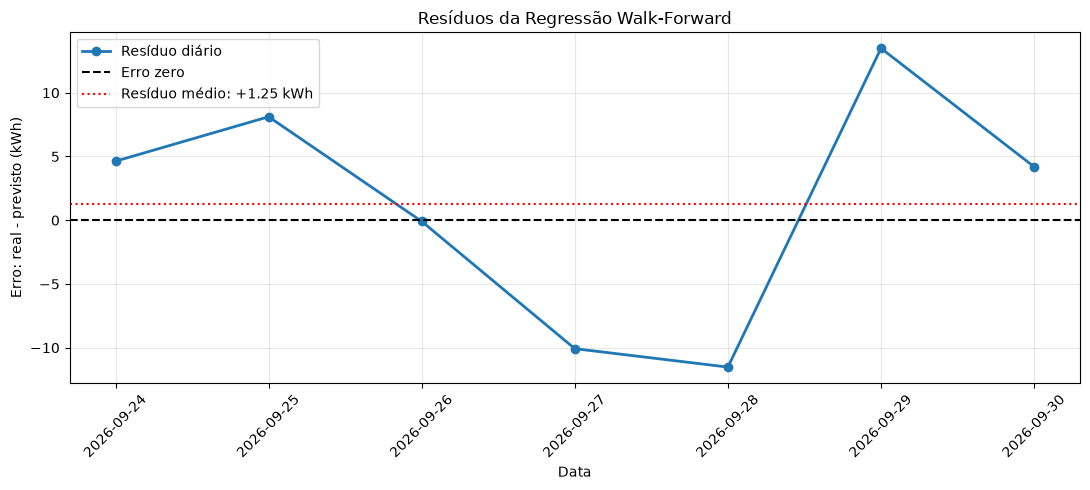


=== VALIDAÇÃO ===
Resíduos calculados: APROVADOS
Contagem dos erros: APROVADA
Consistência com o MAE: APROVADA


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Criar dataset de análise dos resíduos
df_residuos = df_resultados_wf[
    [
        "data",
        "horas_operacao",
        "consumo_real_kwh",
        "previsao_kwh",
        "erro_kwh"
    ]
].copy()

# 2. Calcular estatísticas dos resíduos
residuo_medio = df_residuos["erro_kwh"].mean()
residuo_mediano = df_residuos["erro_kwh"].median()
desvio_padrao = df_residuos["erro_kwh"].std()

# 3. Contar subestimações e superestimações
n_subestimacoes = (df_residuos["erro_kwh"] > 0).sum()
n_superestimacoes = (df_residuos["erro_kwh"] < 0).sum()
n_exatas = (df_residuos["erro_kwh"] == 0).sum()

print("=== ESTATÍSTICAS DOS RESÍDUOS ===")

print(f"Resíduo médio: {residuo_medio:+.4f} kWh")
print(f"Resíduo mediano: {residuo_mediano:+.4f} kWh")
print(f"Desvio-padrão: {desvio_padrao:.4f} kWh")

print("\n=== DIREÇÃO DOS ERROS ===")

print(f"Subestimações: {n_subestimacoes}")
print(f"Superestimações: {n_superestimacoes}")
print(f"Previsões exatas: {n_exatas}")

# 4. Visualizar os resíduos ao longo do tempo
plt.figure(figsize=(11, 5))

plt.plot(
    df_residuos["data"],
    df_residuos["erro_kwh"],
    marker="o",
    linewidth=2,
    label="Resíduo diário"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    label="Erro zero"
)

plt.axhline(
    y=residuo_medio,
    color="red",
    linestyle=":",
    label=f"Resíduo médio: {residuo_medio:+.2f} kWh"
)

plt.title("Resíduos da Regressão Walk-Forward")
plt.xlabel("Data")
plt.ylabel("Erro: real - previsto (kWh)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Validação
print("\n=== VALIDAÇÃO ===")

assert len(df_residuos) == 7

assert (
    n_subestimacoes
    + n_superestimacoes
    + n_exatas
) == 7

assert np.isfinite(
    df_residuos["erro_kwh"]
).all()

assert np.isclose(
    df_residuos["erro_kwh"].abs().mean(),
    mae_wf
)

print("Resíduos calculados: APROVADOS")
print("Contagem dos erros: APROVADA")
print("Consistência com o MAE: APROVADA")


SEMANA 02 — EXERCÍCIO 42 — ETAPA 2. 
Relação entre resíduos e horas de operação

=== CORRELAÇÃO ENTRE HORAS E RESÍDUOS ===
Correlação de Pearson: -0.6637

=== RESÍDUOS POR HORAS DE OPERAÇÃO ===
 horas_operacao  quantidade  residuo_medio_kwh  erro_absoluto_medio_kwh
              6           1            13.4898                  13.4898
              7           1             8.1167                   8.1167
              9           1             4.1960                   4.1960
             10           2            -5.0826                   5.0826
             11           1           -11.5198                  11.5198
             12           1             4.6312                   4.6312


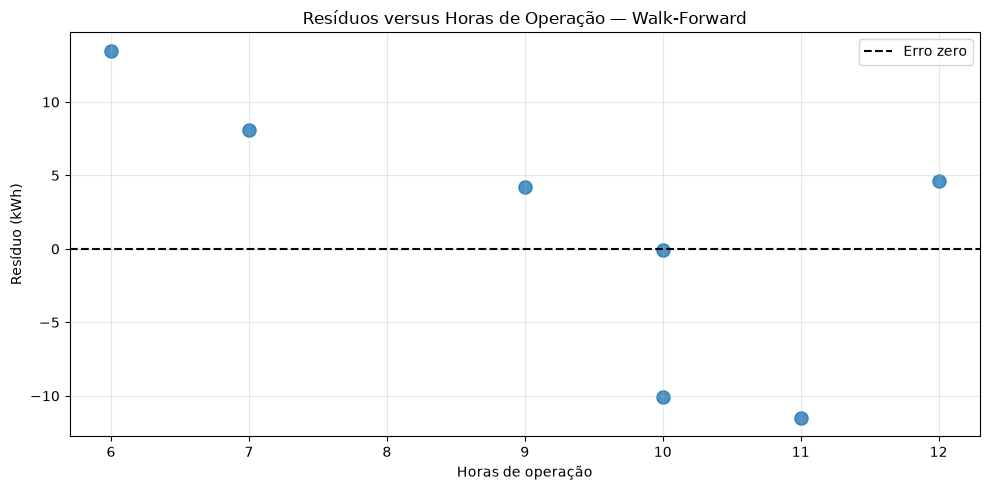


=== VALIDAÇÃO ===
Correlação calculada: APROVADA
Agrupamento por horas: APROVADO
Resíduos numéricos válidos: APROVADOS


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Calcular a correlação entre horas e resíduos
correlacao_residuos_horas = (
    df_residuos["horas_operacao"]
    .corr(df_residuos["erro_kwh"])
)

print("=== CORRELAÇÃO ENTRE HORAS E RESÍDUOS ===")

print(
    f"Correlação de Pearson: "
    f"{correlacao_residuos_horas:+.4f}"
)

# 2. Agrupar resíduos por horas de operação
df_residuos_por_hora = (
    df_residuos
    .groupby("horas_operacao")
    .agg(
        quantidade=("erro_kwh", "size"),
        residuo_medio_kwh=("erro_kwh", "mean"),
        erro_absoluto_medio_kwh=(
            "erro_kwh",
            lambda valores: valores.abs().mean()
        )
    )
    .reset_index()
)

print("\n=== RESÍDUOS POR HORAS DE OPERAÇÃO ===")

print(
    df_residuos_por_hora.round({
        "residuo_medio_kwh": 4,
        "erro_absoluto_medio_kwh": 4
    }).to_string(index=False)
)

# 3. Criar gráfico de dispersão
plt.figure(figsize=(10, 5))

plt.scatter(
    df_residuos["horas_operacao"],
    df_residuos["erro_kwh"],
    s=90,
    alpha=0.8
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    label="Erro zero"
)

plt.title(
    "Resíduos versus Horas de Operação — Walk-Forward"
)

plt.xlabel("Horas de operação")
plt.ylabel("Resíduo (kWh)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 4. Validar os resultados
print("\n=== VALIDAÇÃO ===")

assert len(df_residuos) == 7

assert df_residuos_por_hora["quantidade"].sum() == 7

assert np.isfinite(correlacao_residuos_horas)

assert np.isfinite(
    df_residuos_por_hora[
        [
            "residuo_medio_kwh",
            "erro_absoluto_medio_kwh"
        ]
    ].to_numpy()
).all()

print("Correlação calculada: APROVADA")
print("Agrupamento por horas: APROVADO")
print("Resíduos numéricos válidos: APROVADOS")



SEMANA 02 — EXERCÍCIO 42 — ETAPA 3.
Sensibilidade da correlação — Leave-One-Out



=== SENSIBILIDADE LEAVE-ONE-OUT ===
Correlação original: -0.6637
data_removida  horas_removidas  correlacao_sem_dia  variacao_absoluta
   24/09/2026               12             -0.9223             0.2586
   25/09/2026                7             -0.6109             0.0528
   26/09/2026               10             -0.6628             0.0009
   27/09/2026               10             -0.7023             0.0385
   28/09/2026               11             -0.6045             0.0592
   29/09/2026                6             -0.4479             0.2158
   30/09/2026                9             -0.6632             0.0005

=== OBSERVAÇÃO MAIS INFLUENTE ===
Data: 24/09/2026
Correlação sem esse dia: -0.9223
Variação absoluta: 0.2586


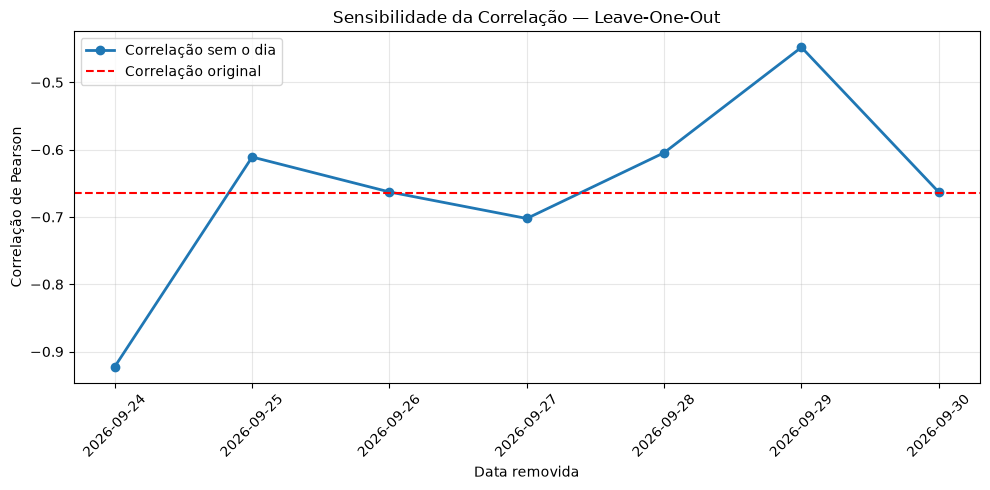


=== VALIDAÇÃO ===
Sete análises realizadas: APROVADAS
Correlações numéricas válidas: APROVADAS
Intervalo de Pearson respeitado: APROVADO


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Correlação original com os sete registros
correlacao_original = df_residuos[
    "horas_operacao"
].corr(
    df_residuos["erro_kwh"]
)

# 2. Recalcular a correlação retirando um dia por vez
resultados_sensibilidade = []

for indice in df_residuos.index:

    amostra_reduzida = df_residuos.drop(
        index=indice
    )

    correlacao_reduzida = (
        amostra_reduzida["horas_operacao"]
        .corr(amostra_reduzida["erro_kwh"])
    )

    resultados_sensibilidade.append({
        "data_removida": df_residuos.loc[indice, "data"],
        "horas_removidas": df_residuos.loc[
            indice, "horas_operacao"
        ],
        "correlacao_sem_dia": correlacao_reduzida,
        "variacao_absoluta": abs(
            correlacao_reduzida - correlacao_original
        )
    })

# 3. Consolidar resultados
df_sensibilidade = pd.DataFrame(
    resultados_sensibilidade
)

# 4. Preparar relatório
df_sensibilidade_relatorio = (
    df_sensibilidade.copy()
)

df_sensibilidade_relatorio["data_removida"] = (
    df_sensibilidade_relatorio["data_removida"]
    .dt.strftime("%d/%m/%Y")
)

print("=== SENSIBILIDADE LEAVE-ONE-OUT ===")

print(
    f"Correlação original: "
    f"{correlacao_original:+.4f}"
)

print(
    df_sensibilidade_relatorio.round({
        "correlacao_sem_dia": 4,
        "variacao_absoluta": 4
    }).to_string(index=False)
)

# 5. Identificar maior influência
indice_maior_influencia = (
    df_sensibilidade["variacao_absoluta"]
    .idxmax()
)

dia_mais_influente = df_sensibilidade.loc[
    indice_maior_influencia
]

print("\n=== OBSERVAÇÃO MAIS INFLUENTE ===")

print(
    "Data:",
    dia_mais_influente["data_removida"]
    .strftime("%d/%m/%Y")
)

print(
    "Correlação sem esse dia:",
    f"{dia_mais_influente['correlacao_sem_dia']:+.4f}"
)

print(
    "Variação absoluta:",
    f"{dia_mais_influente['variacao_absoluta']:.4f}"
)

# 6. Visualizar a sensibilidade
plt.figure(figsize=(10, 5))

plt.plot(
    df_sensibilidade["data_removida"],
    df_sensibilidade["correlacao_sem_dia"],
    marker="o",
    linewidth=2,
    label="Correlação sem o dia"
)

plt.axhline(
    correlacao_original,
    color="red",
    linestyle="--",
    label="Correlação original"
)

plt.title("Sensibilidade da Correlação — Leave-One-Out")
plt.xlabel("Data removida")
plt.ylabel("Correlação de Pearson")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Validar os resultados
print("\n=== VALIDAÇÃO ===")

assert len(df_sensibilidade) == 7

assert np.isfinite(
    df_sensibilidade[
        ["correlacao_sem_dia", "variacao_absoluta"]
    ].to_numpy()
).all()

assert (
    df_sensibilidade["correlacao_sem_dia"]
    .between(-1, 1)
).all()

print("Sete análises realizadas: APROVADAS")
print("Correlações numéricas válidas: APROVADAS")
print("Intervalo de Pearson respeitado: APROVADO")


SEMANA 02 — EXERCÍCIO 42 — ETAPA 4.
Autocorrelação dos resíduos — Lag 1

=== AUTOCORRELAÇÃO DOS RESÍDUOS ===
Pares consecutivos: 6
Autocorrelação lag 1: +0.1041

=== RESÍDUOS CONSECUTIVOS ===
      data  residuo_anterior_kwh  erro_kwh
25/09/2026                4.6312    8.1167
26/09/2026                8.1167   -0.0906
27/09/2026               -0.0906  -10.0746
28/09/2026              -10.0746  -11.5198
29/09/2026              -11.5198   13.4898
30/09/2026               13.4898    4.1960


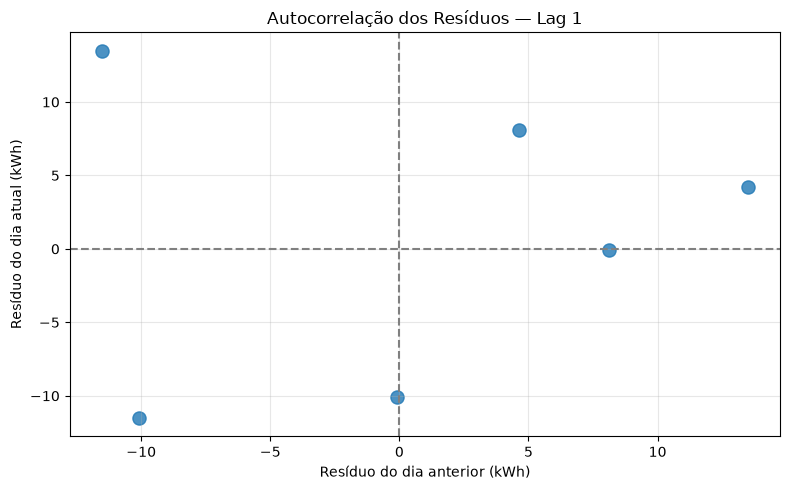


=== VALIDAÇÃO ===
Pares temporais: APROVADOS
Autocorrelação calculada: APROVADA
Consistência do cálculo: APROVADA


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Ordenar os resíduos cronologicamente
df_autocorrelacao = (
    df_residuos
    .sort_values("data")
    .reset_index(drop=True)
    .copy()
)

# 2. Criar a coluna com o resíduo do dia anterior
df_autocorrelacao["residuo_anterior_kwh"] = (
    df_autocorrelacao["erro_kwh"].shift(1)
)

# 3. Remover a primeira linha, sem dia anterior
df_pares_residuos = (
    df_autocorrelacao
    .dropna(
        subset=["residuo_anterior_kwh"]
    )
    .copy()
)

# 4. Calcular autocorrelação de lag 1
autocorrelacao_lag1 = (
    df_pares_residuos["erro_kwh"]
    .corr(
        df_pares_residuos["residuo_anterior_kwh"]
    )
)

print("=== AUTOCORRELAÇÃO DOS RESÍDUOS ===")

print(f"Pares consecutivos: {len(df_pares_residuos)}")

print(
    f"Autocorrelação lag 1: "
    f"{autocorrelacao_lag1:+.4f}"
)

# 5. Preparar relatório
df_pares_relatorio = df_pares_residuos[
    [
        "data",
        "residuo_anterior_kwh",
        "erro_kwh"
    ]
].copy()

df_pares_relatorio["data"] = (
    df_pares_relatorio["data"]
    .dt.strftime("%d/%m/%Y")
)

print("\n=== RESÍDUOS CONSECUTIVOS ===")

print(
    df_pares_relatorio.round({
        "residuo_anterior_kwh": 4,
        "erro_kwh": 4
    }).to_string(index=False)
)

# 6. Visualizar associação entre resíduos consecutivos
plt.figure(figsize=(8, 5))

plt.scatter(
    df_pares_residuos["residuo_anterior_kwh"],
    df_pares_residuos["erro_kwh"],
    s=90,
    alpha=0.8
)

plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.title("Autocorrelação dos Resíduos — Lag 1")
plt.xlabel("Resíduo do dia anterior (kWh)")
plt.ylabel("Resíduo do dia atual (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Validação
print("\n=== VALIDAÇÃO ===")

assert len(df_autocorrelacao) == 7
assert len(df_pares_residuos) == 6

assert np.isfinite(autocorrelacao_lag1)

assert -1 <= autocorrelacao_lag1 <= 1

assert np.isclose(
    autocorrelacao_lag1,
    df_autocorrelacao["erro_kwh"].autocorr(lag=1)
)

print("Pares temporais: APROVADOS")
print("Autocorrelação calculada: APROVADA")
print("Consistência do cálculo: APROVADA")


## SEMANA 02 — EXERCÍCIO 43 — ETAPA 1
### Consolidação do relatório técnico de desempenho


In [46]:
import numpy as np
import pandas as pd

# 1. Definir o período de avaliação
data_inicio_teste = df_teste["data"].min()
data_fim_teste = df_teste["data"].max()

# 2. Consolidar os resultados dos modelos
df_relatorio_modelos = pd.DataFrame({
    "modelo": [
        "Baseline histórica",
        "Regressão fixa",
        "Regressão Walk-Forward"
    ],
    "mae_kwh": [
        mae_baseline_teste,
        mae_regressao,
        mae_wf
    ],
    "rmse_kwh": [
        rmse_baseline_teste,
        rmse_regressao,
        rmse_wf
    ],
    "registros_teste": [7, 7, 7],
    "inicio_teste": [data_inicio_teste] * 3,
    "fim_teste": [data_fim_teste] * 3
})

# 3. Calcular a melhoria percentual em relação à baseline
df_relatorio_modelos["reducao_mae_pct"] = (
    (
        mae_baseline_teste
        - df_relatorio_modelos["mae_kwh"]
    )
    / mae_baseline_teste
) * 100

df_relatorio_modelos["reducao_rmse_pct"] = (
    (
        rmse_baseline_teste
        - df_relatorio_modelos["rmse_kwh"]
    )
    / rmse_baseline_teste
) * 100

# 4. Ordenar pelo menor MAE
df_relatorio_modelos = (
    df_relatorio_modelos
    .sort_values("mae_kwh")
    .reset_index(drop=True)
)

# 5. Criar uma cópia para apresentação
df_relatorio_exibicao = df_relatorio_modelos.copy()

for coluna in ["inicio_teste", "fim_teste"]:
    df_relatorio_exibicao[coluna] = (
        df_relatorio_exibicao[coluna]
        .dt.strftime("%d/%m/%Y")
    )

print("=== RELATÓRIO TÉCNICO DE MODELOS ===")

print(
    df_relatorio_exibicao.round({
        "mae_kwh": 4,
        "rmse_kwh": 4,
        "reducao_mae_pct": 2,
        "reducao_rmse_pct": 2
    }).to_string(index=False)
)

# 6. Validar integridade do relatório
print("\n=== VALIDAÇÃO ===")

assert len(df_relatorio_modelos) == 3

assert (
    df_relatorio_modelos["registros_teste"] == 7
).all()

assert (
    df_relatorio_modelos["mae_kwh"] > 0
).all()

assert (
    df_relatorio_modelos["rmse_kwh"]
    >= df_relatorio_modelos["mae_kwh"]
).all()

assert np.isfinite(
    df_relatorio_modelos[
        [
            "mae_kwh",
            "rmse_kwh",
            "reducao_mae_pct",
            "reducao_rmse_pct"
        ]
    ].to_numpy()
).all()

assert (
    df_relatorio_modelos["inicio_teste"]
    == pd.Timestamp("2026-09-24")
).all()

assert (
    df_relatorio_modelos["fim_teste"]
    == pd.Timestamp("2026-09-30")
).all()

print("Três modelos registrados: APROVADO")
print("Métricas consistentes: APROVADAS")
print("Período de avaliação: APROVADO")


=== RELATÓRIO TÉCNICO DE MODELOS ===
                modelo  mae_kwh  rmse_kwh  registros_teste inicio_teste  fim_teste  reducao_mae_pct  reducao_rmse_pct
Regressão Walk-Forward   7.4455    8.6282                7   24/09/2026 30/09/2026            70.77             74.13
        Regressão fixa   7.6703    8.8188                7   24/09/2026 30/09/2026            69.89             73.56
    Baseline histórica  25.4741   33.3481                7   24/09/2026 30/09/2026             0.00              0.00

=== VALIDAÇÃO ===
Três modelos registrados: APROVADO
Métricas consistentes: APROVADAS
Período de avaliação: APROVADO


SEMANA 02 — EXERCÍCIO 43 — ETAPA 2.
Exportação e validação do relatório técnico

In [47]:
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Definir o caminho do arquivo
caminho_relatorio = Path(
    "../resultados/relatorio_modelos_energeticos_v1.csv"
)

# 2. Confirmar que a pasta de destino existe
assert caminho_relatorio.parent.is_dir(), (
    "A pasta de resultados não foi encontrada."
)

# 3. Exportar o relatório
df_relatorio_modelos.to_csv(
    caminho_relatorio,
    index=False,
    encoding="utf-8",
    date_format="%Y-%m-%d",
    float_format="%.10f"
)

print("=== EXPORTAÇÃO DO RELATÓRIO ===")
print(f"Arquivo: {caminho_relatorio.resolve()}")
print(f"Registros exportados: {len(df_relatorio_modelos)}")

# 4. Reimportar o CSV
df_relatorio_recarregado = pd.read_csv(
    caminho_relatorio,
    parse_dates=["inicio_teste", "fim_teste"]
)

print("\n=== RELATÓRIO REIMPORTADO ===")

df_exibicao_recarregado = (
    df_relatorio_recarregado.copy()
)

for coluna in ["inicio_teste", "fim_teste"]:
    df_exibicao_recarregado[coluna] = (
        df_exibicao_recarregado[coluna]
        .dt.strftime("%d/%m/%Y")
    )

print(
    df_exibicao_recarregado.round({
        "mae_kwh": 4,
        "rmse_kwh": 4,
        "reducao_mae_pct": 2,
        "reducao_rmse_pct": 2
    }).to_string(index=False)
)

# 5. Validar estrutura e integridade
print("\n=== VALIDAÇÃO DE INTEGRIDADE ===")

assert caminho_relatorio.is_file()
assert caminho_relatorio.stat().st_size > 0

assert (
    df_relatorio_recarregado.shape
    == df_relatorio_modelos.shape
)

assert (
    df_relatorio_recarregado.columns.tolist()
    == df_relatorio_modelos.columns.tolist()
)

assert (
    df_relatorio_recarregado["modelo"].tolist()
    == df_relatorio_modelos["modelo"].tolist()
)

colunas_numericas = [
    "mae_kwh",
    "rmse_kwh",
    "reducao_mae_pct",
    "reducao_rmse_pct"
]

assert np.allclose(
    df_relatorio_recarregado[colunas_numericas].to_numpy(),
    df_relatorio_modelos[colunas_numericas].to_numpy(),
    rtol=1e-9,
    atol=1e-9
)

assert (
    df_relatorio_recarregado["registros_teste"].tolist()
    == df_relatorio_modelos["registros_teste"].tolist()
)

for coluna in ["inicio_teste", "fim_teste"]:
    assert (
        df_relatorio_recarregado[coluna]
        .equals(df_relatorio_modelos[coluna])
    )

print("Arquivo criado: APROVADO")
print("Estrutura preservada: APROVADA")
print("Métricas preservadas: APROVADAS")
print("Datas preservadas: APROVADAS")
print("Integridade do relatório: APROVADA")


=== EXPORTAÇÃO DO RELATÓRIO ===
Arquivo: C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\relatorio_modelos_energeticos_v1.csv
Registros exportados: 3

=== RELATÓRIO REIMPORTADO ===
                modelo  mae_kwh  rmse_kwh  registros_teste inicio_teste  fim_teste  reducao_mae_pct  reducao_rmse_pct
Regressão Walk-Forward   7.4455    8.6282                7   24/09/2026 30/09/2026            70.77             74.13
        Regressão fixa   7.6703    8.8188                7   24/09/2026 30/09/2026            69.89             73.56
    Baseline histórica  25.4741   33.3481                7   24/09/2026 30/09/2026             0.00              0.00

=== VALIDAÇÃO DE INTEGRIDADE ===
Arquivo criado: APROVADO
Estrutura preservada: APROVADA
Métricas preservadas: APROVADAS
Datas preservadas: APROVADAS
Integridade do relatório: APROVADA


## SEMANA 02 — EXERCÍCIO 44 — ETAPA 1
### Metadados e rastreabilidade do experimento

In [48]:
import json
import platform
import sys

import numpy as np
import pandas as pd
import sklearn

# 1. Construir os metadados do experimento
metadados_experimento = {
    "projeto": "AI Energy Auditor",
    "experimento": "comparacao_modelos_energeticos_v1",
    "semana": 2,
    "tipo_dados": "sinteticos",
    "variavel_alvo": "consumo_kwh",
    "variavel_explicativa": "horas_operacao",
    "periodo_teste": {
        "inicio": df_teste["data"].min().strftime("%Y-%m-%d"),
        "fim": df_teste["data"].max().strftime("%Y-%m-%d"),
        "registros": len(df_teste)
    },
    "modelos": [
        {
            "nome": "Baseline histórica",
            "estrategia": "media_dos_7_dias_anteriores",
            "mae_kwh": float(mae_baseline_teste),
            "rmse_kwh": float(rmse_baseline_teste)
        },
        {
            "nome": "Regressão fixa",
            "estrategia": "treinamento_unico",
            "registros_treinamento": len(df_treino),
            "mae_kwh": float(mae_regressao),
            "rmse_kwh": float(rmse_regressao)
        },
        {
            "nome": "Regressão Walk-Forward",
            "estrategia": "janela_expansiva",
            "registros_treinamento_inicial": 16,
            "registros_treinamento_final": 22,
            "mae_kwh": float(mae_wf),
            "rmse_kwh": float(rmse_wf)
        }
    ],
    "condicoes": {
        "divisao_cronologica": True,
        "horas_operacao_conhecidas_antecipadamente": (
            "hipotese_do_experimento"
        ),
        "dados_reais_industriais": False
    },
    "limitacoes": [
        "Dataset sintetico",
        "Apenas sete registros de teste",
        "Resultados nao comprovam generalizacao industrial",
        "Disponibilidade antecipada das horas de operacao "
        "deve ser verificada em producao"
    ],
    "ambiente": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__
    }
}

# 2. Validar se a estrutura pode ser convertida em JSON
json_experimento = json.dumps(
    metadados_experimento,
    ensure_ascii=False,
    indent=4,
    allow_nan=False
)

# 3. Exibir os metadados
print("=== METADADOS DO EXPERIMENTO ===")
print(json_experimento)

# 4. Validar a estrutura
print("\n=== VALIDAÇÃO ===")

assert metadados_experimento["projeto"] == "AI Energy Auditor"

assert len(metadados_experimento["modelos"]) == 3

assert (
    metadados_experimento["periodo_teste"]["registros"]
    == 7
)

assert (
    metadados_experimento["condicoes"]["divisao_cronologica"]
    is True
)

assert json.loads(json_experimento) == metadados_experimento

print("Identificação do projeto: APROVADA")
print("Três modelos documentados: APROVADOS")
print("Período de avaliação: APROVADO")
print("Serialização JSON: APROVADA")


=== METADADOS DO EXPERIMENTO ===
{
    "projeto": "AI Energy Auditor",
    "experimento": "comparacao_modelos_energeticos_v1",
    "semana": 2,
    "tipo_dados": "sinteticos",
    "variavel_alvo": "consumo_kwh",
    "variavel_explicativa": "horas_operacao",
    "periodo_teste": {
        "inicio": "2026-09-24",
        "fim": "2026-09-30",
        "registros": 7
    },
    "modelos": [
        {
            "nome": "Baseline histórica",
            "estrategia": "media_dos_7_dias_anteriores",
            "mae_kwh": 25.474100008361113,
            "rmse_kwh": 33.34806979827143
        },
        {
            "nome": "Regressão fixa",
            "estrategia": "treinamento_unico",
            "registros_treinamento": 16,
            "mae_kwh": 7.670338415487862,
            "rmse_kwh": 8.818829088985407
        },
        {
            "nome": "Regressão Walk-Forward",
            "estrategia": "janela_expansiva",
            "registros_treinamento_inicial": 16,
            "registros_t

SEMANA 02 — EXERCÍCIO 44 — ETAPA 2
Persistência e validação dos metadados JSON

In [49]:
from pathlib import Path
import json
import math

# 1. Definir o caminho do arquivo
caminho_metadados = Path(
    "../resultados/metadados_experimento_energetico_v1.json"
)

# 2. Confirmar que a pasta já existe
assert caminho_metadados.parent.is_dir(), (
    "A pasta de resultados não foi encontrada."
)

# 3. Salvar o JSON em UTF-8
with caminho_metadados.open(
    mode="w",
    encoding="utf-8"
) as arquivo:
    json.dump(
        metadados_experimento,
        arquivo,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print("=== EXPORTAÇÃO DOS METADADOS ===")
print(f"Arquivo: {caminho_metadados.resolve()}")
print(f"Tamanho: {caminho_metadados.stat().st_size} bytes")

# 4. Reabrir o arquivo
with caminho_metadados.open(
    mode="r",
    encoding="utf-8"
) as arquivo:
    metadados_recarregados = json.load(arquivo)

print("\n=== METADADOS REIMPORTADOS ===")
print(
    json.dumps(
        metadados_recarregados,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )
)

# 5. Verificar integridade
print("\n=== VALIDAÇÃO DE INTEGRIDADE ===")

assert caminho_metadados.is_file()
assert caminho_metadados.stat().st_size > 0

assert (
    metadados_recarregados
    == metadados_experimento
)

assert (
    metadados_recarregados["projeto"]
    == "AI Energy Auditor"
)

assert len(
    metadados_recarregados["modelos"]
) == 3

assert (
    metadados_recarregados["periodo_teste"]["registros"]
    == 7
)

# 6. Conferir métricas dos modelos com o relatório CSV
metricas_relatorio = {
    linha["modelo"]: linha
    for linha in df_relatorio_modelos.to_dict(
        orient="records"
    )
}

for modelo in metadados_recarregados["modelos"]:

    nome = modelo["nome"]
    registro_csv = metricas_relatorio[nome]

    assert math.isclose(
        modelo["mae_kwh"],
        registro_csv["mae_kwh"],
        rel_tol=1e-9,
        abs_tol=1e-9
    )

    assert math.isclose(
        modelo["rmse_kwh"],
        registro_csv["rmse_kwh"],
        rel_tol=1e-9,
        abs_tol=1e-9
    )

print("Arquivo JSON criado: APROVADO")
print("Conteúdo preservado: APROVADO")
print("Identificação do projeto: APROVADA")
print("Três modelos documentados: APROVADOS")
print("Métricas consistentes com CSV: APROVADAS")
print("Integridade dos metadados: APROVADA")


=== EXPORTAÇÃO DOS METADADOS ===
Arquivo: C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\metadados_experimento_energetico_v1.json
Tamanho: 1719 bytes

=== METADADOS REIMPORTADOS ===
{
    "projeto": "AI Energy Auditor",
    "experimento": "comparacao_modelos_energeticos_v1",
    "semana": 2,
    "tipo_dados": "sinteticos",
    "variavel_alvo": "consumo_kwh",
    "variavel_explicativa": "horas_operacao",
    "periodo_teste": {
        "inicio": "2026-09-24",
        "fim": "2026-09-30",
        "registros": 7
    },
    "modelos": [
        {
            "nome": "Baseline histórica",
            "estrategia": "media_dos_7_dias_anteriores",
            "mae_kwh": 25.474100008361113,
            "rmse_kwh": 33.34806979827143
        },
        {
            "nome": "Regressão fixa",
            "estrategia": "treinamento_unico",
            "registros_treinamento": 16,
            "mae_kwh": 7.670338415487862,
            "rmse_kwh": 8.818829088985407
        },
        {
          

## SEMANA 02 — EXERCÍCIO 45 — ETAPA 1
### Integridade dos artefatos com SHA-256


In [51]:
from pathlib import Path
import hashlib
import pandas as pd

# 1. Identificar os arquivos já existentes
arquivos_artefatos = [
    Path("../resultados/relatorio_modelos_energeticos_v1.csv"),
    Path("../resultados/metadados_experimento_energetico_v1.json")
]

# 2. Criar função reutilizável para calcular SHA-256
def calcular_sha256(caminho_arquivo):
    """
    Calcula o SHA-256 de um arquivo sem alterar seu conteúdo.
    """
    caminho_arquivo = Path(caminho_arquivo)

    if not caminho_arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho_arquivo}"
        )

    hash_sha256 = hashlib.sha256()

    with caminho_arquivo.open("rb") as arquivo:
        for bloco in iter(
            lambda: arquivo.read(65536),
            b""
        ):
            hash_sha256.update(bloco)

    return hash_sha256.hexdigest()

# 3. Calcular os hashes dos artefatos
registros_integridade = []

for caminho in arquivos_artefatos:

    registros_integridade.append({
        "arquivo": caminho.name,
        "tamanho_bytes": caminho.stat().st_size,
        "sha256": calcular_sha256(caminho)
    })

# 4. Consolidar o manifesto em memória
df_manifesto_integridade = pd.DataFrame(
    registros_integridade
)

print("=== MANIFESTO DE INTEGRIDADE ===")

print(
    df_manifesto_integridade.to_string(index=False)
)

# 5. Validar os resultados
print("\n=== VALIDAÇÃO ===")

assert len(df_manifesto_integridade) == 2

assert (
    df_manifesto_integridade["tamanho_bytes"] > 0
).all()

assert (
    df_manifesto_integridade["sha256"]
    .str.len()
    .eq(64)
).all()

# 6. Confirmar que o hash é determinístico
for caminho in arquivos_artefatos:

    hash_original = calcular_sha256(caminho)
    hash_recalculado = calcular_sha256(caminho)

    assert hash_original == hash_recalculado

print("Dois artefatos identificados: APROVADO")
print("Arquivos não vazios: APROVADO")
print("Formato SHA-256: APROVADO")
print("Determinismo dos hashes: APROVADO")


=== MANIFESTO DE INTEGRIDADE ===
                                 arquivo  tamanho_bytes                                                           sha256
    relatorio_modelos_energeticos_v1.csv            394 e5cfaad0302a74a4e831878dd609bad21c23dc390125ec85991da8dfc1ef8576
metadados_experimento_energetico_v1.json           1719 1f53d58c69c8daf74464752075feabb5664e543015ed6d3110eaea9fc325307c

=== VALIDAÇÃO ===
Dois artefatos identificados: APROVADO
Arquivos não vazios: APROVADO
Formato SHA-256: APROVADO
Determinismo dos hashes: APROVADO


SEMANA 02 — EXERCÍCIO 45 — ETAPA 2.
Persistência e verificação do manifesto SHA-256

In [52]:
from pathlib import Path
import json

# 1. Definir o destino do manifesto
caminho_manifesto = Path(
    "../resultados/manifesto_integridade_v1.json"
)

assert caminho_manifesto.parent.is_dir()

# 2. Construir o conteúdo do manifesto
manifesto_integridade = {
    "projeto": "AI Energy Auditor",
    "versao": 1,
    "algoritmo_hash": "SHA-256",
    "artefatos": df_manifesto_integridade.to_dict(
        orient="records"
    )
}

# 3. Persistir o manifesto
with caminho_manifesto.open(
    "w",
    encoding="utf-8"
) as arquivo:
    json.dump(
        manifesto_integridade,
        arquivo,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print("=== MANIFESTO SALVO ===")
print(f"Arquivo: {caminho_manifesto.resolve()}")

# 4. Reimportar o manifesto
with caminho_manifesto.open(
    "r",
    encoding="utf-8"
) as arquivo:
    manifesto_recarregado = json.load(arquivo)

# 5. Criar função reutilizável de verificação
def verificar_integridade_artefatos(
    manifesto,
    diretorio
):
    """
    Verifica tamanho e SHA-256 dos arquivos registrados.
    Retorna um relatório com o resultado de cada verificação.
    """

    diretorio = Path(diretorio)
    resultados = []

    for artefato in manifesto["artefatos"]:

        nome = artefato["arquivo"]
        caminho = diretorio / nome

        if not caminho.is_file():
            resultados.append({
                "arquivo": nome,
                "status": "AUSENTE"
            })
            continue

        tamanho_atual = caminho.stat().st_size
        hash_atual = calcular_sha256(caminho)

        tamanho_esperado = artefato["tamanho_bytes"]
        hash_esperado = artefato["sha256"]

        integridade_ok = (
            tamanho_atual == tamanho_esperado
            and hash_atual == hash_esperado
        )

        resultados.append({
            "arquivo": nome,
            "status": (
                "ÍNTEGRO"
                if integridade_ok
                else "ALTERADO"
            )
        })

    return resultados

# 6. Verificar os arquivos originais
resultados_verificacao = verificar_integridade_artefatos(
    manifesto_recarregado,
    caminho_manifesto.parent
)

print("\n=== VERIFICAÇÃO DOS ARTEFATOS ===")

for resultado in resultados_verificacao:
    print(
        f"{resultado['arquivo']}: "
        f"{resultado['status']}"
    )

# 7. Validar a operação
print("\n=== VALIDAÇÃO ===")

assert caminho_manifesto.is_file()

assert (
    manifesto_recarregado
    == manifesto_integridade
)

assert len(resultados_verificacao) == 2

assert all(
    resultado["status"] == "ÍNTEGRO"
    for resultado in resultados_verificacao
)

print("Manifesto persistido: APROVADO")
print("Reimportação: APROVADA")
print("Verificação SHA-256: APROVADA")
print("Integridade dos artefatos: APROVADA")


=== MANIFESTO SALVO ===
Arquivo: C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\manifesto_integridade_v1.json

=== VERIFICAÇÃO DOS ARTEFATOS ===
relatorio_modelos_energeticos_v1.csv: ÍNTEGRO
metadados_experimento_energetico_v1.json: ÍNTEGRO

=== VALIDAÇÃO ===
Manifesto persistido: APROVADO
Reimportação: APROVADA
Verificação SHA-256: APROVADA
Integridade dos artefatos: APROVADA


## SEMANA 02 — EXERCÍCIO 46 — ETAPA 1
### Teste negativo de integridade SHA-256

In [53]:
from pathlib import Path
from tempfile import TemporaryDirectory
import shutil

# 1. Criar um diretório temporário isolado
with TemporaryDirectory() as diretorio_temporario:

    pasta_teste = Path(diretorio_temporario)

    # 2. Copiar os dois artefatos originais
    for caminho_origem in arquivos_artefatos:
        shutil.copy2(
            caminho_origem,
            pasta_teste / caminho_origem.name
        )

    # 3. Confirmar integridade antes da alteração
    resultado_antes = verificar_integridade_artefatos(
        manifesto_recarregado,
        pasta_teste
    )

    print("=== ANTES DA ALTERAÇÃO ===")

    for resultado in resultado_antes:
        print(
            f"{resultado['arquivo']}: "
            f"{resultado['status']}"
        )

    assert all(
        item["status"] == "ÍNTEGRO"
        for item in resultado_antes
    )

    # 4. Modificar somente a cópia do CSV
    caminho_csv_teste = (
        pasta_teste /
        "relatorio_modelos_energeticos_v1.csv"
    )

    with caminho_csv_teste.open(
        "a",
        encoding="utf-8"
    ) as arquivo:
        arquivo.write("\n# alteracao_de_teste")

    # 5. Verificar integridade após a alteração
    resultado_depois = verificar_integridade_artefatos(
        manifesto_recarregado,
        pasta_teste
    )

    print("\n=== DEPOIS DA ALTERAÇÃO ===")

    for resultado in resultado_depois:
        print(
            f"{resultado['arquivo']}: "
            f"{resultado['status']}"
        )

    # 6. Validar detecção da alteração
    status_por_arquivo = {
        item["arquivo"]: item["status"]
        for item in resultado_depois
    }

    assert (
        status_por_arquivo[
            "relatorio_modelos_energeticos_v1.csv"
        ]
        == "ALTERADO"
    )

    assert (
        status_por_arquivo[
            "metadados_experimento_energetico_v1.json"
        ]
        == "ÍNTEGRO"
    )

# 7. Confirmar que os arquivos originais continuam íntegros
resultado_originais = verificar_integridade_artefatos(
    manifesto_recarregado,
    caminho_manifesto.parent
)

assert all(
    item["status"] == "ÍNTEGRO"
    for item in resultado_originais
)

print("\n=== VALIDAÇÃO FINAL ===")
print("Alteração detectada: APROVADO")
print("Arquivo não alterado preservado: APROVADO")
print("Arquivos originais preservados: APROVADO")
print("Isolamento do teste temporário: APROVADO")


=== ANTES DA ALTERAÇÃO ===
relatorio_modelos_energeticos_v1.csv: ÍNTEGRO
metadados_experimento_energetico_v1.json: ÍNTEGRO

=== DEPOIS DA ALTERAÇÃO ===
relatorio_modelos_energeticos_v1.csv: ALTERADO
metadados_experimento_energetico_v1.json: ÍNTEGRO

=== VALIDAÇÃO FINAL ===
Alteração detectada: APROVADO
Arquivo não alterado preservado: APROVADO
Arquivos originais preservados: APROVADO
Isolamento do teste temporário: APROVADO


SEMANA 02 — EXERCÍCIO 46 — ETAPA 2
Teste negativo: detecção de arquivo ausente

In [54]:
from pathlib import Path
from tempfile import TemporaryDirectory
import shutil

with TemporaryDirectory() as diretorio_temporario:

    pasta_teste = Path(diretorio_temporario)

    # 1. Copiar os artefatos para o ambiente isolado
    for caminho_origem in arquivos_artefatos:
        shutil.copy2(
            caminho_origem,
            pasta_teste / caminho_origem.name
        )

    # 2. Verificar o estado inicial
    resultado_inicial = verificar_integridade_artefatos(
        manifesto_recarregado,
        pasta_teste
    )

    assert all(
        item["status"] == "ÍNTEGRO"
        for item in resultado_inicial
    )

    print("=== ESTADO INICIAL ===")

    for item in resultado_inicial:
        print(f"{item['arquivo']}: {item['status']}")

    # 3. Excluir apenas a cópia temporária do JSON
    arquivo_removido = (
        pasta_teste /
        "metadados_experimento_energetico_v1.json"
    )

    arquivo_removido.unlink()

    # 4. Executar nova verificação
    resultado_ausencia = verificar_integridade_artefatos(
        manifesto_recarregado,
        pasta_teste
    )

    print("\n=== APÓS REMOVER A CÓPIA DO JSON ===")

    for item in resultado_ausencia:
        print(f"{item['arquivo']}: {item['status']}")

    # 5. Validar os estados esperados
    status_por_arquivo = {
        item["arquivo"]: item["status"]
        for item in resultado_ausencia
    }

    assert (
        status_por_arquivo[
            "relatorio_modelos_energeticos_v1.csv"
        ]
        == "ÍNTEGRO"
    )

    assert (
        status_por_arquivo[
            "metadados_experimento_energetico_v1.json"
        ]
        == "AUSENTE"
    )

# 6. Confirmar a integridade dos arquivos originais
resultado_originais = verificar_integridade_artefatos(
    manifesto_recarregado,
    caminho_manifesto.parent
)

assert all(
    item["status"] == "ÍNTEGRO"
    for item in resultado_originais
)

print("\n=== VALIDAÇÃO FINAL ===")
print("Arquivo ausente detectado: APROVADO")
print("Arquivo existente preservado: APROVADO")
print("Arquivos originais íntegros: APROVADO")
print("Isolamento do teste: APROVADO")


=== ESTADO INICIAL ===
relatorio_modelos_energeticos_v1.csv: ÍNTEGRO
metadados_experimento_energetico_v1.json: ÍNTEGRO

=== APÓS REMOVER A CÓPIA DO JSON ===
relatorio_modelos_energeticos_v1.csv: ÍNTEGRO
metadados_experimento_energetico_v1.json: AUSENTE

=== VALIDAÇÃO FINAL ===
Arquivo ausente detectado: APROVADO
Arquivo existente preservado: APROVADO
Arquivos originais íntegros: APROVADO
Isolamento do teste: APROVADO


## SEMANA 02 — EXERCÍCIO 47 — ETAPA 1
### Relatório de qualidade dos dados energéticos

In [56]:
import pandas as pd
import numpy as np

# 1. Carregar o dataset original
df_qualidade = pd.read_csv(
    "../dados/consumo_energetico_v1.csv",
    parse_dates=["data"]
)

# 2. Verificar completude
valores_ausentes = df_qualidade.isna().sum()
total_ausentes = int(valores_ausentes.sum())

# 3. Verificar unicidade temporal
datas_duplicadas = int(
    df_qualidade["data"].duplicated().sum()
)

# 4. Verificar validade dos valores
# Hipótese: cada registro representa um dia de operação
horas_invalidas = int(
    (
        (df_qualidade["horas_operacao"] < 0)
        | (df_qualidade["horas_operacao"] > 24)
    ).sum()
)

consumos_invalidos = int(
    (df_qualidade["consumo_kwh"] < 0).sum()
)

# 5. Verificar continuidade das datas
datas_esperadas = pd.date_range(
    start=df_qualidade["data"].min(),
    end=df_qualidade["data"].max(),
    freq="D"
)

datas_observadas = pd.DatetimeIndex(
    df_qualidade["data"].dropna().unique()
)

datas_ausentes = datas_esperadas.difference(
    datas_observadas
)

# 6. Construir o relatório
df_relatorio_qualidade = pd.DataFrame({
    "dimensao": [
        "Completude",
        "Unicidade temporal",
        "Validade das horas",
        "Validade do consumo",
        "Continuidade temporal"
    ],
    "problemas_detectados": [
        total_ausentes,
        datas_duplicadas,
        horas_invalidas,
        consumos_invalidos,
        len(datas_ausentes)
    ]
})

df_relatorio_qualidade["status"] = np.where(
    df_relatorio_qualidade["problemas_detectados"] == 0,
    "APROVADO",
    "REVISAR"
)

# 7. Exibir resultados
print("=== RELATÓRIO DE QUALIDADE DOS DADOS ===")
print(f"Registros analisados: {len(df_qualidade)}")
print(
    df_relatorio_qualidade.to_string(index=False)
)

print("\n=== VALORES AUSENTES POR COLUNA ===")
print(valores_ausentes.to_string())

print("\n=== DATAS AUSENTES ===")
print(
    datas_ausentes.tolist()
    if len(datas_ausentes) > 0
    else "Nenhuma"
)

# 8. Validar a execução
print("\n=== VALIDAÇÃO ===")

assert len(df_qualidade) == 30

assert len(df_relatorio_qualidade) == 5

assert (
    df_relatorio_qualidade["problemas_detectados"] >= 0
).all()

assert (
    df_relatorio_qualidade["status"]
    .isin(["APROVADO", "REVISAR"])
).all()

print("Dataset carregado: APROVADO")
print("Cinco dimensões avaliadas: APROVADO")
print("Relatório estruturado: APROVADO")


=== RELATÓRIO DE QUALIDADE DOS DADOS ===
Registros analisados: 30
             dimensao  problemas_detectados   status
           Completude                     0 APROVADO
   Unicidade temporal                     0 APROVADO
   Validade das horas                     0 APROVADO
  Validade do consumo                     0 APROVADO
Continuidade temporal                     0 APROVADO

=== VALORES AUSENTES POR COLUNA ===
data              0
horas_operacao    0
consumo_kwh       0

=== DATAS AUSENTES ===
Nenhuma

=== VALIDAÇÃO ===
Dataset carregado: APROVADO
Cinco dimensões avaliadas: APROVADO
Relatório estruturado: APROVADO


SEMANA 02 — EXERCÍCIO 47 — ETAPA 2.
Testes negativos de qualidade dos dados

In [57]:
import pandas as pd
import numpy as np

# 1. Criar uma cópia independente do dataset
df_teste_qualidade = df_qualidade.copy(deep=True)

# 2. Introduzir defeitos controlados
# Usamos linhas diferentes para facilitar a identificação.

df_teste_qualidade.loc[0, "consumo_kwh"] = np.nan

# Duplicar a data da segunda linha na terceira linha
df_teste_qualidade.loc[
    2, "data"
] = df_teste_qualidade.loc[1, "data"]

# Horas de operação inválidas para a hipótese adotada
df_teste_qualidade.loc[3, "horas_operacao"] = 30.0

# Consumo energético negativo
df_teste_qualidade.loc[4, "consumo_kwh"] = -100.0

# Remover uma data intermediária
# A linha 10 será excluída da cópia.
df_teste_qualidade = (
    df_teste_qualidade
    .drop(index=10)
    .reset_index(drop=True)
)

# 3. Recalcular as dimensões de qualidade
total_ausentes_teste = int(
    df_teste_qualidade.isna().sum().sum()
)

datas_duplicadas_teste = int(
    df_teste_qualidade["data"].duplicated().sum()
)

horas_invalidas_teste = int(
    (
        (df_teste_qualidade["horas_operacao"] < 0)
        | (df_teste_qualidade["horas_operacao"] > 24)
    ).sum()
)

consumos_invalidos_teste = int(
    (df_teste_qualidade["consumo_kwh"] < 0).sum()
)

datas_esperadas_teste = pd.date_range(
    df_teste_qualidade["data"].min(),
    df_teste_qualidade["data"].max(),
    freq="D"
)

datas_observadas_teste = pd.DatetimeIndex(
    df_teste_qualidade["data"].dropna().unique()
)

datas_ausentes_teste = (
    datas_esperadas_teste.difference(
        datas_observadas_teste
    )
)

# 4. Consolidar o relatório dos defeitos
df_relatorio_teste_qualidade = pd.DataFrame({
    "dimensao": [
        "Completude",
        "Unicidade temporal",
        "Validade das horas",
        "Validade do consumo",
        "Continuidade temporal"
    ],
    "problemas_detectados": [
        total_ausentes_teste,
        datas_duplicadas_teste,
        horas_invalidas_teste,
        consumos_invalidos_teste,
        len(datas_ausentes_teste)
    ]
})

df_relatorio_teste_qualidade["status"] = np.where(
    df_relatorio_teste_qualidade[
        "problemas_detectados"
    ] == 0,
    "APROVADO",
    "REVISAR"
)

# 5. Exibir os resultados
print("=== TESTE NEGATIVO DE QUALIDADE ===")
print(
    df_relatorio_teste_qualidade.to_string(
        index=False
    )
)

print("\n=== DATAS AUSENTES ===")
print(datas_ausentes_teste.tolist())

# 6. Validar a detecção dos cinco problemas
print("\n=== VALIDAÇÃO ===")

assert len(df_teste_qualidade) == 29

assert (
    df_relatorio_teste_qualidade[
        "problemas_detectados"
    ].tolist()
    == [1, 1, 1, 1, 2]
)

assert (
    df_relatorio_teste_qualidade["status"]
    == "REVISAR"
).all()

# Confirmar que o dataset original não foi alterado
assert len(df_qualidade) == 30

assert df_qualidade.isna().sum().sum() == 0

assert (
    df_qualidade["data"].duplicated().sum()
    == 0
)

print("Defeitos detectados: APROVADO")
print("Cinco dimensões sinalizadas: APROVADO")
print("Dataset original preservado: APROVADO")


=== TESTE NEGATIVO DE QUALIDADE ===
             dimensao  problemas_detectados  status
           Completude                     1 REVISAR
   Unicidade temporal                     1 REVISAR
   Validade das horas                     1 REVISAR
  Validade do consumo                     1 REVISAR
Continuidade temporal                     2 REVISAR

=== DATAS AUSENTES ===
[Timestamp('2026-09-03 00:00:00'), Timestamp('2026-09-11 00:00:00')]

=== VALIDAÇÃO ===
Defeitos detectados: APROVADO
Cinco dimensões sinalizadas: APROVADO
Dataset original preservado: APROVADO


## SEMANA 02 — EXERCÍCIO 48 — ETAPA 1
### Função reutilizável de auditoria de qualidade

In [59]:
import pandas as pd
import numpy as np


def auditar_qualidade_energetica(df):
    """
    Audita cinco dimensões de qualidade de dados
    energéticos diários:

    1. Completude
    2. Unicidade temporal
    3. Validade das horas de operação
    4. Validade do consumo energético
    5. Continuidade temporal

    Regras:
    - Valores ausentes (NaN) são contabilizados
      na dimensão Completude.
    - Valores negativos, horas acima de 24 e
      valores infinitos são contabilizados
      nas dimensões de Validade.
    - Datas duplicadas e ausentes são verificadas
      separadamente.

    Parâmetros:
        df (pd.DataFrame): Dataset energético.

    Retorno:
        pd.DataFrame: Relatório de qualidade.

    A função não modifica o DataFrame original.
    """

    # --------------------------------------------------------
    # 1. VALIDAR A ENTRADA
    # --------------------------------------------------------

    if not isinstance(df, pd.DataFrame):
        raise TypeError(
            "A entrada deve ser um DataFrame Pandas."
        )

    colunas_obrigatorias = {
        "data",
        "horas_operacao",
        "consumo_kwh"
    }

    colunas_ausentes = (
        colunas_obrigatorias - set(df.columns)
    )

    if colunas_ausentes:
        raise ValueError(
            "Colunas obrigatórias ausentes: "
            + ", ".join(sorted(colunas_ausentes))
        )

    if df.empty:
        raise ValueError(
            "O DataFrame não pode estar vazio."
        )

    # --------------------------------------------------------
    # 2. CRIAR CÓPIA INDEPENDENTE
    # --------------------------------------------------------

    dados = df.copy(deep=True)

    dados["data"] = pd.to_datetime(
        dados["data"],
        errors="coerce"
    )

    dados["horas_operacao"] = pd.to_numeric(
        dados["horas_operacao"],
        errors="coerce"
    )

    dados["consumo_kwh"] = pd.to_numeric(
        dados["consumo_kwh"],
        errors="coerce"
    )

    # --------------------------------------------------------
    # 3. COMPLETUDE
    # --------------------------------------------------------

    total_ausentes = int(
        dados[
            [
                "data",
                "horas_operacao",
                "consumo_kwh"
            ]
        ].isna().sum().sum()
    )

    # --------------------------------------------------------
    # 4. UNICIDADE TEMPORAL
    # --------------------------------------------------------

    datas_duplicadas = int(
        dados.loc[
            dados["data"].notna(),
            "data"
        ].duplicated().sum()
    )

    # --------------------------------------------------------
    # 5. VALIDADE DAS HORAS DE OPERAÇÃO
    # --------------------------------------------------------

    # NaN já é contabilizado em Completude.
    # Valores negativos, acima de 24 e infinitos
    # são considerados inválidos.

    horas = dados["horas_operacao"]

    horas_invalidas = int(
        (
            (horas.notna() & (horas < 0))
            | (horas.notna() & (horas > 24))
            | np.isinf(
                horas.to_numpy(dtype=float)
            )
        ).sum()
    )

    # --------------------------------------------------------
    # 6. VALIDADE DO CONSUMO ENERGÉTICO
    # --------------------------------------------------------

    # NaN já é contabilizado em Completude.
    # Consumos negativos e infinitos são inválidos.

    consumo = dados["consumo_kwh"]

    consumos_invalidos = int(
        (
            (consumo.notna() & (consumo < 0))
            | np.isinf(
                consumo.to_numpy(dtype=float)
            )
        ).sum()
    )

    # --------------------------------------------------------
    # 7. CONTINUIDADE TEMPORAL
    # --------------------------------------------------------

    datas_validas = dados["data"].dropna()

    if datas_validas.empty:

        quantidade_datas_ausentes = 0

    else:

        datas_esperadas = pd.date_range(
            start=datas_validas.min().normalize(),
            end=datas_validas.max().normalize(),
            freq="D"
        )

        datas_observadas = pd.DatetimeIndex(
            datas_validas.dt.normalize().unique()
        )

        datas_ausentes = datas_esperadas.difference(
            datas_observadas
        )

        quantidade_datas_ausentes = len(
            datas_ausentes
        )

    # --------------------------------------------------------
    # 8. CONSTRUIR O RELATÓRIO
    # --------------------------------------------------------

    relatorio = pd.DataFrame({
        "dimensao": [
            "Completude",
            "Unicidade temporal",
            "Validade das horas",
            "Validade do consumo",
            "Continuidade temporal"
        ],
        "problemas_detectados": [
            total_ausentes,
            datas_duplicadas,
            horas_invalidas,
            consumos_invalidos,
            quantidade_datas_ausentes
        ]
    })

    # --------------------------------------------------------
    # 9. CLASSIFICAR O STATUS
    # --------------------------------------------------------

    relatorio["status"] = np.where(
        relatorio["problemas_detectados"] == 0,
        "APROVADO",
        "REVISAR"
    )

    return relatorio


# ============================================================
# 10. EXECUTAR AUDITORIA NO DATASET ORIGINAL
# ============================================================

relatorio_original = auditar_qualidade_energetica(
    df_qualidade
)

print("=== DATASET ORIGINAL ===")

print(
    relatorio_original.to_string(index=False)
)


# ============================================================
# 11. EXECUTAR AUDITORIA NO DATASET DEFEITUOSO
# ============================================================

relatorio_defeituoso = auditar_qualidade_energetica(
    df_teste_qualidade
)

print("\n=== DATASET COM DEFEITOS ===")

print(
    relatorio_defeituoso.to_string(index=False)
)


# ============================================================
# 12. VALIDAR OS RESULTADOS
# ============================================================

print("\n=== VALIDAÇÃO ===")

# Dataset original: nenhum problema
assert (
    relatorio_original["problemas_detectados"]
    .tolist()
    == [0, 0, 0, 0, 0]
)

# Dataset defeituoso: problemas esperados
assert (
    relatorio_defeituoso["problemas_detectados"]
    .tolist()
    == [1, 1, 1, 1, 2]
)

# Todos os critérios do dataset original aprovados
assert (
    relatorio_original["status"]
    == "APROVADO"
).all()

# Todos os critérios do dataset defeituoso sinalizados
assert (
    relatorio_defeituoso["status"]
    == "REVISAR"
).all()

# Confirmar preservação dos dados originais
assert len(df_qualidade) == 30

assert (
    df_qualidade.isna().sum().sum()
    == 0
)

print("Dataset original: APROVADO")
print("Dataset defeituoso: APROVADO")
print("Função reutilizável: APROVADA")
print("Integridade do dataset original: APROVADA")


=== DATASET ORIGINAL ===
             dimensao  problemas_detectados   status
           Completude                     0 APROVADO
   Unicidade temporal                     0 APROVADO
   Validade das horas                     0 APROVADO
  Validade do consumo                     0 APROVADO
Continuidade temporal                     0 APROVADO

=== DATASET COM DEFEITOS ===
             dimensao  problemas_detectados  status
           Completude                     1 REVISAR
   Unicidade temporal                     1 REVISAR
   Validade das horas                     1 REVISAR
  Validade do consumo                     1 REVISAR
Continuidade temporal                     2 REVISAR

=== VALIDAÇÃO ===
Dataset original: APROVADO
Dataset defeituoso: APROVADO
Função reutilizável: APROVADA
Integridade do dataset original: APROVADA


SEMANA 02 — EXERCÍCIO 48 — ETAPA 2
Testes de robustez da função de auditoria



In [60]:

import pandas as pd

print("=== TESTES DE ROBUSTEZ ===")

# ------------------------------------------------------------
# TESTE 1 — Entrada que não é um DataFrame
# ------------------------------------------------------------

try:
    auditar_qualidade_energetica(
        {"data": ["2026-09-01"]}
    )
except TypeError as erro:
    print(f"Teste 1 — Tipo inválido: APROVADO")
    print(f"  Mensagem: {erro}")
else:
    raise AssertionError(
        "Teste 1 falhou: TypeError não foi gerado."
    )

# ------------------------------------------------------------
# TESTE 2 — Coluna obrigatória ausente
# ------------------------------------------------------------

df_sem_coluna = df_qualidade.drop(
    columns=["consumo_kwh"]
)

try:
    auditar_qualidade_energetica(df_sem_coluna)
except ValueError as erro:
    assert "consumo_kwh" in str(erro)
    print("Teste 2 — Coluna ausente: APROVADO")
    print(f"  Mensagem: {erro}")
else:
    raise AssertionError(
        "Teste 2 falhou: ValueError não foi gerado."
    )

# ------------------------------------------------------------
# TESTE 3 — DataFrame vazio
# ------------------------------------------------------------

df_vazio = df_qualidade.iloc[0:0].copy()

try:
    auditar_qualidade_energetica(df_vazio)
except ValueError as erro:
    assert "vazio" in str(erro)
    print("Teste 3 — Dataset vazio: APROVADO")
    print(f"  Mensagem: {erro}")
else:
    raise AssertionError(
        "Teste 3 falhou: ValueError não foi gerado."
    )

# ------------------------------------------------------------
# TESTE 4 — Valor não numérico no consumo
# ------------------------------------------------------------

df_texto_invalido = df_qualidade.copy(deep=True)

df_texto_invalido["consumo_kwh"] = (
    df_texto_invalido["consumo_kwh"].astype(object)
)

df_texto_invalido.loc[0, "consumo_kwh"] = (
    "valor_invalido"
)

relatorio_texto_invalido = (
    auditar_qualidade_energetica(
        df_texto_invalido
    )
)

problemas_por_dimensao = dict(
    zip(
        relatorio_texto_invalido["dimensao"],
        relatorio_texto_invalido["problemas_detectados"]
    )
)

assert problemas_por_dimensao["Completude"] == 1

print("Teste 4 — Valor não numérico detectado: APROVADO")
print(
    "  Conversão inválida contabilizada "
    "na dimensão Completude."
)

# ------------------------------------------------------------
# VALIDAÇÃO FINAL
# ------------------------------------------------------------

assert len(df_qualidade) == 30
assert df_qualidade["consumo_kwh"].notna().all()

print("\n=== VALIDAÇÃO FINAL ===")
print("Tipo de entrada: APROVADO")
print("Colunas obrigatórias: APROVADO")
print("Dataset vazio: APROVADO")
print("Conversão de dados: APROVADO")
print("Dataset original preservado: APROVADO")


=== TESTES DE ROBUSTEZ ===
Teste 1 — Tipo inválido: APROVADO
  Mensagem: A entrada deve ser um DataFrame Pandas.
Teste 2 — Coluna ausente: APROVADO
  Mensagem: Colunas obrigatórias ausentes: consumo_kwh
Teste 3 — Dataset vazio: APROVADO
  Mensagem: O DataFrame não pode estar vazio.
Teste 4 — Valor não numérico detectado: APROVADO
  Conversão inválida contabilizada na dimensão Completude.

=== VALIDAÇÃO FINAL ===
Tipo de entrada: APROVADO
Colunas obrigatórias: APROVADO
Dataset vazio: APROVADO
Conversão de dados: APROVADO
Dataset original preservado: APROVADO


## SEMANA 02 — EXERCÍCIO 49 — ETAPA 1.
### Indicadores quantitativos de qualidade dos dados

In [61]:
import pandas as pd

def calcular_indicadores_qualidade(df, relatorio):
    """
    Calcula indicadores de qualidade para um dataset
    energético diário.

    Retorna um dicionário com:
    - total_registros
    - completude_pct
    - unicidade_temporal_pct
    - dimensoes_aprovadas
    - total_dimensoes
    - taxa_aprovacao_dimensoes_pct
    """

    colunas_obrigatorias = [
        "data",
        "horas_operacao",
        "consumo_kwh"
    ]

    total_registros = len(df)

    if total_registros == 0:
        raise ValueError(
            "Não é possível calcular indicadores "
            "para um dataset vazio."
        )

    # 1. Completude das células obrigatórias
    total_celulas = (
        total_registros * len(colunas_obrigatorias)
    )

    dados_obrigatorios = df[
        colunas_obrigatorias
    ].copy()

    # Reproduzir o tratamento de conversões da auditoria
    dados_obrigatorios["data"] = pd.to_datetime(
        dados_obrigatorios["data"],
        errors="coerce"
    )

    for coluna in ["horas_operacao", "consumo_kwh"]:
        dados_obrigatorios[coluna] = pd.to_numeric(
            dados_obrigatorios[coluna],
            errors="coerce"
        )

    total_ausentes = int(
        dados_obrigatorios.isna().sum().sum()
    )

    completude_pct = (
        (total_celulas - total_ausentes)
        / total_celulas
    ) * 100

    # 2. Unicidade das datas válidas
    datas_validas = (
        dados_obrigatorios["data"].dropna()
    )

    if len(datas_validas) > 0:
        datas_unicas = datas_validas.nunique()

        unicidade_temporal_pct = (
            datas_unicas / len(datas_validas)
        ) * 100
    else:
        unicidade_temporal_pct = 0.0

    # 3. Aprovação das dimensões de qualidade
    total_dimensoes = len(relatorio)

    dimensoes_aprovadas = int(
        (relatorio["status"] == "APROVADO").sum()
    )

    taxa_aprovacao_dimensoes_pct = (
        dimensoes_aprovadas / total_dimensoes
    ) * 100

    return {
        "total_registros": total_registros,
        "completude_pct": completude_pct,
        "unicidade_temporal_pct": unicidade_temporal_pct,
        "dimensoes_aprovadas": dimensoes_aprovadas,
        "total_dimensoes": total_dimensoes,
        "taxa_aprovacao_dimensoes_pct": (
            taxa_aprovacao_dimensoes_pct
        )
    }


# ============================================================
# 4. CALCULAR INDICADORES DOS DOIS DATASETS
# ============================================================

indicadores_original = calcular_indicadores_qualidade(
    df_qualidade,
    relatorio_original
)

indicadores_defeituoso = calcular_indicadores_qualidade(
    df_teste_qualidade,
    relatorio_defeituoso
)

df_indicadores = pd.DataFrame([
    {
        "dataset": "Original",
        **indicadores_original
    },
    {
        "dataset": "Defeituoso",
        **indicadores_defeituoso
    }
])

print("=== INDICADORES DE QUALIDADE ===")

print(
    df_indicadores.round(2).to_string(
        index=False
    )
)

# ============================================================
# 5. VALIDAÇÃO
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert indicadores_original["total_registros"] == 30

assert indicadores_original["completude_pct"] == 100

assert (
    indicadores_original["unicidade_temporal_pct"]
    == 100
)

assert (
    indicadores_original["dimensoes_aprovadas"]
    == 5
)

assert (
    indicadores_defeituoso["total_registros"]
    == 29
)

assert (
    indicadores_defeituoso["dimensoes_aprovadas"]
    == 0
)

assert (
    indicadores_defeituoso[
        "taxa_aprovacao_dimensoes_pct"
    ]
    == 0
)

print("Indicadores do dataset original: APROVADOS")
print("Indicadores do dataset defeituoso: APROVADOS")
print("Cálculos percentuais: APROVADOS")


=== INDICADORES DE QUALIDADE ===
   dataset  total_registros  completude_pct  unicidade_temporal_pct  dimensoes_aprovadas  total_dimensoes  taxa_aprovacao_dimensoes_pct
  Original               30          100.00                  100.00                    5                5                         100.0
Defeituoso               29           98.85                   96.55                    0                5                           0.0

=== VALIDAÇÃO ===
Indicadores do dataset original: APROVADOS
Indicadores do dataset defeituoso: APROVADOS
Cálculos percentuais: APROVADOS


SEMANA 02 — EXERCÍCIO 49 — ETAPA 2.
Critérios automatizados de aceitação de datasets



In [62]:
import pandas as pd


def avaliar_aceitacao_dataset(indicadores):
    """
    Avalia se um dataset atende aos critérios mínimos
    de qualidade definidos para o experimento.

    Retorna um dicionário com:
    - criterios
    - aprovado
    - decisao
    """

    criterios = {
        "completude_100_pct": (
            indicadores["completude_pct"] == 100
        ),
        "unicidade_temporal_100_pct": (
            indicadores["unicidade_temporal_pct"] == 100
        ),
        "cinco_dimensoes_aprovadas": (
            indicadores["dimensoes_aprovadas"] == 5
            and indicadores["total_dimensoes"] == 5
        )
    }

    aprovado = all(criterios.values())

    return {
        "criterios": criterios,
        "aprovado": aprovado,
        "decisao": (
            "LIBERADO PARA PRÓXIMA ETAPA"
            if aprovado
            else "BLOQUEADO PARA REVISÃO"
        )
    }


# 1. Avaliar o dataset original
avaliacao_original = avaliar_aceitacao_dataset(
    indicadores_original
)

# 2. Avaliar o dataset defeituoso
avaliacao_defeituoso = avaliar_aceitacao_dataset(
    indicadores_defeituoso
)

# 3. Exibir decisões
print("=== AVALIAÇÃO DO DATASET ORIGINAL ===")

for criterio, resultado in (
    avaliacao_original["criterios"].items()
):
    print(
        f"{criterio}: "
        f"{'APROVADO' if resultado else 'REPROVADO'}"
    )

print(f"Decisão: {avaliacao_original['decisao']}")

print("\n=== AVALIAÇÃO DO DATASET DEFEITUOSO ===")

for criterio, resultado in (
    avaliacao_defeituoso["criterios"].items()
):
    print(
        f"{criterio}: "
        f"{'APROVADO' if resultado else 'REPROVADO'}"
    )

print(f"Decisão: {avaliacao_defeituoso['decisao']}")

# 4. Consolidar as decisões
df_decisoes_qualidade = pd.DataFrame([
    {
        "dataset": "Original",
        "aprovado": avaliacao_original["aprovado"],
        "decisao": avaliacao_original["decisao"]
    },
    {
        "dataset": "Defeituoso",
        "aprovado": avaliacao_defeituoso["aprovado"],
        "decisao": avaliacao_defeituoso["decisao"]
    }
])

print("\n=== RESUMO DAS DECISÕES ===")
print(df_decisoes_qualidade.to_string(index=False))

# 5. Validação
print("\n=== VALIDAÇÃO ===")

assert avaliacao_original["aprovado"] is True
assert avaliacao_defeituoso["aprovado"] is False

assert (
    avaliacao_original["decisao"]
    == "LIBERADO PARA PRÓXIMA ETAPA"
)

assert (
    avaliacao_defeituoso["decisao"]
    == "BLOQUEADO PARA REVISÃO"
)

assert len(df_decisoes_qualidade) == 2

print("Dataset original liberado: APROVADO")
print("Dataset defeituoso bloqueado: APROVADO")
print("Critérios automatizados: APROVADOS")


=== AVALIAÇÃO DO DATASET ORIGINAL ===
completude_100_pct: APROVADO
unicidade_temporal_100_pct: APROVADO
cinco_dimensoes_aprovadas: APROVADO
Decisão: LIBERADO PARA PRÓXIMA ETAPA

=== AVALIAÇÃO DO DATASET DEFEITUOSO ===
completude_100_pct: REPROVADO
unicidade_temporal_100_pct: REPROVADO
cinco_dimensoes_aprovadas: REPROVADO
Decisão: BLOQUEADO PARA REVISÃO

=== RESUMO DAS DECISÕES ===
   dataset  aprovado                     decisao
  Original      True LIBERADO PARA PRÓXIMA ETAPA
Defeituoso     False      BLOQUEADO PARA REVISÃO

=== VALIDAÇÃO ===
Dataset original liberado: APROVADO
Dataset defeituoso bloqueado: APROVADO
Critérios automatizados: APROVADOS


## SEMANA 02 — EXERCÍCIO 50 — ETAPA 1
## Integração do pipeline de qualidade de dados



In [63]:
import pandas as pd


def executar_pipeline_qualidade(df):
    """
    Executa o pipeline de qualidade de dados energéticos.

    Etapas:
        1. Auditoria das cinco dimensões.
        2. Cálculo dos indicadores.
        3. Avaliação dos critérios de aceitação.

    Retorna:
        dict com:
            relatorio
            indicadores
            avaliacao

    Não modifica o DataFrame recebido.
    """

    # 1. Executar auditoria
    relatorio = auditar_qualidade_energetica(df)

    # 2. Calcular indicadores
    indicadores = calcular_indicadores_qualidade(
        df,
        relatorio
    )

    # 3. Avaliar critérios de aceitação
    avaliacao = avaliar_aceitacao_dataset(
        indicadores
    )

    return {
        "relatorio": relatorio,
        "indicadores": indicadores,
        "avaliacao": avaliacao
    }


# ============================================================
# 4. EXECUTAR PIPELINE NO DATASET ORIGINAL
# ============================================================

resultado_original = executar_pipeline_qualidade(
    df_qualidade
)

print("=== PIPELINE — DATASET ORIGINAL ===")
print(
    resultado_original["relatorio"].to_string(
        index=False
    )
)

print(
    "\nDecisão:",
    resultado_original["avaliacao"]["decisao"]
)


# ============================================================
# 5. EXECUTAR PIPELINE NO DATASET DEFEITUOSO
# ============================================================

resultado_defeituoso = executar_pipeline_qualidade(
    df_teste_qualidade
)

print("\n=== PIPELINE — DATASET DEFEITUOSO ===")
print(
    resultado_defeituoso["relatorio"].to_string(
        index=False
    )
)

print(
    "\nDecisão:",
    resultado_defeituoso["avaliacao"]["decisao"]
)


# ============================================================
# 6. VALIDAÇÃO
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert (
    resultado_original["avaliacao"]["aprovado"]
    is True
)

assert (
    resultado_defeituoso["avaliacao"]["aprovado"]
    is False
)

assert (
    resultado_original["indicadores"][
        "completude_pct"
    ] == 100
)

assert (
    resultado_defeituoso["indicadores"][
        "dimensoes_aprovadas"
    ] == 0
)

assert len(resultado_original["relatorio"]) == 5

assert len(resultado_defeituoso["relatorio"]) == 5

print("Integração dos componentes: APROVADA")
print("Dataset original liberado: APROVADO")
print("Dataset defeituoso bloqueado: APROVADO")
print("Pipeline de qualidade: APROVADO")


=== PIPELINE — DATASET ORIGINAL ===
             dimensao  problemas_detectados   status
           Completude                     0 APROVADO
   Unicidade temporal                     0 APROVADO
   Validade das horas                     0 APROVADO
  Validade do consumo                     0 APROVADO
Continuidade temporal                     0 APROVADO

Decisão: LIBERADO PARA PRÓXIMA ETAPA

=== PIPELINE — DATASET DEFEITUOSO ===
             dimensao  problemas_detectados  status
           Completude                     1 REVISAR
   Unicidade temporal                     1 REVISAR
   Validade das horas                     1 REVISAR
  Validade do consumo                     1 REVISAR
Continuidade temporal                     2 REVISAR

Decisão: BLOQUEADO PARA REVISÃO

=== VALIDAÇÃO ===
Integração dos componentes: APROVADA
Dataset original liberado: APROVADO
Dataset defeituoso bloqueado: APROVADO
Pipeline de qualidade: APROVADO


SEMANA 02 — EXERCÍCIO 50 — ETAPA 2.
Bloqueio efetivo de datasets reprovados

In [64]:

import pandas as pd


class ErroQualidadeDados(ValueError):
    """
    Exceção utilizada quando um dataset não atende
    aos critérios mínimos de qualidade.
    """
    pass


def liberar_dataset_para_modelagem(df):
    """
    Executa o pipeline de qualidade e somente libera
    uma cópia do dataset se todos os critérios forem
    aprovados.

    Parâmetros:
        df: DataFrame Pandas.

    Retorno:
        DataFrame independente, aprovado para
        a próxima etapa de processamento.

    Exceção:
        ErroQualidadeDados, se o dataset for reprovado.
    """

    resultado = executar_pipeline_qualidade(df)

    avaliacao = resultado["avaliacao"]

    if not avaliacao["aprovado"]:

        criterios_reprovados = [
            criterio
            for criterio, aprovado
            in avaliacao["criterios"].items()
            if not aprovado
        ]

        raise ErroQualidadeDados(
            "Dataset bloqueado por falha de qualidade. "
            "Critérios reprovados: "
            + ", ".join(criterios_reprovados)
        )

    return df.copy(deep=True)


# ============================================================
# TESTE 1 — DATASET ORIGINAL DEVE SER LIBERADO
# ============================================================

print("=== TESTE 1 — DATASET ORIGINAL ===")

df_liberado = liberar_dataset_para_modelagem(
    df_qualidade
)

assert isinstance(df_liberado, pd.DataFrame)

assert len(df_liberado) == 30

assert df_liberado.equals(df_qualidade)

# A cópia não deve ser o mesmo objeto em memória.
assert df_liberado is not df_qualidade

print("Dataset original: LIBERADO")
print("Cópia independente: APROVADA")


# ============================================================
# TESTE 2 — DATASET DEFEITUOSO DEVE SER BLOQUEADO
# ============================================================

print("\n=== TESTE 2 — DATASET DEFEITUOSO ===")

bloqueio_confirmado = False

try:

    liberar_dataset_para_modelagem(
        df_teste_qualidade
    )

except ErroQualidadeDados as erro:

    bloqueio_confirmado = True

    print("Dataset defeituoso: BLOQUEADO")
    print(f"Motivo: {erro}")

assert bloqueio_confirmado, (
    "Falha: o dataset defeituoso foi liberado."
)


# ============================================================
# TESTE 3 — PRESERVAÇÃO DOS DADOS ORIGINAIS
# ============================================================

print("\n=== TESTE 3 — INTEGRIDADE ===")

assert len(df_qualidade) == 30

assert df_qualidade.isna().sum().sum() == 0

assert len(df_teste_qualidade) == 29

print("Dataset original preservado: APROVADO")
print("Dataset defeituoso preservado: APROVADO")


# ============================================================
# VALIDAÇÃO FINAL
# ============================================================

print("\n=== VALIDAÇÃO FINAL ===")

print("Liberação de dados aprovados: APROVADA")
print("Bloqueio de dados reprovados: APROVADO")
print("Preservação dos dados: APROVADA")
print("Data Quality Gate operacional: APROVADO")


=== TESTE 1 — DATASET ORIGINAL ===
Dataset original: LIBERADO
Cópia independente: APROVADA

=== TESTE 2 — DATASET DEFEITUOSO ===
Dataset defeituoso: BLOQUEADO
Motivo: Dataset bloqueado por falha de qualidade. Critérios reprovados: completude_100_pct, unicidade_temporal_100_pct, cinco_dimensoes_aprovadas

=== TESTE 3 — INTEGRIDADE ===
Dataset original preservado: APROVADO
Dataset defeituoso preservado: APROVADO

=== VALIDAÇÃO FINAL ===
Liberação de dados aprovados: APROVADA
Bloqueio de dados reprovados: APROVADO
Preservação dos dados: APROVADA
Data Quality Gate operacional: APROVADO


## SEMANA 02 — EXERCÍCIO 51 — ETAPA 1
### Registro estruturado da execução do pipeline


In [65]:
from datetime import datetime, timezone
import pandas as pd


def registrar_execucao_qualidade(
    nome_dataset,
    df,
    resultado_pipeline
):
    """
    Gera um registro estruturado da avaliação de qualidade.

    Parâmetros:
        nome_dataset: identificação do dataset.
        df: DataFrame avaliado.
        resultado_pipeline: resultado da função
            executar_pipeline_qualidade().

    Retorna:
        dict com metadados, indicadores e decisão.
    """

    indicadores = resultado_pipeline["indicadores"]
    avaliacao = resultado_pipeline["avaliacao"]

    registro = {
        "data_hora_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "dataset": nome_dataset,
        "total_registros": len(df),
        "completude_pct": indicadores["completude_pct"],
        "unicidade_temporal_pct": (
            indicadores["unicidade_temporal_pct"]
        ),
        "dimensoes_aprovadas": (
            indicadores["dimensoes_aprovadas"]
        ),
        "total_dimensoes": (
            indicadores["total_dimensoes"]
        ),
        "aprovado": avaliacao["aprovado"],
        "decisao": avaliacao["decisao"],
        "criterios_reprovados": [
            criterio
            for criterio, aprovado
            in avaliacao["criterios"].items()
            if not aprovado
        ]
    }

    return registro


# ============================================================
# 1. REGISTRAR EXECUÇÃO DO DATASET ORIGINAL
# ============================================================

registro_original = registrar_execucao_qualidade(
    "consumo_energetico_v1",
    df_qualidade,
    resultado_original
)


# ============================================================
# 2. REGISTRAR EXECUÇÃO DO DATASET DEFEITUOSO
# ============================================================

registro_defeituoso = registrar_execucao_qualidade(
    "consumo_energetico_teste_defeituoso",
    df_teste_qualidade,
    resultado_defeituoso
)


# ============================================================
# 3. EXIBIR OS REGISTROS
# ============================================================

print("=== REGISTRO — DATASET ORIGINAL ===")

for chave, valor in registro_original.items():
    print(f"{chave}: {valor}")

print("\n=== REGISTRO — DATASET DEFEITUOSO ===")

for chave, valor in registro_defeituoso.items():
    print(f"{chave}: {valor}")


# ============================================================
# 4. VALIDAR OS REGISTROS
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert registro_original["total_registros"] == 30
assert registro_original["aprovado"] is True
assert registro_original["criterios_reprovados"] == []

assert registro_defeituoso["total_registros"] == 29
assert registro_defeituoso["aprovado"] is False

assert len(
    registro_defeituoso["criterios_reprovados"]
) == 3

# Confirmar que os horários são válidos e possuem fuso.
for registro in [registro_original, registro_defeituoso]:
    horario = datetime.fromisoformat(
        registro["data_hora_utc"]
    )
    assert horario.tzinfo is not None

print("Registro do dataset original: APROVADO")
print("Registro do dataset defeituoso: APROVADO")
print("Identificação dos critérios: APROVADA")
print("Rastreabilidade temporal: APROVADA")


=== REGISTRO — DATASET ORIGINAL ===
data_hora_utc: 2026-10-17T20:32:08.551715+00:00
dataset: consumo_energetico_v1
total_registros: 30
completude_pct: 100.0
unicidade_temporal_pct: 100.0
dimensoes_aprovadas: 5
total_dimensoes: 5
aprovado: True
decisao: LIBERADO PARA PRÓXIMA ETAPA
criterios_reprovados: []

=== REGISTRO — DATASET DEFEITUOSO ===
data_hora_utc: 2026-10-17T20:32:08.551715+00:00
dataset: consumo_energetico_teste_defeituoso
total_registros: 29
completude_pct: 98.85057471264368
unicidade_temporal_pct: 96.55172413793103
dimensoes_aprovadas: 0
total_dimensoes: 5
aprovado: False
decisao: BLOQUEADO PARA REVISÃO
criterios_reprovados: ['completude_100_pct', 'unicidade_temporal_100_pct', 'cinco_dimensoes_aprovadas']

=== VALIDAÇÃO ===
Registro do dataset original: APROVADO
Registro do dataset defeituoso: APROVADO
Identificação dos critérios: APROVADA
Rastreabilidade temporal: APROVADA


SEMANA 02 — EXERCÍCIO 51 — ETAPA 2.
Persistência de registros de auditoria em JSONL

In [66]:
import json
from pathlib import Path
from uuid import uuid4
from datetime import datetime, timezone


def persistir_registro_qualidade(registro, caminho_arquivo):
    """
    Persiste um registro de auditoria em JSON Lines.

    Cada registro recebe um identificador UUID exclusivo.

    O arquivo é aberto em modo append ("a"), preservando
    os registros de execuções anteriores.

    Retorna:
        dict com o registro persistido.
    """

    caminho = Path(caminho_arquivo)

    # Criar o diretório somente se necessário
    caminho.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Criar uma cópia para não alterar o registro original
    registro_persistido = registro.copy()

    # Identificador exclusivo desta gravação
    registro_persistido["id_execucao"] = str(uuid4())

    # Momento efetivo da persistência
    registro_persistido["data_hora_persistencia_utc"] = (
        datetime.now(timezone.utc).isoformat()
    )

    # Adicionar uma linha ao arquivo
    with caminho.open(
        mode="a",
        encoding="utf-8"
    ) as arquivo:

        arquivo.write(
            json.dumps(
                registro_persistido,
                ensure_ascii=False,
                allow_nan=False
            ) + "\n"
        )

    return registro_persistido


# ============================================================
# 1. DEFINIR ARQUIVO DE AUDITORIA
# ============================================================

caminho_log_qualidade = Path(
    "../resultados/auditoria_qualidade_energetica_v1.jsonl"
)


# ============================================================
# 2. PERSISTIR OS DOIS REGISTROS
# ============================================================

registro_original_persistido = (
    persistir_registro_qualidade(
        registro_original,
        caminho_log_qualidade
    )
)

registro_defeituoso_persistido = (
    persistir_registro_qualidade(
        registro_defeituoso,
        caminho_log_qualidade
    )
)


# ============================================================
# 3. RECARREGAR O ARQUIVO JSONL
# ============================================================

with caminho_log_qualidade.open(
    mode="r",
    encoding="utf-8"
) as arquivo:

    registros_recarregados = [
        json.loads(linha)
        for linha in arquivo
        if linha.strip()
    ]


# ============================================================
# 4. LOCALIZAR OS REGISTROS DESTA EXECUÇÃO
# ============================================================

ids_atuais = {
    registro_original_persistido["id_execucao"],
    registro_defeituoso_persistido["id_execucao"]
}

registros_atuais = [
    registro
    for registro in registros_recarregados
    if registro["id_execucao"] in ids_atuais
]


# ============================================================
# 5. EXIBIR RESULTADOS
# ============================================================

print("=== PERSISTÊNCIA DA AUDITORIA ===")

print(f"Arquivo: {caminho_log_qualidade.resolve()}")

print(
    f"Total de registros no arquivo: "
    f"{len(registros_recarregados)}"
)

print(
    f"Registros desta execução: "
    f"{len(registros_atuais)}"
)

print("\n=== REGISTROS DESTA EXECUÇÃO ===")

for registro in registros_atuais:

    print(
        f"ID: {registro['id_execucao']}"
    )

    print(
        f"Dataset: {registro['dataset']}"
    )

    print(
        f"Decisão: {registro['decisao']}"
    )

    print("-" * 50)


# ============================================================
# 6. VALIDAÇÕES
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert caminho_log_qualidade.exists()

assert len(registros_atuais) == 2

assert len(ids_atuais) == 2

assert (
    registro_original_persistido["aprovado"]
    is True
)

assert (
    registro_defeituoso_persistido["aprovado"]
    is False
)

assert all(
    "data_hora_persistencia_utc" in registro
    for registro in registros_atuais
)

assert all(
    "id_execucao" in registro
    for registro in registros_atuais
)

# Confirmar que os registros originais não foram modificados
assert "id_execucao" not in registro_original

assert "id_execucao" not in registro_defeituoso

print("Arquivo JSONL criado: APROVADO")
print("Registros recarregados: APROVADO")
print("Identificadores exclusivos: APROVADO")
print("Decisões preservadas: APROVADO")
print("Registros originais preservados: APROVADO")
print("Persistência da auditoria: APROVADA")


=== PERSISTÊNCIA DA AUDITORIA ===
Arquivo: C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\auditoria_qualidade_energetica_v1.jsonl
Total de registros no arquivo: 2
Registros desta execução: 2

=== REGISTROS DESTA EXECUÇÃO ===
ID: 6197319f-29e7-4a07-9cb6-08455a3ffad6
Dataset: consumo_energetico_v1
Decisão: LIBERADO PARA PRÓXIMA ETAPA
--------------------------------------------------
ID: 49d58be6-1b05-4197-ba5f-d5f3d62483d7
Dataset: consumo_energetico_teste_defeituoso
Decisão: BLOQUEADO PARA REVISÃO
--------------------------------------------------

=== VALIDAÇÃO ===
Arquivo JSONL criado: APROVADO
Registros recarregados: APROVADO
Identificadores exclusivos: APROVADO
Decisões preservadas: APROVADO
Registros originais preservados: APROVADO
Persistência da auditoria: APROVADA


SEMANA 02 — EXERCÍCIO 52 — ETAPA 1
Consulta e análise do histórico de auditorias



In [67]:
import json
from pathlib import Path
import pandas as pd


def consultar_historico_qualidade(caminho_arquivo):
    """
    Carrega registros de auditoria armazenados em JSONL.

    Parâmetros:
        caminho_arquivo: caminho do arquivo JSONL.

    Retorno:
        DataFrame Pandas com os registros de auditoria.

    Não modifica o arquivo original.
    """

    caminho = Path(caminho_arquivo)

    # 1. Verificar existência do arquivo
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo de auditoria não encontrado: {caminho}"
        )

    # 2. Ler registros JSONL
    registros = []

    with caminho.open(
        mode="r",
        encoding="utf-8"
    ) as arquivo:

        for numero_linha, linha in enumerate(
            arquivo,
            start=1
        ):

            if not linha.strip():
                continue

            try:
                registro = json.loads(linha)

            except json.JSONDecodeError as erro:
                raise ValueError(
                    f"JSON inválido na linha {numero_linha}: "
                    f"{erro}"
                ) from erro

            if not isinstance(registro, dict):
                raise ValueError(
                    f"Registro inválido na linha "
                    f"{numero_linha}: esperado objeto JSON."
                )

            registros.append(registro)

    if not registros:
        raise ValueError(
            "O arquivo de auditoria não contém registros."
        )

    # 3. Converter para DataFrame
    historico = pd.DataFrame(registros)

    # 4. Validar campos necessários
    colunas_obrigatorias = {
        "id_execucao",
        "data_hora_utc",
        "dataset",
        "aprovado",
        "decisao"
    }

    colunas_ausentes = (
        colunas_obrigatorias - set(historico.columns)
    )

    if colunas_ausentes:
        raise ValueError(
            "Campos obrigatórios ausentes no histórico: "
            + ", ".join(sorted(colunas_ausentes))
        )

    # 5. Converter horário para datetime UTC
    historico["data_hora_utc"] = pd.to_datetime(
        historico["data_hora_utc"],
        utc=True,
        errors="raise"
    )

    # 6. Ordenar cronologicamente
    historico = historico.sort_values(
        by="data_hora_utc",
        kind="stable"
    ).reset_index(drop=True)

    return historico


# ============================================================
# 1. CONSULTAR O HISTÓRICO
# ============================================================

df_historico_qualidade = consultar_historico_qualidade(
    caminho_log_qualidade
)

print("=== HISTÓRICO DE AUDITORIAS ===")

print(
    df_historico_qualidade[
        [
            "data_hora_utc",
            "dataset",
            "total_registros",
            "aprovado",
            "decisao"
        ]
    ].to_string(index=False)
)


# ============================================================
# 2. RESUMIR AS DECISÕES
# ============================================================

total_auditorias = len(df_historico_qualidade)

total_aprovadas = int(
    (df_historico_qualidade["aprovado"] == True).sum()
)

total_reprovadas = int(
    (df_historico_qualidade["aprovado"] == False).sum()
)

taxa_aprovacao = (
    total_aprovadas / total_auditorias
) * 100

print("\n=== RESUMO DO HISTÓRICO ===")

print(f"Total de auditorias: {total_auditorias}")
print(f"Auditorias aprovadas: {total_aprovadas}")
print(f"Auditorias reprovadas: {total_reprovadas}")
print(f"Taxa de aprovação: {taxa_aprovacao:.2f}%")


# ============================================================
# 3. VALIDAR OS RESULTADOS
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert total_auditorias >= 2

assert (
    total_aprovadas + total_reprovadas
    == total_auditorias
)

assert df_historico_qualidade[
    "id_execucao"
].notna().all()

assert df_historico_qualidade[
    "data_hora_utc"
].notna().all()

assert df_historico_qualidade[
    "data_hora_utc"
].is_monotonic_increasing

# Confirmar presença dos registros criados no exercício 51
ids_historico = set(
    df_historico_qualidade["id_execucao"]
)

assert ids_atuais.issubset(ids_historico)

print("Leitura do arquivo JSONL: APROVADA")
print("Conversão dos registros: APROVADA")
print("Ordenação cronológica: APROVADA")
print("Resumo das decisões: APROVADO")
print("Registros anteriores preservados: APROVADO")


=== HISTÓRICO DE AUDITORIAS ===
                   data_hora_utc                             dataset  total_registros  aprovado                     decisao
2026-10-17 20:32:08.551715+00:00               consumo_energetico_v1               30      True LIBERADO PARA PRÓXIMA ETAPA
2026-10-17 20:32:08.551715+00:00 consumo_energetico_teste_defeituoso               29     False      BLOQUEADO PARA REVISÃO

=== RESUMO DO HISTÓRICO ===
Total de auditorias: 2
Auditorias aprovadas: 1
Auditorias reprovadas: 1
Taxa de aprovação: 50.00%

=== VALIDAÇÃO ===
Leitura do arquivo JSONL: APROVADA
Conversão dos registros: APROVADA
Ordenação cronológica: APROVADA
Resumo das decisões: APROVADO
Registros anteriores preservados: APROVADO


SEMANA 02 — EXERCÍCIO 52 — ETAPA 2.
Consultas e filtros do histórico de auditorias



In [68]:

import pandas as pd


def filtrar_historico_qualidade(
    historico,
    dataset=None,
    aprovado=None,
    data_inicio=None,
    data_fim=None
):
    """
    Filtra o histórico de auditorias por:
    - Nome do dataset
    - Situação de aprovação
    - Data/hora inicial (inclusive)
    - Data/hora final (inclusive)

    Datas sem fuso horário são interpretadas como UTC.

    Retorna um novo DataFrame sem modificar o original.
    """

    if not isinstance(historico, pd.DataFrame):
        raise TypeError(
            "O histórico deve ser um DataFrame Pandas."
        )

    colunas_obrigatorias = {
        "dataset",
        "aprovado",
        "data_hora_utc"
    }

    ausentes = colunas_obrigatorias - set(
        historico.columns
    )

    if ausentes:
        raise ValueError(
            "Colunas ausentes: "
            + ", ".join(sorted(ausentes))
        )

    if aprovado is not None and not isinstance(
        aprovado, bool
    ):
        raise TypeError(
            "O parâmetro aprovado deve ser True, "
            "False ou None."
        )

    resultado = historico.copy(deep=True)

    resultado["data_hora_utc"] = pd.to_datetime(
        resultado["data_hora_utc"],
        utc=True,
        errors="raise"
    )

    # 1. Filtrar pelo nome exato do dataset
    if dataset is not None:
        resultado = resultado.loc[
            resultado["dataset"] == dataset
        ]

    # 2. Filtrar pela decisão
    if aprovado is not None:
        resultado = resultado.loc[
            resultado["aprovado"] == aprovado
        ]

    # 3. Filtrar pelo início do período
    if data_inicio is not None:
        inicio = pd.Timestamp(data_inicio)

        if inicio.tzinfo is None:
            inicio = inicio.tz_localize("UTC")
        else:
            inicio = inicio.tz_convert("UTC")

        resultado = resultado.loc[
            resultado["data_hora_utc"] >= inicio
        ]

    # 4. Filtrar pelo fim do período
    if data_fim is not None:
        fim = pd.Timestamp(data_fim)

        if fim.tzinfo is None:
            fim = fim.tz_localize("UTC")
        else:
            fim = fim.tz_convert("UTC")

        resultado = resultado.loc[
            resultado["data_hora_utc"] <= fim
        ]

    return resultado.reset_index(drop=True)


# ============================================================
# TESTE 1 — CONSULTAR DATASET ORIGINAL
# ============================================================

print("=== TESTE 1 — FILTRO POR DATASET ===")

historico_original = filtrar_historico_qualidade(
    df_historico_qualidade,
    dataset="consumo_energetico_v1"
)

print(
    historico_original[
        ["dataset", "aprovado", "decisao"]
    ].to_string(index=False)
)

assert len(historico_original) >= 1

assert (
    historico_original["dataset"]
    == "consumo_energetico_v1"
).all()

print("Filtro por dataset: APROVADO")


# ============================================================
# TESTE 2 — CONSULTAR AUDITORIAS REPROVADAS
# ============================================================

print("\n=== TESTE 2 — FILTRO POR APROVAÇÃO ===")

historico_reprovado = filtrar_historico_qualidade(
    df_historico_qualidade,
    aprovado=False
)

print(
    historico_reprovado[
        ["dataset", "aprovado", "decisao"]
    ].to_string(index=False)
)

assert len(historico_reprovado) >= 1

assert (
    historico_reprovado["aprovado"] == False
).all()

print("Filtro por aprovação: APROVADO")


# ============================================================
# TESTE 3 — CONSULTAR INTERVALO TEMPORAL
# ============================================================

print("\n=== TESTE 3 — FILTRO POR PERÍODO ===")

# Utilizar o próprio período existente no histórico.
# Isso evita depender de uma data fixa.

inicio_historico = (
    df_historico_qualidade["data_hora_utc"].min()
)

fim_historico = (
    df_historico_qualidade["data_hora_utc"].max()
)

historico_periodo = filtrar_historico_qualidade(
    df_historico_qualidade,
    data_inicio=inicio_historico,
    data_fim=fim_historico
)

assert len(historico_periodo) == len(
    df_historico_qualidade
)

print(
    f"Registros encontrados: "
    f"{len(historico_periodo)}"
)

print("Filtro por período: APROVADO")


# ============================================================
# TESTE 4 — COMBINAR FILTROS
# ============================================================

print("\n=== TESTE 4 — FILTROS COMBINADOS ===")

historico_combinado = filtrar_historico_qualidade(
    df_historico_qualidade,
    dataset="consumo_energetico_v1",
    aprovado=True
)

assert len(historico_combinado) >= 1

assert (
    historico_combinado["aprovado"] == True
).all()

assert (
    historico_combinado["dataset"]
    == "consumo_energetico_v1"
).all()

print("Filtros combinados: APROVADOS")


# ============================================================
# TESTE 5 — CONSULTA SEM RESULTADOS
# ============================================================

print("\n=== TESTE 5 — CONSULTA VAZIA ===")

historico_inexistente = filtrar_historico_qualidade(
    df_historico_qualidade,
    dataset="dataset_inexistente"
)

assert historico_inexistente.empty

print("Consulta sem resultados: APROVADA")


# ============================================================
# VALIDAÇÃO FINAL
# ============================================================

print("\n=== VALIDAÇÃO FINAL ===")

assert len(df_historico_qualidade) >= 2

print("Filtro por dataset: APROVADO")
print("Filtro por decisão: APROVADO")
print("Filtro temporal: APROVADO")
print("Combinação de filtros: APROVADA")
print("Consulta sem resultados: APROVADA")
print("Módulo de consultas: APROVADO")


=== TESTE 1 — FILTRO POR DATASET ===
              dataset  aprovado                     decisao
consumo_energetico_v1      True LIBERADO PARA PRÓXIMA ETAPA
Filtro por dataset: APROVADO

=== TESTE 2 — FILTRO POR APROVAÇÃO ===
                            dataset  aprovado                decisao
consumo_energetico_teste_defeituoso     False BLOQUEADO PARA REVISÃO
Filtro por aprovação: APROVADO

=== TESTE 3 — FILTRO POR PERÍODO ===
Registros encontrados: 2
Filtro por período: APROVADO

=== TESTE 4 — FILTROS COMBINADOS ===
Filtros combinados: APROVADOS

=== TESTE 5 — CONSULTA VAZIA ===
Consulta sem resultados: APROVADA

=== VALIDAÇÃO FINAL ===
Filtro por dataset: APROVADO
Filtro por decisão: APROVADO
Filtro temporal: APROVADO
Combinação de filtros: APROVADA
Consulta sem resultados: APROVADA
Módulo de consultas: APROVADO


## SEMANA 02 — EXERCÍCIO 53 — ETAPA 1
### Relatório consolidado de auditorias por dataset


In [69]:
import pandas as pd


def gerar_relatorio_consolidado_qualidade(historico):
    """
    Gera um relatório consolidado por dataset.

    Indicadores:
        - total_auditorias
        - auditorias_aprovadas
        - auditorias_reprovadas
        - taxa_aprovacao_pct

    Não modifica o histórico original.
    """

    if not isinstance(historico, pd.DataFrame):
        raise TypeError(
            "O histórico deve ser um DataFrame Pandas."
        )

    colunas_obrigatorias = {
        "dataset",
        "aprovado"
    }

    colunas_ausentes = (
        colunas_obrigatorias - set(historico.columns)
    )

    if colunas_ausentes:
        raise ValueError(
            "Colunas obrigatórias ausentes: "
            + ", ".join(sorted(colunas_ausentes))
        )

    if historico.empty:
        raise ValueError(
            "O histórico não pode estar vazio."
        )

    if not historico["dataset"].notna().all():
        raise ValueError(
            "O histórico contém datasets sem identificação."
        )

    if not historico["aprovado"].map(
        lambda valor: isinstance(valor, bool)
    ).all():
        raise ValueError(
            "A coluna aprovado deve conter apenas "
            "valores booleanos."
        )

    # --------------------------------------------------------
    # 1. AGRUPAR REGISTROS POR DATASET
    # --------------------------------------------------------

    relatorio = (
        historico
        .groupby("dataset", as_index=False)
        .agg(
            total_auditorias=("aprovado", "size"),
            auditorias_aprovadas=("aprovado", "sum")
        )
    )

    # --------------------------------------------------------
    # 2. CALCULAR REPROVAÇÕES
    # --------------------------------------------------------

    relatorio["auditorias_reprovadas"] = (
        relatorio["total_auditorias"]
        - relatorio["auditorias_aprovadas"]
    )

    # --------------------------------------------------------
    # 3. CALCULAR TAXA DE APROVAÇÃO
    # --------------------------------------------------------

    relatorio["taxa_aprovacao_pct"] = (
        relatorio["auditorias_aprovadas"]
        / relatorio["total_auditorias"]
    ) * 100

    # --------------------------------------------------------
    # 4. ORGANIZAR RESULTADOS
    # --------------------------------------------------------

    relatorio = relatorio.sort_values(
        by=["total_auditorias", "dataset"],
        ascending=[False, True]
    ).reset_index(drop=True)

    return relatorio


# ============================================================
# 5. EXECUTAR O RELATÓRIO
# ============================================================

df_relatorio_consolidado = (
    gerar_relatorio_consolidado_qualidade(
        df_historico_qualidade
    )
)

print("=== RELATÓRIO CONSOLIDADO DE AUDITORIAS ===")

print(
    df_relatorio_consolidado.round(2).to_string(
        index=False
    )
)


# ============================================================
# 6. VALIDAR RESULTADOS
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert (
    df_relatorio_consolidado["total_auditorias"].sum()
    == len(df_historico_qualidade)
)

assert (
    df_relatorio_consolidado["auditorias_aprovadas"].sum()
    == total_aprovadas
)

assert (
    df_relatorio_consolidado["auditorias_reprovadas"].sum()
    == total_reprovadas
)

assert (
    (
        df_relatorio_consolidado["auditorias_aprovadas"]
        + df_relatorio_consolidado["auditorias_reprovadas"]
    )
    == df_relatorio_consolidado["total_auditorias"]
).all()

assert df_relatorio_consolidado[
    "taxa_aprovacao_pct"
].between(0, 100).all()

assert len(df_historico_qualidade) >= 2

print("Agrupamento por dataset: APROVADO")
print("Contagem de auditorias: APROVADA")
print("Contagem de aprovações: APROVADA")
print("Contagem de reprovações: APROVADA")
print("Taxas de aprovação: APROVADAS")
print("Relatório consolidado: APROVADO")


=== RELATÓRIO CONSOLIDADO DE AUDITORIAS ===
                            dataset  total_auditorias  auditorias_aprovadas  auditorias_reprovadas  taxa_aprovacao_pct
consumo_energetico_teste_defeituoso                 1                     0                      1                 0.0
              consumo_energetico_v1                 1                     1                      0               100.0

=== VALIDAÇÃO ===
Agrupamento por dataset: APROVADO
Contagem de auditorias: APROVADA
Contagem de aprovações: APROVADA
Contagem de reprovações: APROVADA
Taxas de aprovação: APROVADAS
Relatório consolidado: APROVADO


## SEMANA 02 — EXERCÍCIO 53 — ETAPA 2
### Exportação e validação do relatório consolidado


In [70]:

from pathlib import Path
import pandas as pd
from pandas.testing import assert_frame_equal


# ============================================================
# 1. DEFINIR CAMINHO DO RELATÓRIO
# ============================================================

caminho_relatorio_qualidade = Path(
    "../resultados/relatorio_consolidado_qualidade_v1.csv"
)

# O diretório já existe no projeto.
assert caminho_relatorio_qualidade.parent.is_dir(), (
    "Diretório de resultados não encontrado."
)


# ============================================================
# 2. EXPORTAR O RELATÓRIO
# ============================================================

df_relatorio_consolidado.to_csv(
    caminho_relatorio_qualidade,
    index=False,
    encoding="utf-8",
    float_format="%.6f"
)

print("=== EXPORTAÇÃO DO RELATÓRIO ===")

print(
    f"Arquivo: {caminho_relatorio_qualidade.resolve()}"
)

print(
    f"Tamanho: "
    f"{caminho_relatorio_qualidade.stat().st_size} bytes"
)


# ============================================================
# 3. RECARREGAR O ARQUIVO EXPORTADO
# ============================================================

df_relatorio_recarregado = pd.read_csv(
    caminho_relatorio_qualidade,
    encoding="utf-8"
)

print("\n=== RELATÓRIO RECARREGADO ===")

print(
    df_relatorio_recarregado.to_string(index=False)
)


# ============================================================
# 4. VALIDAR A ESTRUTURA E OS DADOS
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert caminho_relatorio_qualidade.is_file()

assert caminho_relatorio_qualidade.stat().st_size > 0

assert (
    df_relatorio_recarregado.shape
    == df_relatorio_consolidado.shape
)

assert (
    df_relatorio_recarregado.columns.tolist()
    == df_relatorio_consolidado.columns.tolist()
)

# Comparar os dados, permitindo diferenças numéricas
# mínimas decorrentes da gravação em CSV.
assert_frame_equal(
    df_relatorio_recarregado,
    df_relatorio_consolidado,
    check_exact=False,
    rtol=1e-6,
    atol=1e-6
)

assert (
    df_relatorio_recarregado["total_auditorias"].sum()
    == len(df_historico_qualidade)
)

assert (
    df_relatorio_recarregado["auditorias_aprovadas"].sum()
    == total_aprovadas
)

assert (
    df_relatorio_recarregado["auditorias_reprovadas"].sum()
    == total_reprovadas
)

print("Arquivo CSV criado: APROVADO")
print("Estrutura do relatório: APROVADA")
print("Integridade dos dados exportados: APROVADA")
print("Contagens consolidadas: APROVADAS")
print("Exportação do relatório: APROVADA")


=== EXPORTAÇÃO DO RELATÓRIO ===
Arquivo: C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\relatorio_consolidado_qualidade_v1.csv
Tamanho: 180 bytes

=== RELATÓRIO RECARREGADO ===
                            dataset  total_auditorias  auditorias_aprovadas  auditorias_reprovadas  taxa_aprovacao_pct
consumo_energetico_teste_defeituoso                 1                     0                      1                 0.0
              consumo_energetico_v1                 1                     1                      0               100.0

=== VALIDAÇÃO ===
Arquivo CSV criado: APROVADO
Estrutura do relatório: APROVADA
Integridade dos dados exportados: APROVADA
Contagens consolidadas: APROVADAS
Exportação do relatório: APROVADA


## SEMANA 02 — EXERCÍCIO 54 — ETAPA 1
### Visualização das auditorias com Matplotlib

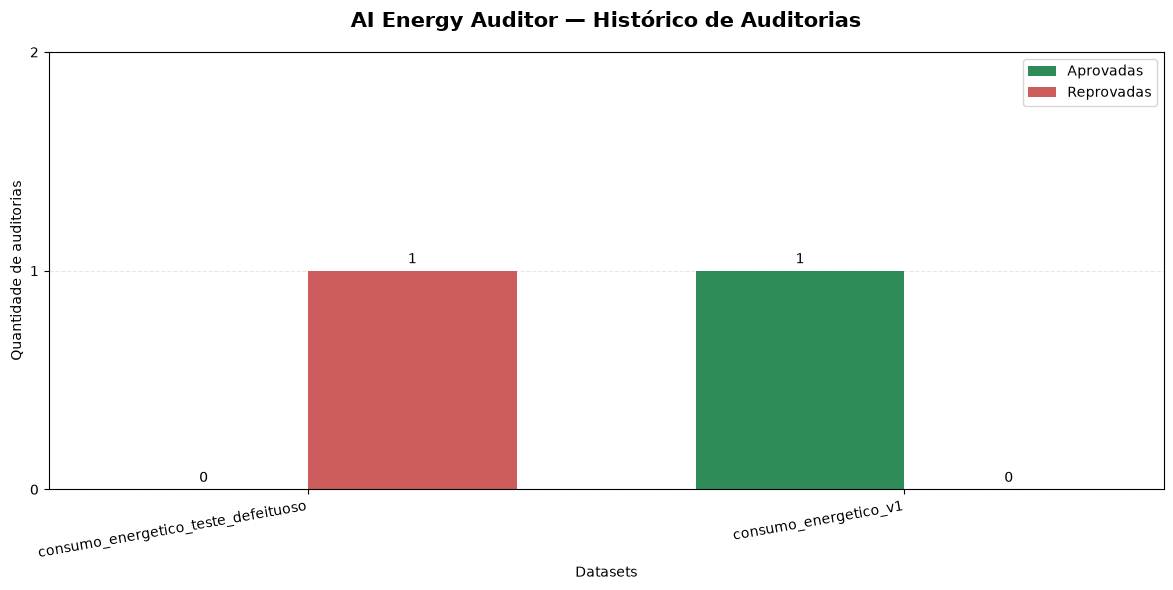

=== VALIDAÇÃO DO GRÁFICO ===
Dados do gráfico: APROVADOS
Contagem de aprovações: APROVADA
Contagem de reprovações: APROVADA
Integridade do relatório: APROVADA
Visualização comparativa: CONCLUÍDA


In [71]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 1. PREPARAR OS DADOS
# ============================================================

df_grafico_qualidade = (
    df_relatorio_consolidado.copy(deep=True)
)

# Utilizar os nomes reais dos datasets
datasets = df_grafico_qualidade["dataset"].tolist()

aprovadas = (
    df_grafico_qualidade["auditorias_aprovadas"]
    .to_numpy()
)

reprovadas = (
    df_grafico_qualidade["auditorias_reprovadas"]
    .to_numpy()
)

posicoes = np.arange(len(datasets))

largura_barras = 0.35


# ============================================================
# 2. CONSTRUIR O GRÁFICO
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

barras_aprovadas = ax.bar(
    posicoes - largura_barras / 2,
    aprovadas,
    largura_barras,
    label="Aprovadas",
    color="#2E8B57"
)

barras_reprovadas = ax.bar(
    posicoes + largura_barras / 2,
    reprovadas,
    largura_barras,
    label="Reprovadas",
    color="#CD5C5C"
)

ax.set_title(
    "AI Energy Auditor — Histórico de Auditorias",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Datasets")
ax.set_ylabel("Quantidade de auditorias")

ax.set_xticks(posicoes)

ax.set_xticklabels(
    datasets,
    rotation=10,
    ha="right"
)

ax.legend()

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Adicionar os valores sobre as barras
ax.bar_label(
    barras_aprovadas,
    padding=3
)

ax.bar_label(
    barras_reprovadas,
    padding=3
)

# Manter o eixo Y em quantidades inteiras
ax.yaxis.set_major_locator(
    plt.MaxNLocator(integer=True)
)

ax.set_ylim(
    0,
    max(
        int(df_grafico_qualidade["total_auditorias"].max()) + 1,
        2
    )
)

plt.tight_layout()
plt.show()


# ============================================================
# 3. VALIDAR OS DADOS DO GRÁFICO
# ============================================================

print("=== VALIDAÇÃO DO GRÁFICO ===")

assert len(datasets) == len(df_relatorio_consolidado)

assert (
    aprovadas.sum()
    == total_aprovadas
)

assert (
    reprovadas.sum()
    == total_reprovadas
)

assert (
    (aprovadas + reprovadas)
    == df_grafico_qualidade[
        "total_auditorias"
    ].to_numpy()
).all()

assert (
    df_grafico_qualidade.equals(
        df_relatorio_consolidado
    )
)

print("Dados do gráfico: APROVADOS")
print("Contagem de aprovações: APROVADA")
print("Contagem de reprovações: APROVADA")
print("Integridade do relatório: APROVADA")
print("Visualização comparativa: CONCLUÍDA")


SEMANA 02 — EXERCÍCIO 54 — ETAPA 2.
Exportação e validação do gráfico de auditorias


In [72]:
from pathlib import Path
from io import BytesIO
import matplotlib.pyplot as plt
import struct


# ============================================================
# 1. DEFINIR O CAMINHO DE EXPORTAÇÃO
# ============================================================

caminho_grafico_qualidade = Path(
    "../resultados/grafico_auditorias_qualidade_v1.png"
)

assert caminho_grafico_qualidade.parent.is_dir(), (
    "Diretório de resultados não encontrado."
)


# ============================================================
# 2. EXPORTAR A FIGURA JÁ CRIADA NA ETAPA 1
# ============================================================

# A variável fig foi criada na etapa anterior.
# Não precisamos gerar o gráfico novamente.

fig.savefig(
    caminho_grafico_qualidade,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    format="png"
)

print("=== EXPORTAÇÃO DO GRÁFICO ===")

print(
    f"Arquivo: {caminho_grafico_qualidade.resolve()}"
)

print(
    f"Tamanho: "
    f"{caminho_grafico_qualidade.stat().st_size} bytes"
)


# ============================================================
# 3. VERIFICAR O CABEÇALHO PNG
# ============================================================

with caminho_grafico_qualidade.open("rb") as arquivo:
    cabecalho = arquivo.read(24)

assinatura_png = b"\x89PNG\r\n\x1a\n"

assert cabecalho[:8] == assinatura_png, (
    "O arquivo não possui uma assinatura PNG válida."
)

# No formato PNG, a largura e a altura estão
# nos bytes 16 a 23 do cabeçalho.
largura, altura = struct.unpack(
    ">II",
    cabecalho[16:24]
)

print("\n=== PROPRIEDADES DA IMAGEM ===")

print(f"Largura: {largura} pixels")
print(f"Altura: {altura} pixels")
print("Resolução de exportação: 300 DPI")


# ============================================================
# 4. VALIDAR O ARQUIVO EXPORTADO
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert caminho_grafico_qualidade.is_file()

assert caminho_grafico_qualidade.stat().st_size > 0

assert largura > 0
assert altura > 0

assert fig is not None

assert len(fig.axes) >= 1

print("Arquivo PNG criado: APROVADO")
print("Assinatura PNG: APROVADA")
print("Dimensões da imagem: APROVADAS")
print("Figura Matplotlib preservada: APROVADA")
print("Exportação do gráfico: APROVADA")


=== EXPORTAÇÃO DO GRÁFICO ===
Arquivo: C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\grafico_auditorias_qualidade_v1.png
Tamanho: 116197 bytes

=== PROPRIEDADES DA IMAGEM ===
Largura: 3520 pixels
Altura: 1766 pixels
Resolução de exportação: 300 DPI

=== VALIDAÇÃO ===
Arquivo PNG criado: APROVADO
Assinatura PNG: APROVADA
Dimensões da imagem: APROVADAS
Figura Matplotlib preservada: APROVADA
Exportação do gráfico: APROVADA


## SEMANA 02 — EXERCÍCIO 55 — ETAPA 1.
### Resumo executivo automatizado de qualidade de dados


In [73]:
import pandas as pd


def gerar_resumo_executivo_qualidade(
    historico,
    relatorio_consolidado
):
    """
    Produz um resumo executivo das auditorias de qualidade.

    Retorna um dicionário com:
    - total_auditorias
    - auditorias_aprovadas
    - auditorias_reprovadas
    - taxa_aprovacao_pct
    - total_datasets
    - datasets_com_reprovacoes
    - situacao_geral

    A situação geral reflete o histórico analisado,
    não uma certificação de qualidade industrial.
    """

    if not isinstance(historico, pd.DataFrame):
        raise TypeError(
            "O histórico deve ser um DataFrame Pandas."
        )

    if not isinstance(relatorio_consolidado, pd.DataFrame):
        raise TypeError(
            "O relatório deve ser um DataFrame Pandas."
        )

    if historico.empty or relatorio_consolidado.empty:
        raise ValueError(
            "O histórico e o relatório não podem estar vazios."
        )

    # --------------------------------------------------------
    # 1. INDICADORES GERAIS
    # --------------------------------------------------------

    total_auditorias = len(historico)

    auditorias_aprovadas = int(
        (historico["aprovado"] == True).sum()
    )

    auditorias_reprovadas = int(
        (historico["aprovado"] == False).sum()
    )

    taxa_aprovacao_pct = (
        auditorias_aprovadas / total_auditorias
    ) * 100

    # --------------------------------------------------------
    # 2. INDICADORES POR DATASET
    # --------------------------------------------------------

    total_datasets = int(
        relatorio_consolidado["dataset"].nunique()
    )

    datasets_com_reprovacoes = (
        relatorio_consolidado.loc[
            relatorio_consolidado[
                "auditorias_reprovadas"
            ] > 0,
            "dataset"
        ].tolist()
    )

    # --------------------------------------------------------
    # 3. CLASSIFICAÇÃO DO HISTÓRICO
    # --------------------------------------------------------

    if auditorias_reprovadas == 0:
        situacao_geral = "SEM REPROVAÇÕES NO HISTÓRICO"
    else:
        situacao_geral = "HÁ AUDITORIAS REPROVADAS"

    # --------------------------------------------------------
    # 4. CONSTRUIR O RESUMO
    # --------------------------------------------------------

    resumo = {
        "total_auditorias": total_auditorias,
        "auditorias_aprovadas": auditorias_aprovadas,
        "auditorias_reprovadas": auditorias_reprovadas,
        "taxa_aprovacao_pct": taxa_aprovacao_pct,
        "total_datasets": total_datasets,
        "datasets_com_reprovacoes": (
            datasets_com_reprovacoes
        ),
        "situacao_geral": situacao_geral
    }

    return resumo


# ============================================================
# 5. GERAR RESUMO EXECUTIVO
# ============================================================

resumo_executivo = gerar_resumo_executivo_qualidade(
    df_historico_qualidade,
    df_relatorio_consolidado
)


# ============================================================
# 6. EXIBIR RESULTADOS
# ============================================================

print("=== AI ENERGY AUDITOR ===")
print("RESUMO EXECUTIVO DE QUALIDADE DE DADOS")
print("=" * 50)

print(
    f"Total de auditorias: "
    f"{resumo_executivo['total_auditorias']}"
)

print(
    f"Auditorias aprovadas: "
    f"{resumo_executivo['auditorias_aprovadas']}"
)

print(
    f"Auditorias reprovadas: "
    f"{resumo_executivo['auditorias_reprovadas']}"
)

print(
    f"Taxa de aprovação: "
    f"{resumo_executivo['taxa_aprovacao_pct']:.2f}%"
)

print(
    f"Datasets avaliados: "
    f"{resumo_executivo['total_datasets']}"
)

print(
    f"Situação geral: "
    f"{resumo_executivo['situacao_geral']}"
)

print("\nDatasets com reprovações:")

for nome_dataset in (
    resumo_executivo["datasets_com_reprovacoes"]
):
    print(f" - {nome_dataset}")


# ============================================================
# 7. VALIDAÇÕES
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert resumo_executivo["total_auditorias"] == len(
    df_historico_qualidade
)

assert (
    resumo_executivo["auditorias_aprovadas"]
    + resumo_executivo["auditorias_reprovadas"]
    == resumo_executivo["total_auditorias"]
)

assert (
    resumo_executivo["total_datasets"]
    == df_relatorio_consolidado["dataset"].nunique()
)

assert (
    "consumo_energetico_teste_defeituoso"
    in resumo_executivo["datasets_com_reprovacoes"]
)

assert (
    resumo_executivo["situacao_geral"]
    == "HÁ AUDITORIAS REPROVADAS"
)

print("Indicadores gerais: APROVADOS")
print("Consolidação por dataset: APROVADA")
print("Identificação de reprovações: APROVADA")
print("Classificação do histórico: APROVADA")
print("Resumo executivo: APROVADO")


=== AI ENERGY AUDITOR ===
RESUMO EXECUTIVO DE QUALIDADE DE DADOS
Total de auditorias: 2
Auditorias aprovadas: 1
Auditorias reprovadas: 1
Taxa de aprovação: 50.00%
Datasets avaliados: 2
Situação geral: HÁ AUDITORIAS REPROVADAS

Datasets com reprovações:
 - consumo_energetico_teste_defeituoso

=== VALIDAÇÃO ===
Indicadores gerais: APROVADOS
Consolidação por dataset: APROVADA
Identificação de reprovações: APROVADA
Classificação do histórico: APROVADA
Resumo executivo: APROVADO


SEMANA 02 — EXERCÍCIO 55 — ETAPA 2.
Exportação do resumo executivo em JSON


In [74]:

import json
from pathlib import Path
from datetime import datetime, timezone


# ============================================================
# 1. DEFINIR O CAMINHO DO ARQUIVO
# ============================================================

caminho_resumo_executivo = Path(
    "../resultados/resumo_executivo_qualidade_v1.json"
)

assert caminho_resumo_executivo.parent.is_dir(), (
    "Diretório de resultados não encontrado."
)


# ============================================================
# 2. PREPARAR O DOCUMENTO
# ============================================================

documento_resumo = {
    "projeto": "AI Energy Auditor",
    "tipo_documento": "resumo_executivo_qualidade",
    "versao": "1.0",
    "gerado_em_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "indicadores": resumo_executivo.copy()
}


# ============================================================
# 3. EXPORTAR PARA JSON
# ============================================================

with caminho_resumo_executivo.open(
    mode="w",
    encoding="utf-8"
) as arquivo:

    json.dump(
        documento_resumo,
        arquivo,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )


# ============================================================
# 4. RECARREGAR O DOCUMENTO
# ============================================================

with caminho_resumo_executivo.open(
    mode="r",
    encoding="utf-8"
) as arquivo:

    documento_recarregado = json.load(arquivo)


# ============================================================
# 5. EXIBIR O RESULTADO
# ============================================================

print("=== EXPORTAÇÃO DO RESUMO EXECUTIVO ===")

print(
    f"Arquivo: {caminho_resumo_executivo.resolve()}"
)

print(
    f"Tamanho: "
    f"{caminho_resumo_executivo.stat().st_size} bytes"
)

print("\n=== DOCUMENTO RECARREGADO ===")

print(
    json.dumps(
        documento_recarregado,
        ensure_ascii=False,
        indent=4
    )
)


# ============================================================
# 6. VALIDAR O DOCUMENTO
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert caminho_resumo_executivo.is_file()

assert caminho_resumo_executivo.stat().st_size > 0

assert (
    documento_recarregado["projeto"]
    == "AI Energy Auditor"
)

assert (
    documento_recarregado["tipo_documento"]
    == "resumo_executivo_qualidade"
)

assert (
    documento_recarregado["indicadores"]
    == resumo_executivo
)

# Validar horário UTC
horario_geracao = datetime.fromisoformat(
    documento_recarregado["gerado_em_utc"]
)

assert horario_geracao.utcoffset().total_seconds() == 0

# Confirmar que os indicadores continuam consistentes
indicadores = documento_recarregado["indicadores"]

assert (
    indicadores["auditorias_aprovadas"]
    + indicadores["auditorias_reprovadas"]
    == indicadores["total_auditorias"]
)

print("Arquivo JSON criado: APROVADO")
print("Metadados do documento: APROVADOS")
print("Integridade dos indicadores: APROVADA")
print("Horário UTC: APROVADO")
print("Consistência das contagens: APROVADA")
print("Exportação do resumo executivo: APROVADA")


=== EXPORTAÇÃO DO RESUMO EXECUTIVO ===
Arquivo: C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\resumo_executivo_qualidade_v1.json
Tamanho: 532 bytes

=== DOCUMENTO RECARREGADO ===
{
    "projeto": "AI Energy Auditor",
    "tipo_documento": "resumo_executivo_qualidade",
    "versao": "1.0",
    "gerado_em_utc": "2026-10-17T20:49:48.475009+00:00",
    "indicadores": {
        "total_auditorias": 2,
        "auditorias_aprovadas": 1,
        "auditorias_reprovadas": 1,
        "taxa_aprovacao_pct": 50.0,
        "total_datasets": 2,
        "datasets_com_reprovacoes": [
            "consumo_energetico_teste_defeituoso"
        ],
        "situacao_geral": "HÁ AUDITORIAS REPROVADAS"
    }
}

=== VALIDAÇÃO ===
Arquivo JSON criado: APROVADO
Metadados do documento: APROVADOS
Integridade dos indicadores: APROVADA
Horário UTC: APROVADO
Consistência das contagens: APROVADA
Exportação do resumo executivo: APROVADA


## SEMANA 02 — EXERCÍCIO 56 — ETAPA 1
### Consistência entre os artefatos de auditoria




In [75]:

import json
from pathlib import Path
import pandas as pd
from pandas.testing import assert_frame_equal


def verificar_consistencia_artefatos_qualidade(
    caminho_historico,
    caminho_relatorio,
    caminho_resumo
):
    """
    Verifica a consistência entre:
    1. Histórico JSONL
    2. Relatório consolidado CSV
    3. Resumo executivo JSON

    Retorna um dicionário com os resultados
    das verificações.
    """

    # --------------------------------------------------------
    # 1. CARREGAR OS ARTEFATOS
    # --------------------------------------------------------

    historico = consultar_historico_qualidade(
        caminho_historico
    )

    relatorio_arquivo = pd.read_csv(
        caminho_relatorio,
        encoding="utf-8"
    )

    with Path(caminho_resumo).open(
        mode="r",
        encoding="utf-8"
    ) as arquivo:

        resumo_arquivo = json.load(arquivo)

    # --------------------------------------------------------
    # 2. RECALCULAR OS RESULTADOS A PARTIR DO HISTÓRICO
    # --------------------------------------------------------

    relatorio_calculado = (
        gerar_relatorio_consolidado_qualidade(
            historico
        )
    )

    resumo_calculado = gerar_resumo_executivo_qualidade(
        historico,
        relatorio_calculado
    )

    # --------------------------------------------------------
    # 3. COMPARAR O RELATÓRIO CSV
    # --------------------------------------------------------

    try:

        assert_frame_equal(
            relatorio_arquivo,
            relatorio_calculado,
            check_exact=False,
            rtol=1e-6,
            atol=1e-6
        )

        relatorio_consistente = True

    except AssertionError:

        relatorio_consistente = False

    # --------------------------------------------------------
    # 4. COMPARAR O RESUMO JSON
    # --------------------------------------------------------

    resumo_persistido = resumo_arquivo.get(
        "indicadores"
    )

    resumo_consistente = (
        resumo_persistido == resumo_calculado
    )

    # --------------------------------------------------------
    # 5. CONSOLIDAR RESULTADOS
    # --------------------------------------------------------

    verificacoes = {
        "historico_carregado": True,
        "relatorio_csv_consistente": (
            relatorio_consistente
        ),
        "resumo_json_consistente": (
            resumo_consistente
        )
    }

    verificacoes["todos_consistentes"] = all(
        verificacoes.values()
    )

    return verificacoes


# ============================================================
# 6. EXECUTAR A VERIFICAÇÃO
# ============================================================

resultado_consistencia = (
    verificar_consistencia_artefatos_qualidade(
        caminho_log_qualidade,
        caminho_relatorio_qualidade,
        caminho_resumo_executivo
    )
)


# ============================================================
# 7. EXIBIR RESULTADOS
# ============================================================

print("=== CONSISTÊNCIA DOS ARTEFATOS ===")

for verificacao, resultado in (
    resultado_consistencia.items()
):

    situacao = (
        "APROVADO"
        if resultado
        else "REVISAR"
    )

    print(f"{verificacao}: {situacao}")


# ============================================================
# 8. VALIDAÇÃO
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert resultado_consistencia[
    "historico_carregado"
] is True

assert resultado_consistencia[
    "relatorio_csv_consistente"
] is True

assert resultado_consistencia[
    "resumo_json_consistente"
] is True

assert resultado_consistencia[
    "todos_consistentes"
] is True

print("Histórico de auditorias: APROVADO")
print("Relatório consolidado: APROVADO")
print("Resumo executivo: APROVADO")
print("Consistência entre artefatos: APROVADA")


=== CONSISTÊNCIA DOS ARTEFATOS ===
historico_carregado: APROVADO
relatorio_csv_consistente: APROVADO
resumo_json_consistente: APROVADO
todos_consistentes: APROVADO

=== VALIDAÇÃO ===
Histórico de auditorias: APROVADO
Relatório consolidado: APROVADO
Resumo executivo: APROVADO
Consistência entre artefatos: APROVADA


SEMANA 02 — EXERCÍCIO 56 — ETAPA 2.
Teste negativo de consistência entre artefatos


In [76]:

import shutil
import tempfile
from pathlib import Path
import pandas as pd


# ============================================================
# 1. CRIAR AMBIENTE TEMPORÁRIO ISOLADO
# ============================================================

print("=== TESTE NEGATIVO DE CONSISTÊNCIA ===")

with tempfile.TemporaryDirectory() as diretorio_temp:

    pasta_teste = Path(diretorio_temp)

    # --------------------------------------------------------
    # 2. COPIAR OS TRÊS ARTEFATOS
    # --------------------------------------------------------

    historico_teste = (
        pasta_teste / "auditoria_qualidade.jsonl"
    )

    relatorio_teste = (
        pasta_teste / "relatorio_qualidade.csv"
    )

    resumo_teste = (
        pasta_teste / "resumo_qualidade.json"
    )

    shutil.copy2(
        caminho_log_qualidade,
        historico_teste
    )

    shutil.copy2(
        caminho_relatorio_qualidade,
        relatorio_teste
    )

    shutil.copy2(
        caminho_resumo_executivo,
        resumo_teste
    )

    print("Cópias temporárias criadas: APROVADO")

    # --------------------------------------------------------
    # 3. VERIFICAR CONSISTÊNCIA ANTES DA ALTERAÇÃO
    # --------------------------------------------------------

    resultado_antes = (
        verificar_consistencia_artefatos_qualidade(
            historico_teste,
            relatorio_teste,
            resumo_teste
        )
    )

    assert resultado_antes["todos_consistentes"] is True

    print("Consistência inicial: APROVADA")

    # --------------------------------------------------------
    # 4. INTRODUZIR UM ERRO NO CSV TEMPORÁRIO
    # --------------------------------------------------------

    df_relatorio_teste = pd.read_csv(
        relatorio_teste,
        encoding="utf-8"
    )

    # Alterar propositalmente a contagem de auditorias
    df_relatorio_teste.loc[
        0,
        "total_auditorias"
    ] += 1

    df_relatorio_teste.to_csv(
        relatorio_teste,
        index=False,
        encoding="utf-8"
    )

    print("Alteração controlada no CSV: REALIZADA")

    # --------------------------------------------------------
    # 5. VERIFICAR DETECÇÃO DA INCONSISTÊNCIA
    # --------------------------------------------------------

    resultado_depois = (
        verificar_consistencia_artefatos_qualidade(
            historico_teste,
            relatorio_teste,
            resumo_teste
        )
    )

    assert (
        resultado_depois["historico_carregado"]
        is True
    )

    assert (
        resultado_depois["relatorio_csv_consistente"]
        is False
    )

    assert (
        resultado_depois["resumo_json_consistente"]
        is True
    )

    assert (
        resultado_depois["todos_consistentes"]
        is False
    )

    print("\n=== RESULTADO DA AUDITORIA NEGATIVA ===")

    for verificacao, resultado in resultado_depois.items():

        situacao = (
            "CONSISTENTE"
            if resultado
            else "INCONSISTENTE"
        )

        print(f"{verificacao}: {situacao}")

    print("\nInconsistência no CSV: DETECTADA")

# Ao sair do bloco with, o diretório temporário
# e os arquivos de teste são eliminados.


# ============================================================
# 6. VERIFICAR OS ARTEFATOS ORIGINAIS
# ============================================================

print("\n=== VERIFICAÇÃO DOS ARQUIVOS ORIGINAIS ===")

resultado_final = (
    verificar_consistencia_artefatos_qualidade(
        caminho_log_qualidade,
        caminho_relatorio_qualidade,
        caminho_resumo_executivo
    )
)

assert resultado_final["todos_consistentes"] is True

print("Arquivos originais: CONSISTENTES")


# ============================================================
# 7. VALIDAÇÃO FINAL
# ============================================================

print("\n=== VALIDAÇÃO FINAL ===")

print("Cópias temporárias: APROVADAS")
print("Alteração controlada: APROVADA")
print("Detecção de inconsistência: APROVADA")
print("Preservação dos originais: APROVADA")
print("Teste negativo de consistência: APROVADO")


=== TESTE NEGATIVO DE CONSISTÊNCIA ===
Cópias temporárias criadas: APROVADO
Consistência inicial: APROVADA
Alteração controlada no CSV: REALIZADA

=== RESULTADO DA AUDITORIA NEGATIVA ===
historico_carregado: CONSISTENTE
relatorio_csv_consistente: INCONSISTENTE
resumo_json_consistente: CONSISTENTE
todos_consistentes: INCONSISTENTE

Inconsistência no CSV: DETECTADA

=== VERIFICAÇÃO DOS ARQUIVOS ORIGINAIS ===
Arquivos originais: CONSISTENTES

=== VALIDAÇÃO FINAL ===
Cópias temporárias: APROVADAS
Alteração controlada: APROVADA
Detecção de inconsistência: APROVADA
Preservação dos originais: APROVADA
Teste negativo de consistência: APROVADO


## SEMANA 02 — EXERCÍCIO 57 — ETAPA 1
### Manifesto SHA-256 dos artefatos de auditoria

In [77]:

import hashlib
import json
from pathlib import Path
from datetime import datetime, timezone


def calcular_sha256_artefato(caminho_arquivo):
    """
    Calcula o hash SHA-256 de um arquivo utilizando
    leitura em blocos, sem carregar todo o conteúdo
    na memória.
    """

    caminho = Path(caminho_arquivo)

    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho}"
        )

    sha256 = hashlib.sha256()

    with caminho.open("rb") as arquivo:
        for bloco in iter(
            lambda: arquivo.read(65536),
            b""
        ):
            sha256.update(bloco)

    return sha256.hexdigest()


# ============================================================
# 1. DEFINIR OS ARTEFATOS A SEREM PROTEGIDOS
# ============================================================

artefatos_qualidade = {
    "historico_auditorias": caminho_log_qualidade,
    "relatorio_consolidado": caminho_relatorio_qualidade,
    "resumo_executivo": caminho_resumo_executivo
}


# ============================================================
# 2. GERAR O MANIFESTO
# ============================================================

manifesto_qualidade = {
    "projeto": "AI Energy Auditor",
    "tipo_documento": "manifesto_integridade_qualidade",
    "versao": "1.0",
    "gerado_em_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "algoritmo": "SHA-256",
    "artefatos": {}
}

for nome, caminho in artefatos_qualidade.items():

    caminho = Path(caminho)

    manifesto_qualidade["artefatos"][nome] = {
        "arquivo": caminho.name,
        "tamanho_bytes": caminho.stat().st_size,
        "sha256": calcular_sha256_artefato(caminho)
    }


# ============================================================
# 3. PERSISTIR O MANIFESTO
# ============================================================

caminho_manifesto_qualidade = Path(
    "../resultados/manifesto_integridade_qualidade_v1.json"
)

assert caminho_manifesto_qualidade.parent.is_dir()

with caminho_manifesto_qualidade.open(
    mode="w",
    encoding="utf-8"
) as arquivo:

    json.dump(
        manifesto_qualidade,
        arquivo,
        ensure_ascii=False,
        indent=4
    )


# ============================================================
# 4. RECARREGAR O MANIFESTO
# ============================================================

with caminho_manifesto_qualidade.open(
    mode="r",
    encoding="utf-8"
) as arquivo:

    manifesto_recarregado = json.load(arquivo)


# ============================================================
# 5. EXIBIR OS RESULTADOS
# ============================================================

print("=== MANIFESTO DE INTEGRIDADE ===")

print(
    f"Arquivo: {caminho_manifesto_qualidade.resolve()}"
)

for nome, informacoes in (
    manifesto_recarregado["artefatos"].items()
):

    print(f"\nArtefato: {nome}")
    print(f"Arquivo: {informacoes['arquivo']}")
    print(f"Tamanho: {informacoes['tamanho_bytes']} bytes")
    print(f"SHA-256: {informacoes['sha256']}")


# ============================================================
# 6. VALIDAÇÕES
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert caminho_manifesto_qualidade.is_file()

assert manifesto_recarregado["algoritmo"] == "SHA-256"

assert len(
    manifesto_recarregado["artefatos"]
) == 3

for nome, caminho in artefatos_qualidade.items():

    informacoes = (
        manifesto_recarregado["artefatos"][nome]
    )

    assert informacoes["sha256"] == (
        calcular_sha256_artefato(caminho)
    )

    assert informacoes["tamanho_bytes"] == (
        Path(caminho).stat().st_size
    )

    assert len(informacoes["sha256"]) == 64

print("Manifesto JSON criado: APROVADO")
print("Três artefatos registrados: APROVADO")
print("Hashes SHA-256 calculados: APROVADO")
print("Tamanhos dos arquivos: APROVADOS")
print("Integridade inicial: APROVADA")


=== MANIFESTO DE INTEGRIDADE ===
Arquivo: C:\Engenharia-IA\01-Fundamentos-Python-ML\resultados\manifesto_integridade_qualidade_v1.json

Artefato: historico_auditorias
Arquivo: auditoria_qualidade_energetica_v1.jsonl
Tamanho: 973 bytes
SHA-256: d7def492d0694674767c66bf2d73f0ca23a2a701533e27abb7f24683a86668c9

Artefato: relatorio_consolidado
Arquivo: relatorio_consolidado_qualidade_v1.csv
Tamanho: 180 bytes
SHA-256: 86a3d00b8fe70a1e9da3368da1164403c05f3f540817fba762c24c66974a511a

Artefato: resumo_executivo
Arquivo: resumo_executivo_qualidade_v1.json
Tamanho: 532 bytes
SHA-256: e16567248b3fbf8375d88fc35b9cd7c1bf005de6560e317fdaccc33ccfaf577f

=== VALIDAÇÃO ===
Manifesto JSON criado: APROVADO
Três artefatos registrados: APROVADO
Hashes SHA-256 calculados: APROVADO
Tamanhos dos arquivos: APROVADOS
Integridade inicial: APROVADA


## SEMANA 02 — EXERCÍCIO 57 — ETAPA 2
### Verificação de integridade dos artefatos de auditoria


In [78]:
import json
from pathlib import Path


def verificar_integridade_qualidade(
    caminho_manifesto,
    diretorio_artefatos
):
    """
    Compara os arquivos com o manifesto SHA-256.

    Estados possíveis:
    - ÍNTEGRO: tamanho e hash coincidem
    - ALTERADO: tamanho ou hash divergem
    - AUSENTE: arquivo não encontrado

    Retorna um dicionário com os resultados.
    """

    caminho_manifesto = Path(caminho_manifesto)
    diretorio_artefatos = Path(diretorio_artefatos)

    if not caminho_manifesto.is_file():
        raise FileNotFoundError(
            f"Manifesto não encontrado: {caminho_manifesto}"
        )

    if not diretorio_artefatos.is_dir():
        raise NotADirectoryError(
            f"Diretório não encontrado: {diretorio_artefatos}"
        )

    with caminho_manifesto.open(
        mode="r",
        encoding="utf-8"
    ) as arquivo:

        manifesto = json.load(arquivo)

    if manifesto.get("algoritmo") != "SHA-256":
        raise ValueError(
            "Algoritmo de integridade não suportado."
        )

    artefatos = manifesto.get("artefatos")

    if not isinstance(artefatos, dict) or not artefatos:
        raise ValueError(
            "Manifesto sem artefatos válidos."
        )

    resultados = {}

    for nome, informacoes in artefatos.items():

        if not isinstance(informacoes, dict):
            raise ValueError(
                f"Registro inválido: {nome}"
            )

        nome_arquivo = informacoes["arquivo"]

        # Impede que o manifesto aponte para
        # caminhos externos ao diretório informado.
        if (
            not isinstance(nome_arquivo, str)
            or Path(nome_arquivo).name != nome_arquivo
            or nome_arquivo in (".", "..")
        ):
            raise ValueError(
                f"Nome de arquivo inválido: {nome}"
            )

        caminho = diretorio_artefatos / nome_arquivo

        if not caminho.is_file():

            resultados[nome] = {
                "arquivo": nome_arquivo,
                "situacao": "AUSENTE",
                "tamanho_confere": False,
                "hash_confere": False
            }

            continue

        tamanho_atual = caminho.stat().st_size

        hash_atual = calcular_sha256_artefato(
            caminho
        )

        tamanho_confere = (
            tamanho_atual
            == informacoes["tamanho_bytes"]
        )

        hash_confere = (
            hash_atual
            == informacoes["sha256"]
        )

        situacao = (
            "ÍNTEGRO"
            if tamanho_confere and hash_confere
            else "ALTERADO"
        )

        resultados[nome] = {
            "arquivo": nome_arquivo,
            "situacao": situacao,
            "tamanho_confere": tamanho_confere,
            "hash_confere": hash_confere
        }

    return resultados


# ============================================================
# 1. EXECUTAR A VERIFICAÇÃO
# ============================================================

resultado_integridade = (
    verificar_integridade_qualidade(
        caminho_manifesto_qualidade,
        caminho_manifesto_qualidade.parent
    )
)


# ============================================================
# 2. EXIBIR RESULTADOS
# ============================================================

print("=== VERIFICAÇÃO DE INTEGRIDADE ===")

for nome, resultado in resultado_integridade.items():

    print(f"\nArtefato: {nome}")
    print(f"Arquivo: {resultado['arquivo']}")
    print(f"Situação: {resultado['situacao']}")

    print(
        f"Tamanho confere: "
        f"{resultado['tamanho_confere']}"
    )

    print(
        f"Hash confere: "
        f"{resultado['hash_confere']}"
    )


# ============================================================
# 3. VALIDAÇÕES
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert len(resultado_integridade) == 3

assert all(
    resultado["situacao"] == "ÍNTEGRO"
    for resultado in resultado_integridade.values()
)

assert all(
    resultado["tamanho_confere"]
    for resultado in resultado_integridade.values()
)

assert all(
    resultado["hash_confere"]
    for resultado in resultado_integridade.values()
)

print("Manifesto carregado: APROVADO")
print("Três artefatos verificados: APROVADO")
print("Tamanhos dos arquivos: APROVADOS")
print("Hashes SHA-256: APROVADOS")
print("Integridade dos artefatos: APROVADA")


=== VERIFICAÇÃO DE INTEGRIDADE ===

Artefato: historico_auditorias
Arquivo: auditoria_qualidade_energetica_v1.jsonl
Situação: ÍNTEGRO
Tamanho confere: True
Hash confere: True

Artefato: relatorio_consolidado
Arquivo: relatorio_consolidado_qualidade_v1.csv
Situação: ÍNTEGRO
Tamanho confere: True
Hash confere: True

Artefato: resumo_executivo
Arquivo: resumo_executivo_qualidade_v1.json
Situação: ÍNTEGRO
Tamanho confere: True
Hash confere: True

=== VALIDAÇÃO ===
Manifesto carregado: APROVADO
Três artefatos verificados: APROVADO
Tamanhos dos arquivos: APROVADOS
Hashes SHA-256: APROVADOS
Integridade dos artefatos: APROVADA


SEMANA 02 — EXERCÍCIO 57 — ETAPA 3
Testes negativos de integridade SHA-256



In [79]:

import shutil
import tempfile
from pathlib import Path


print("=== TESTES NEGATIVOS DE INTEGRIDADE ===")

# ============================================================
# 1. CRIAR AMBIENTE TEMPORÁRIO
# ============================================================

with tempfile.TemporaryDirectory() as diretorio_temp:

    pasta_teste = Path(diretorio_temp)

    # --------------------------------------------------------
    # 2. COPIAR OS ARTEFATOS E O MANIFESTO
    # --------------------------------------------------------

    for caminho in artefatos_qualidade.values():

        caminho = Path(caminho)

        shutil.copy2(
            caminho,
            pasta_teste / caminho.name
        )

    manifesto_teste = (
        pasta_teste / caminho_manifesto_qualidade.name
    )

    shutil.copy2(
        caminho_manifesto_qualidade,
        manifesto_teste
    )

    print("Ambiente temporário criado: APROVADO")

    # ========================================================
    # 3. CENÁRIO A — ARQUIVOS INTACTOS
    # ========================================================

    resultado_intacto = verificar_integridade_qualidade(
        manifesto_teste,
        pasta_teste
    )

    assert all(
        item["situacao"] == "ÍNTEGRO"
        for item in resultado_intacto.values()
    )

    print("Cenário A — Arquivos intactos: APROVADO")

    # ========================================================
    # 4. CENÁRIO B — ALTERAÇÃO CONTROLADA
    # ========================================================

    arquivo_alterado = (
        pasta_teste
        / Path(
            artefatos_qualidade["relatorio_consolidado"]
        ).name
    )

    # Acrescentar um byte ao final do CSV temporário.
    with arquivo_alterado.open("ab") as arquivo:
        arquivo.write(b"X")

    resultado_alterado = verificar_integridade_qualidade(
        manifesto_teste,
        pasta_teste
    )

    assert (
        resultado_alterado[
            "relatorio_consolidado"
        ]["situacao"]
        == "ALTERADO"
    )

    assert (
        resultado_alterado[
            "historico_auditorias"
        ]["situacao"]
        == "ÍNTEGRO"
    )

    assert (
        resultado_alterado[
            "resumo_executivo"
        ]["situacao"]
        == "ÍNTEGRO"
    )

    print("Cenário B — Arquivo alterado: DETECTADO")

    # ========================================================
    # 5. CENÁRIO C — ARQUIVO AUSENTE
    # ========================================================

    arquivo_ausente = (
        pasta_teste
        / Path(
            artefatos_qualidade["resumo_executivo"]
        ).name
    )

    arquivo_ausente.unlink()

    resultado_ausente = verificar_integridade_qualidade(
        manifesto_teste,
        pasta_teste
    )

    assert (
        resultado_ausente[
            "resumo_executivo"
        ]["situacao"]
        == "AUSENTE"
    )

    assert (
        resultado_ausente[
            "relatorio_consolidado"
        ]["situacao"]
        == "ALTERADO"
    )

    assert (
        resultado_ausente[
            "historico_auditorias"
        ]["situacao"]
        == "ÍNTEGRO"
    )

    print("Cenário C — Arquivo ausente: DETECTADO")

    # ========================================================
    # 6. EXIBIR RESULTADOS FINAIS DO TESTE
    # ========================================================

    print("\n=== CLASSIFICAÇÃO DOS ARTEFATOS ===")

    for nome, resultado in resultado_ausente.items():

        print(
            f"{nome}: {resultado['situacao']}"
        )

# O diretório temporário é removido automaticamente.


# ============================================================
# 7. VERIFICAR OS ARQUIVOS ORIGINAIS
# ============================================================

print("\n=== PRESERVAÇÃO DOS ORIGINAIS ===")

resultado_originais = verificar_integridade_qualidade(
    caminho_manifesto_qualidade,
    caminho_manifesto_qualidade.parent
)

assert all(
    item["situacao"] == "ÍNTEGRO"
    for item in resultado_originais.values()
)

print("Três artefatos originais: ÍNTEGROS")


# ============================================================
# 8. VALIDAÇÃO FINAL
# ============================================================

print("\n=== VALIDAÇÃO FINAL ===")

print("Ambiente isolado: APROVADO")
print("Detecção de arquivo alterado: APROVADA")
print("Detecção de arquivo ausente: APROVADA")
print("Preservação dos arquivos originais: APROVADA")
print("Testes negativos SHA-256: APROVADOS")


=== TESTES NEGATIVOS DE INTEGRIDADE ===
Ambiente temporário criado: APROVADO
Cenário A — Arquivos intactos: APROVADO
Cenário B — Arquivo alterado: DETECTADO
Cenário C — Arquivo ausente: DETECTADO

=== CLASSIFICAÇÃO DOS ARTEFATOS ===
historico_auditorias: ÍNTEGRO
relatorio_consolidado: ALTERADO
resumo_executivo: AUSENTE

=== PRESERVAÇÃO DOS ORIGINAIS ===
Três artefatos originais: ÍNTEGROS

=== VALIDAÇÃO FINAL ===
Ambiente isolado: APROVADO
Detecção de arquivo alterado: APROVADA
Detecção de arquivo ausente: APROVADA
Preservação dos arquivos originais: APROVADA
Testes negativos SHA-256: APROVADOS


## SEMANA 02 — EXERCÍCIO 58 — ETAPA 1
### Diagnóstico operacional unificado
### AI ENERGY AUDITOR


In [80]:
from pathlib import Path


def executar_diagnostico_operacional(
    caminho_historico,
    caminho_relatorio,
    caminho_resumo,
    caminho_manifesto
):
    """
    Integra as verificações de:
    1. Integridade criptográfica (SHA-256)
    2. Consistência lógica entre artefatos

    Retorna um dicionário com a decisão operacional.

    Por segurança, a consistência só é avaliada
    quando todos os artefatos estão íntegros.
    """

    # --------------------------------------------------------
    # 1. VERIFICAR INTEGRIDADE
    # --------------------------------------------------------

    resultado_integridade = (
        verificar_integridade_qualidade(
            caminho_manifesto,
            Path(caminho_manifesto).parent
        )
    )

    integridade_aprovada = all(
        item["situacao"] == "ÍNTEGRO"
        for item in resultado_integridade.values()
    )

    # --------------------------------------------------------
    # 2. VERIFICAR CONSISTÊNCIA
    # --------------------------------------------------------

    if integridade_aprovada:

        resultado_consistencia = (
            verificar_consistencia_artefatos_qualidade(
                caminho_historico,
                caminho_relatorio,
                caminho_resumo
            )
        )

        consistencia_aprovada = (
            resultado_consistencia["todos_consistentes"]
        )

    else:

        # Não avaliar dados cuja integridade
        # não foi confirmada.
        resultado_consistencia = None
        consistencia_aprovada = False

    # --------------------------------------------------------
    # 3. DECISÃO OPERACIONAL
    # --------------------------------------------------------

    operacao_liberada = (
        integridade_aprovada
        and consistencia_aprovada
    )

    decisao = (
        "APROVADO"
        if operacao_liberada
        else "BLOQUEADO"
    )

    diagnostico = {
        "integridade_aprovada": integridade_aprovada,
        "consistencia_aprovada": consistencia_aprovada,
        "operacao_liberada": operacao_liberada,
        "decisao": decisao,
        "detalhes_integridade": resultado_integridade,
        "detalhes_consistencia": resultado_consistencia
    }

    return diagnostico


# ============================================================
# 4. EXECUTAR O DIAGNÓSTICO
# ============================================================

diagnostico_operacional = (
    executar_diagnostico_operacional(
        caminho_log_qualidade,
        caminho_relatorio_qualidade,
        caminho_resumo_executivo,
        caminho_manifesto_qualidade
    )
)


# ============================================================
# 5. EXIBIR RESULTADOS
# ============================================================

print("=== AI ENERGY AUDITOR ===")
print("DIAGNÓSTICO OPERACIONAL UNIFICADO")
print("=" * 50)

print(
    "Integridade criptográfica:",
    "APROVADA"
    if diagnostico_operacional["integridade_aprovada"]
    else "REPROVADA"
)

print(
    "Consistência lógica:",
    "APROVADA"
    if diagnostico_operacional["consistencia_aprovada"]
    else "REPROVADA"
)

print(
    "Operação liberada:",
    diagnostico_operacional["operacao_liberada"]
)

print(
    "Decisão operacional:",
    diagnostico_operacional["decisao"]
)


# ============================================================
# 6. VALIDAÇÕES
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert (
    diagnostico_operacional["integridade_aprovada"]
    is True
)

assert (
    diagnostico_operacional["consistencia_aprovada"]
    is True
)

assert (
    diagnostico_operacional["operacao_liberada"]
    is True
)

assert (
    diagnostico_operacional["decisao"]
    == "APROVADO"
)

assert (
    diagnostico_operacional["detalhes_consistencia"]
    is not None
)

print("Verificação criptográfica: APROVADA")
print("Verificação de consistência: APROVADA")
print("Integração dos mecanismos: APROVADA")
print("Decisão operacional: APROVADA")
print("Diagnóstico unificado: APROVADO")


=== AI ENERGY AUDITOR ===
DIAGNÓSTICO OPERACIONAL UNIFICADO
Integridade criptográfica: APROVADA
Consistência lógica: APROVADA
Operação liberada: True
Decisão operacional: APROVADO

=== VALIDAÇÃO ===
Verificação criptográfica: APROVADA
Verificação de consistência: APROVADA
Integração dos mecanismos: APROVADA
Decisão operacional: APROVADA
Diagnóstico unificado: APROVADO


SEMANA 02 — EXERCÍCIO 58 — ETAPA 2
Teste de bloqueio automático por falha de integridade

In [81]:

import shutil
import tempfile
from pathlib import Path


print("=== TESTE DE BLOQUEIO AUTOMÁTICO ===")

# ============================================================
# 1. CRIAR AMBIENTE TEMPORÁRIO
# ============================================================

with tempfile.TemporaryDirectory() as diretorio_temp:

    pasta_teste = Path(diretorio_temp)

    # --------------------------------------------------------
    # 2. COPIAR OS ARTEFATOS E O MANIFESTO
    # --------------------------------------------------------

    caminhos_originais = [
        caminho_log_qualidade,
        caminho_relatorio_qualidade,
        caminho_resumo_executivo,
        caminho_manifesto_qualidade
    ]

    for caminho in caminhos_originais:

        caminho = Path(caminho)

        shutil.copy2(
            caminho,
            pasta_teste / caminho.name
        )

    historico_teste = (
        pasta_teste / Path(caminho_log_qualidade).name
    )

    relatorio_teste = (
        pasta_teste / Path(caminho_relatorio_qualidade).name
    )

    resumo_teste = (
        pasta_teste / Path(caminho_resumo_executivo).name
    )

    manifesto_teste = (
        pasta_teste / Path(caminho_manifesto_qualidade).name
    )

    print("Cópias temporárias: CRIADAS")

    # ========================================================
    # 3. CONFIRMAR APROVAÇÃO ANTES DA ALTERAÇÃO
    # ========================================================

    diagnostico_inicial = executar_diagnostico_operacional(
        historico_teste,
        relatorio_teste,
        resumo_teste,
        manifesto_teste
    )

    assert diagnostico_inicial["decisao"] == "APROVADO"
    assert diagnostico_inicial["operacao_liberada"] is True

    print("Diagnóstico inicial: APROVADO")

    # ========================================================
    # 4. ALTERAR O RELATÓRIO TEMPORÁRIO
    # ========================================================

    with relatorio_teste.open("ab") as arquivo:
        arquivo.write(b"\nALTERACAO_CONTROLADA")

    print("Alteração controlada: REALIZADA")

    # ========================================================
    # 5. EXECUTAR NOVO DIAGNÓSTICO
    # ========================================================

    diagnostico_bloqueado = executar_diagnostico_operacional(
        historico_teste,
        relatorio_teste,
        resumo_teste,
        manifesto_teste
    )

    print("\n=== DIAGNÓSTICO APÓS ALTERAÇÃO ===")

    print(
        "Integridade aprovada:",
        diagnostico_bloqueado["integridade_aprovada"]
    )

    print(
        "Consistência aprovada:",
        diagnostico_bloqueado["consistencia_aprovada"]
    )

    print(
        "Operação liberada:",
        diagnostico_bloqueado["operacao_liberada"]
    )

    print(
        "Decisão operacional:",
        diagnostico_bloqueado["decisao"]
    )

    print(
        "Situação do relatório:",
        diagnostico_bloqueado[
            "detalhes_integridade"
        ]["relatorio_consolidado"]["situacao"]
    )

    # ========================================================
    # 6. VALIDAR O BLOQUEIO
    # ========================================================

    assert (
        diagnostico_bloqueado["integridade_aprovada"]
        is False
    )

    assert (
        diagnostico_bloqueado["consistencia_aprovada"]
        is False
    )

    assert (
        diagnostico_bloqueado["operacao_liberada"]
        is False
    )

    assert (
        diagnostico_bloqueado["decisao"]
        == "BLOQUEADO"
    )

    assert (
        diagnostico_bloqueado["detalhes_consistencia"]
        is None
    )

    assert (
        diagnostico_bloqueado[
            "detalhes_integridade"
        ]["relatorio_consolidado"]["situacao"]
        == "ALTERADO"
    )

    print("\nBloqueio automático: APROVADO")
    print("Verificação lógica interrompida: APROVADA")


# ============================================================
# 7. VERIFICAR OS ARQUIVOS ORIGINAIS
# ============================================================

print("\n=== PRESERVAÇÃO DOS ORIGINAIS ===")

diagnostico_original = executar_diagnostico_operacional(
    caminho_log_qualidade,
    caminho_relatorio_qualidade,
    caminho_resumo_executivo,
    caminho_manifesto_qualidade
)

assert diagnostico_original["decisao"] == "APROVADO"

print("Diagnóstico dos arquivos originais: APROVADO")


# ============================================================
# 8. RESULTADO FINAL
# ============================================================

print("\n=== VALIDAÇÃO FINAL ===")

print("Detecção de alteração: APROVADA")
print("Bloqueio por integridade: APROVADO")
print("Interrupção da verificação lógica: APROVADA")
print("Preservação dos originais: APROVADA")
print("Teste de bloqueio operacional: APROVADO")


=== TESTE DE BLOQUEIO AUTOMÁTICO ===
Cópias temporárias: CRIADAS
Diagnóstico inicial: APROVADO
Alteração controlada: REALIZADA

=== DIAGNÓSTICO APÓS ALTERAÇÃO ===
Integridade aprovada: False
Consistência aprovada: False
Operação liberada: False
Decisão operacional: BLOQUEADO
Situação do relatório: ALTERADO

Bloqueio automático: APROVADO
Verificação lógica interrompida: APROVADA

=== PRESERVAÇÃO DOS ORIGINAIS ===
Diagnóstico dos arquivos originais: APROVADO

=== VALIDAÇÃO FINAL ===
Detecção de alteração: APROVADA
Bloqueio por integridade: APROVADO
Interrupção da verificação lógica: APROVADA
Preservação dos originais: APROVADA
Teste de bloqueio operacional: APROVADO


## SEMANA 02 — EXERCÍCIO 59 — ETAPA 1
### Barreira de execução baseada no diagnóstico operacional


In [83]:

class ErroDiagnosticoOperacional(RuntimeError):
    """
    Exceção para impedir operações quando
    os artefatos não atendem aos controles.
    """
    pass


def exigir_diagnostico_aprovado(
    caminho_historico,
    caminho_relatorio,
    caminho_resumo,
    caminho_manifesto
):
    """
    Executa o diagnóstico operacional.

    Se houver reprovação, lança uma exceção
    e impede a continuidade da rotina.

    Se aprovado, retorna o diagnóstico.
    """

    diagnostico = executar_diagnostico_operacional(
        caminho_historico,
        caminho_relatorio,
        caminho_resumo,
        caminho_manifesto
    )

    if diagnostico["decisao"] != "APROVADO":

        problemas = [
            nome
            for nome, resultado
            in diagnostico["detalhes_integridade"].items()
            if resultado["situacao"] != "ÍNTEGRO"
        ]

        raise ErroDiagnosticoOperacional(
            "Execução bloqueada: falha nos controles "
            "de integridade ou consistência. "
            f"Artefatos com problema: {problemas}"
        )

    return diagnostico


# ============================================================
# 1. TESTAR COM OS ARTEFATOS ORIGINAIS
# ============================================================

print("=== QUALITY GATE OPERACIONAL ===")

diagnostico_liberado = exigir_diagnostico_aprovado(
    caminho_log_qualidade,
    caminho_relatorio_qualidade,
    caminho_resumo_executivo,
    caminho_manifesto_qualidade
)

print(
    "Decisão:",
    diagnostico_liberado["decisao"]
)

print(
    "Execução autorizada pelos controles:",
    diagnostico_liberado["operacao_liberada"]
)


# ============================================================
# 2. SIMULAR UMA ROTINA PROTEGIDA
# ============================================================

def executar_rotina_protegida(diagnostico):
    """
    Representa uma etapa de processamento
    que depende dos artefatos auditados.
    """

    if diagnostico["decisao"] != "APROVADO":
        raise ErroDiagnosticoOperacional(
            "A rotina não pode ser executada."
        )

    return {
        "rotina": "processamento_analitico",
        "status": "EXECUTADA",
        "controle": "DIAGNOSTICO_APROVADO"
    }


resultado_rotina = executar_rotina_protegida(
    diagnostico_liberado
)

print("\n=== ROTINA PROTEGIDA ===")

print("Rotina:", resultado_rotina["rotina"])
print("Status:", resultado_rotina["status"])
print("Controle:", resultado_rotina["controle"])


# ============================================================
# 3. VALIDAÇÕES
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert diagnostico_liberado["decisao"] == "APROVADO"

assert diagnostico_liberado["operacao_liberada"] is True

assert resultado_rotina["status"] == "EXECUTADA"

assert (
    resultado_rotina["controle"]
    == "DIAGNOSTICO_APROVADO"
)

print("Diagnóstico obrigatório: APROVADO")
print("Liberação condicionada: APROVADA")
print("Rotina protegida: APROVADA")
print("Quality Gate operacional: APROVADO")


=== QUALITY GATE OPERACIONAL ===
Decisão: APROVADO
Execução autorizada pelos controles: True

=== ROTINA PROTEGIDA ===
Rotina: processamento_analitico
Status: EXECUTADA
Controle: DIAGNOSTICO_APROVADO

=== VALIDAÇÃO ===
Diagnóstico obrigatório: APROVADO
Liberação condicionada: APROVADA
Rotina protegida: APROVADA
Quality Gate operacional: APROVADO


SEMANA 02 — EXERCÍCIO 59 — ETAPA 2
Teste negativo do Quality Gate operacional



In [84]:
import shutil
import tempfile
from pathlib import Path


print("=== TESTE NEGATIVO DO QUALITY GATE ===")

# Contador para comprovar que a rotina não foi executada
execucoes_rotina = 0


def rotina_controlada(diagnostico):
    """
    Simula uma operação e registra sua execução.
    """

    global execucoes_rotina

    resultado = executar_rotina_protegida(
        diagnostico
    )

    execucoes_rotina += 1

    return resultado


# ============================================================
# 1. PREPARAR AMBIENTE TEMPORÁRIO
# ============================================================

with tempfile.TemporaryDirectory() as diretorio_temp:

    pasta_teste = Path(diretorio_temp)

    arquivos_originais = [
        caminho_log_qualidade,
        caminho_relatorio_qualidade,
        caminho_resumo_executivo,
        caminho_manifesto_qualidade
    ]

    for caminho in arquivos_originais:

        caminho = Path(caminho)

        shutil.copy2(
            caminho,
            pasta_teste / caminho.name
        )

    historico_teste = (
        pasta_teste / Path(caminho_log_qualidade).name
    )

    relatorio_teste = (
        pasta_teste / Path(caminho_relatorio_qualidade).name
    )

    resumo_teste = (
        pasta_teste / Path(caminho_resumo_executivo).name
    )

    manifesto_teste = (
        pasta_teste / Path(caminho_manifesto_qualidade).name
    )

    print("Ambiente temporário: PREPARADO")

    # ========================================================
    # 2. ALTERAR O CSV TEMPORÁRIO
    # ========================================================

    with relatorio_teste.open("ab") as arquivo:
        arquivo.write(b"\nALTERACAO_NAO_AUTORIZADA")

    print("Alteração controlada: REALIZADA")

    # ========================================================
    # 3. TENTAR EXECUTAR A ROTINA PROTEGIDA
    # ========================================================

    bloqueio_detectado = False
    mensagem_bloqueio = ""

    try:

        diagnostico = exigir_diagnostico_aprovado(
            historico_teste,
            relatorio_teste,
            resumo_teste,
            manifesto_teste
        )

        # Esta linha NÃO deve ser alcançada.
        rotina_controlada(diagnostico)

    except ErroDiagnosticoOperacional as erro:

        bloqueio_detectado = True
        mensagem_bloqueio = str(erro)

        print("\n=== BLOQUEIO DETECTADO ===")
        print("Exceção:", type(erro).__name__)
        print("Mensagem:", mensagem_bloqueio)

    # ========================================================
    # 4. VALIDAR O BLOQUEIO EFETIVO
    # ========================================================

    assert bloqueio_detectado is True

    assert execucoes_rotina == 0

    assert "relatorio_consolidado" in mensagem_bloqueio

    print("\n=== RESULTADO DO TESTE ===")

    print("Bloqueio detectado:", bloqueio_detectado)
    print("Execuções da rotina:", execucoes_rotina)
    print("Rotina impedida:", execucoes_rotina == 0)


# ============================================================
# 5. VERIFICAR OS ARQUIVOS ORIGINAIS
# ============================================================

print("\n=== VERIFICAÇÃO DOS ORIGINAIS ===")

diagnostico_original = exigir_diagnostico_aprovado(
    caminho_log_qualidade,
    caminho_relatorio_qualidade,
    caminho_resumo_executivo,
    caminho_manifesto_qualidade
)

assert diagnostico_original["decisao"] == "APROVADO"

print("Arquivos originais: APROVADOS")


# ============================================================
# 6. VALIDAÇÃO FINAL
# ============================================================

print("\n=== VALIDAÇÃO FINAL ===")

assert bloqueio_detectado is True
assert execucoes_rotina == 0

print("Exceção personalizada: APROVADA")
print("Identificação do artefato alterado: APROVADA")
print("Bloqueio da rotina: APROVADO")
print("Preservação dos originais: APROVADA")
print("Teste negativo do Quality Gate: APROVADO")


=== TESTE NEGATIVO DO QUALITY GATE ===
Ambiente temporário: PREPARADO
Alteração controlada: REALIZADA

=== BLOQUEIO DETECTADO ===
Exceção: ErroDiagnosticoOperacional
Mensagem: Execução bloqueada: falha nos controles de integridade ou consistência. Artefatos com problema: ['relatorio_consolidado']

=== RESULTADO DO TESTE ===
Bloqueio detectado: True
Execuções da rotina: 0
Rotina impedida: True

=== VERIFICAÇÃO DOS ORIGINAIS ===
Arquivos originais: APROVADOS

=== VALIDAÇÃO FINAL ===
Exceção personalizada: APROVADA
Identificação do artefato alterado: APROVADA
Bloqueio da rotina: APROVADO
Preservação dos originais: APROVADA
Teste negativo do Quality Gate: APROVADO


## SEMANA 02 — EXERCÍCIO 60 — ETAPA 1
### Teste de falha inesperada no diagnóstico operacional



In [85]:
import json
import shutil
import tempfile
from pathlib import Path


print("=== TESTE DE FALHA DO DIAGNÓSTICO ===")

execucoes_em_falha = 0

with tempfile.TemporaryDirectory() as diretorio_temp:

    pasta_teste = Path(diretorio_temp)

    # --------------------------------------------------------
    # 1. COPIAR ARQUIVOS PARA AMBIENTE ISOLADO
    # --------------------------------------------------------

    for caminho in [
        caminho_log_qualidade,
        caminho_relatorio_qualidade,
        caminho_resumo_executivo,
        caminho_manifesto_qualidade
    ]:

        caminho = Path(caminho)

        shutil.copy2(
            caminho,
            pasta_teste / caminho.name
        )

    historico_teste = (
        pasta_teste / Path(caminho_log_qualidade).name
    )

    relatorio_teste = (
        pasta_teste / Path(caminho_relatorio_qualidade).name
    )

    resumo_teste = (
        pasta_teste / Path(caminho_resumo_executivo).name
    )

    manifesto_teste = (
        pasta_teste / Path(caminho_manifesto_qualidade).name
    )

    print("Ambiente isolado: PREPARADO")

    # --------------------------------------------------------
    # 2. CORROMPER SOMENTE O MANIFESTO TEMPORÁRIO
    # --------------------------------------------------------

    manifesto_teste.write_text(
        "{ JSON INVALIDO",
        encoding="utf-8"
    )

    print("Manifesto temporário corrompido: CONFIRMADO")

    # --------------------------------------------------------
    # 3. TENTAR PASSAR PELO QUALITY GATE
    # --------------------------------------------------------

    erro_capturado = None

    try:

        diagnostico = exigir_diagnostico_aprovado(
            historico_teste,
            relatorio_teste,
            resumo_teste,
            manifesto_teste
        )

        # Não deve ser executado.
        execucoes_em_falha += 1
        executar_rotina_protegida(diagnostico)

    except Exception as erro:

        erro_capturado = erro

        print("\n=== FALHA CAPTURADA ===")
        print("Tipo:", type(erro).__name__)
        print("Mensagem:", str(erro))

    # --------------------------------------------------------
    # 4. VALIDAR A INTERRUPÇÃO
    # --------------------------------------------------------

    assert erro_capturado is not None

    assert isinstance(
        erro_capturado,
        json.JSONDecodeError
    )

    assert execucoes_em_falha == 0

    print("\n=== RESULTADO DO TESTE ===")
    print("Falha detectada: True")
    print("Execuções da rotina:", execucoes_em_falha)
    print("Rotina interrompida: True")


# ============================================================
# 5. VERIFICAR OS ARQUIVOS ORIGINAIS
# ============================================================

print("\n=== VERIFICAÇÃO DOS ORIGINAIS ===")

diagnostico_original = exigir_diagnostico_aprovado(
    caminho_log_qualidade,
    caminho_relatorio_qualidade,
    caminho_resumo_executivo,
    caminho_manifesto_qualidade
)

assert diagnostico_original["decisao"] == "APROVADO"

print("Arquivos originais: APROVADOS")


# ============================================================
# 6. VALIDAÇÃO FINAL
# ============================================================

print("\n=== VALIDAÇÃO FINAL ===")

assert execucoes_em_falha == 0

print("Falha de leitura identificada: APROVADA")
print("Interrupção da execução: APROVADA")
print("Preservação dos originais: APROVADA")
print("Teste de falha inesperada: APROVADO")


=== TESTE DE FALHA DO DIAGNÓSTICO ===
Ambiente isolado: PREPARADO
Manifesto temporário corrompido: CONFIRMADO

=== FALHA CAPTURADA ===
Tipo: JSONDecodeError
Mensagem: Expecting property name enclosed in double quotes: line 1 column 3 (char 2)

=== RESULTADO DO TESTE ===
Falha detectada: True
Execuções da rotina: 0
Rotina interrompida: True

=== VERIFICAÇÃO DOS ORIGINAIS ===
Arquivos originais: APROVADOS

=== VALIDAÇÃO FINAL ===
Falha de leitura identificada: APROVADA
Interrupção da execução: APROVADA
Preservação dos originais: APROVADA
Teste de falha inesperada: APROVADO


SEMANA 02 — EXERCÍCIO 60 — ETAPA 2
Tratamento seguro de exceções do Quality Gate


In [86]:

import json
import pandas as pd


# ============================================================
# 1. APRIMORAR A FUNÇÃO EXISTENTE
# ============================================================

def exigir_diagnostico_aprovado(
    caminho_historico,
    caminho_relatorio,
    caminho_resumo,
    caminho_manifesto
):
    """
    Executa o diagnóstico operacional.

    Comportamento:
    - Diagnóstico aprovado: retorna o resultado.
    - Diagnóstico reprovado: bloqueia a execução.
    - Falha técnica esperada: bloqueia a execução
      com uma exceção operacional padronizada.

    Preserva a exceção original usando 'raise from'.
    """

    try:

        diagnostico = executar_diagnostico_operacional(
            caminho_historico,
            caminho_relatorio,
            caminho_resumo,
            caminho_manifesto
        )

    except (
        OSError,
        ValueError,
        TypeError,
        KeyError,
        pd.errors.ParserError
    ) as erro:

        raise ErroDiagnosticoOperacional(
            "Execução bloqueada: não foi possível "
            "concluir o diagnóstico operacional. "
            f"Falha técnica: {type(erro).__name__}."
        ) from erro

    # --------------------------------------------------------
    # 2. BLOQUEAR DIAGNÓSTICOS REPROVADOS
    # --------------------------------------------------------

    if diagnostico["decisao"] != "APROVADO":

        problemas = [
            nome
            for nome, resultado
            in diagnostico["detalhes_integridade"].items()
            if resultado["situacao"] != "ÍNTEGRO"
        ]

        if problemas:
            detalhe = (
                "Artefatos com problema: "
                f"{problemas}"
            )
        else:
            detalhe = (
                "Falha nos controles de consistência."
            )

        raise ErroDiagnosticoOperacional(
            "Execução bloqueada: " + detalhe
        )

    return diagnostico


# ============================================================
# 3. TESTAR COM OS ARQUIVOS ORIGINAIS
# ============================================================

print("=== QUALITY GATE APRIMORADO ===")

diagnostico_aprovado = exigir_diagnostico_aprovado(
    caminho_log_qualidade,
    caminho_relatorio_qualidade,
    caminho_resumo_executivo,
    caminho_manifesto_qualidade
)

print(
    "Decisão operacional:",
    diagnostico_aprovado["decisao"]
)

print(
    "Operação liberada:",
    diagnostico_aprovado["operacao_liberada"]
)


# ============================================================
# 4. VALIDAÇÕES
# ============================================================

print("\n=== VALIDAÇÃO ===")

assert (
    diagnostico_aprovado["decisao"]
    == "APROVADO"
)

assert (
    diagnostico_aprovado["operacao_liberada"]
    is True
)

assert (
    diagnostico_aprovado["integridade_aprovada"]
    is True
)

assert (
    diagnostico_aprovado["consistencia_aprovada"]
    is True
)

print("Compatibilidade com arquivos íntegros: APROVADA")
print("Tratamento de exceções: IMPLEMENTADO")
print("Preservação da causa original: IMPLEMENTADA")
print("Quality Gate aprimorado: APROVADO")


=== QUALITY GATE APRIMORADO ===
Decisão operacional: APROVADO
Operação liberada: True

=== VALIDAÇÃO ===
Compatibilidade com arquivos íntegros: APROVADA
Tratamento de exceções: IMPLEMENTADO
Preservação da causa original: IMPLEMENTADA
Quality Gate aprimorado: APROVADO


SEMANA 02 — EXERCÍCIO 60 — ETAPA 3
Teste do tratamento seguro de falhas


In [87]:

import json
import shutil
import tempfile
from pathlib import Path


print("=== TESTE DO QUALITY GATE FAIL-CLOSED ===")

execucoes_rotina_falha = 0

# ============================================================
# 1. CRIAR AMBIENTE TEMPORÁRIO
# ============================================================

with tempfile.TemporaryDirectory() as diretorio_temp:

    pasta_teste = Path(diretorio_temp)

    arquivos_originais = [
        caminho_log_qualidade,
        caminho_relatorio_qualidade,
        caminho_resumo_executivo,
        caminho_manifesto_qualidade
    ]

    for caminho in arquivos_originais:

        caminho = Path(caminho)

        shutil.copy2(
            caminho,
            pasta_teste / caminho.name
        )

    historico_teste = (
        pasta_teste / Path(caminho_log_qualidade).name
    )

    relatorio_teste = (
        pasta_teste / Path(caminho_relatorio_qualidade).name
    )

    resumo_teste = (
        pasta_teste / Path(caminho_resumo_executivo).name
    )

    manifesto_teste = (
        pasta_teste / Path(caminho_manifesto_qualidade).name
    )

    print("Ambiente isolado: PREPARADO")

    # ========================================================
    # 2. CORROMPER O MANIFESTO TEMPORÁRIO
    # ========================================================

    manifesto_teste.write_text(
        "{ JSON INVALIDO",
        encoding="utf-8"
    )

    print("Manifesto corrompido: CONFIRMADO")

    # ========================================================
    # 3. TESTAR A EXCEÇÃO PADRONIZADA
    # ========================================================

    bloqueio_detectado = False
    causa_preservada = False

    try:

        diagnostico = exigir_diagnostico_aprovado(
            historico_teste,
            relatorio_teste,
            resumo_teste,
            manifesto_teste
        )

        # Não deve ser alcançado.
        execucoes_rotina_falha += 1
        executar_rotina_protegida(diagnostico)

    except ErroDiagnosticoOperacional as erro:

        bloqueio_detectado = True

        causa_preservada = isinstance(
            erro.__cause__,
            json.JSONDecodeError
        )

        print("\n=== EXCEÇÃO CAPTURADA ===")
        print("Exceção operacional:", type(erro).__name__)
        print("Mensagem:", str(erro))

        if erro.__cause__ is not None:
            print(
                "Causa original:",
                type(erro.__cause__).__name__
            )

    # ========================================================
    # 4. VALIDAR O BLOQUEIO
    # ========================================================

    assert bloqueio_detectado is True

    assert causa_preservada is True

    assert execucoes_rotina_falha == 0

    print("\n=== RESULTADO DO TESTE ===")

    print("Bloqueio detectado:", bloqueio_detectado)
    print("Causa original preservada:", causa_preservada)
    print("Execuções da rotina:", execucoes_rotina_falha)
    print("Rotina impedida:", execucoes_rotina_falha == 0)


# ============================================================
# 5. VERIFICAR OS ORIGINAIS
# ============================================================

print("\n=== VERIFICAÇÃO DOS ORIGINAIS ===")

diagnostico_original = exigir_diagnostico_aprovado(
    caminho_log_qualidade,
    caminho_relatorio_qualidade,
    caminho_resumo_executivo,
    caminho_manifesto_qualidade
)

assert diagnostico_original["decisao"] == "APROVADO"

print("Arquivos originais: APROVADOS")


# ============================================================
# 6. VALIDAÇÃO FINAL
# ============================================================

print("\n=== VALIDAÇÃO FINAL ===")

assert bloqueio_detectado is True
assert causa_preservada is True
assert execucoes_rotina_falha == 0

print("Exceção operacional padronizada: APROVADA")
print("Causa técnica preservada: APROVADA")
print("Bloqueio preventivo: APROVADO")
print("Preservação dos originais: APROVADA")
print("Tratamento fail-closed: APROVADO")


=== TESTE DO QUALITY GATE FAIL-CLOSED ===
Ambiente isolado: PREPARADO
Manifesto corrompido: CONFIRMADO

=== EXCEÇÃO CAPTURADA ===
Exceção operacional: ErroDiagnosticoOperacional
Mensagem: Execução bloqueada: não foi possível concluir o diagnóstico operacional. Falha técnica: JSONDecodeError.
Causa original: JSONDecodeError

=== RESULTADO DO TESTE ===
Bloqueio detectado: True
Causa original preservada: True
Execuções da rotina: 0
Rotina impedida: True

=== VERIFICAÇÃO DOS ORIGINAIS ===
Arquivos originais: APROVADOS

=== VALIDAÇÃO FINAL ===
Exceção operacional padronizada: APROVADA
Causa técnica preservada: APROVADA
Bloqueio preventivo: APROVADO
Preservação dos originais: APROVADA
Tratamento fail-closed: APROVADO


SEMANA 02 — EXERCÍCIO 61 — ETAPA 3.
Integração do módulo compartilhado com o Jupyter

In [88]:
import sys
from pathlib import Path

# O notebook está na pasta "notebooks".
# A raiz do projeto está um nível acima.
raiz_projeto = Path.cwd().resolve().parent

# Validar a estrutura antes de alterar o caminho de importação.
caminho_modulo = (
    raiz_projeto
    / "exercicios"
    / "integridade_qualidade.py"
)

assert caminho_modulo.is_file(), (
    f"Módulo não encontrado: {caminho_modulo}"
)

# Permitir a importação a partir da raiz do projeto.
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

# Importar a implementação compartilhada.
from exercicios.integridade_qualidade import (
    calcular_sha256_artefato
)

print("=== INTEGRAÇÃO JUPYTER + PYTEST ===")

print(
    "Módulo importado de:",
    calcular_sha256_artefato.__module__
)

print(
    "Arquivo do módulo:",
    caminho_modulo
)

# ============================================================
# VALIDAR COM UM ARTEFATO REAL DO PROJETO
# ============================================================

hash_calculado = calcular_sha256_artefato(
    caminho_relatorio_qualidade
)

assert isinstance(hash_calculado, str)
assert len(hash_calculado) == 64

print("\n=== VALIDAÇÃO ===")

print("SHA-256:", hash_calculado)
print("Comprimento do hash:", len(hash_calculado))
print("Importação compartilhada: APROVADA")
print("Cálculo de integridade: APROVADO")
print("Integração Jupyter/Pytest: APROVADA")


=== INTEGRAÇÃO JUPYTER + PYTEST ===
Módulo importado de: exercicios.integridade_qualidade
Arquivo do módulo: C:\Engenharia-IA\01-Fundamentos-Python-ML\exercicios\integridade_qualidade.py

=== VALIDAÇÃO ===
SHA-256: 86a3d00b8fe70a1e9da3368da1164403c05f3f540817fba762c24c66974a511a
Comprimento do hash: 64
Importação compartilhada: APROVADA
Cálculo de integridade: APROVADO
Integração Jupyter/Pytest: APROVADA



## Exercício 68 — Preparação e validação temporal dos dados

### Objetivo

Preparar os dados de consumo energético para treinamento e
avaliação de modelos de Machine Learning, preservando a
ordem cronológica das observações.

### Fundamentação teórica

Em problemas de séries temporais, a separação entre
treinamento e teste deve respeitar a ordem dos registros.

Utilizar dados futuros no treinamento pode produzir
avaliações artificialmente otimistas, fenômeno conhecido
como vazamento de dados (*data leakage*).

Neste exercício, utilizaremos os primeiros 23 registros
para treinamento e os últimos 7 para teste.

A variável preditora será `horas_operacao`, enquanto
`consumo_kwh` será a variável-alvo.

Também verificaremos se os valores de horas de operação
do conjunto de teste estão dentro do intervalo observado
durante o treinamento.



EXERCÍCIO 68 — PREPARAÇÃO E VALIDAÇÃO TEMPORAL DOS DADOS


In [2]:



import pandas as pd

# 1. Carregar o dataset original
df_ex68 = pd.read_csv(
    "../dados/consumo_energetico_v1.csv",
    parse_dates=["data"]
)

# 2. Organizar os registros cronologicamente
df_ex68 = (
    df_ex68
    .sort_values("data")
    .reset_index(drop=True)
)

# 3. Verificar a integridade básica
assert len(df_ex68) == 30, "Quantidade inesperada de registros."
assert df_ex68["data"].is_unique, "Existem datas duplicadas."
assert df_ex68["data"].notna().all(), "Existem datas ausentes."
assert df_ex68[["horas_operacao", "consumo_kwh"]].notna().all().all(), (
    "Existem valores ausentes nas variáveis utilizadas."
)

# 4. Separação temporal: 23 registros de treino e 7 de teste
treino_ex68 = df_ex68.iloc[:23].copy()
teste_ex68 = df_ex68.iloc[23:].copy()

# 5. Selecionar variável preditora e variável-alvo
X_treino_ex68 = treino_ex68[["horas_operacao"]]
y_treino_ex68 = treino_ex68["consumo_kwh"]

X_teste_ex68 = teste_ex68[["horas_operacao"]]
y_teste_ex68 = teste_ex68["consumo_kwh"]

# 6. Verificar ausência de sobreposição temporal
assert treino_ex68["data"].max() < teste_ex68["data"].min(), (
    "A separação temporal está incorreta."
)

# 7. Calcular estatísticas descritivas
estatisticas_ex68 = pd.DataFrame({
    "Conjunto": ["Treinamento", "Teste"],
    "Registros": [len(treino_ex68), len(teste_ex68)],
    "Media_horas": [
        X_treino_ex68["horas_operacao"].mean(),
        X_teste_ex68["horas_operacao"].mean()
    ],
    "Desvio_padrao": [
        X_treino_ex68["horas_operacao"].std(),
        X_teste_ex68["horas_operacao"].std()
    ],
    "Minimo": [
        X_treino_ex68["horas_operacao"].min(),
        X_teste_ex68["horas_operacao"].min()
    ],
    "Maximo": [
        X_treino_ex68["horas_operacao"].max(),
        X_teste_ex68["horas_operacao"].max()
    ]
})

# 8. Identificar valores de teste fora do intervalo de treinamento
min_treino_ex68 = X_treino_ex68["horas_operacao"].min()
max_treino_ex68 = X_treino_ex68["horas_operacao"].max()

fora_intervalo_ex68 = (
    (X_teste_ex68["horas_operacao"] < min_treino_ex68)
    | (X_teste_ex68["horas_operacao"] > max_treino_ex68)
)

# 9. Exibir os resultados
print("=== EXERCÍCIO 68 — VALIDAÇÃO TEMPORAL ===")
print()
print(estatisticas_ex68.to_string(index=False))
print()
print("Última data de treinamento:", treino_ex68["data"].max().date())
print("Primeira data de teste:", teste_ex68["data"].min().date())
print("Registros de teste fora do intervalo:", int(fora_intervalo_ex68.sum()))
print()
print("Validação temporal concluída com sucesso.")


=== EXERCÍCIO 68 — VALIDAÇÃO TEMPORAL ===

   Conjunto  Registros  Media_horas  Desvio_padrao  Minimo  Maximo
Treinamento         23     9.173913       2.059395       6      12
      Teste          7     9.285714       2.138090       6      12

Última data de treinamento: 2026-09-23
Primeira data de teste: 2026-09-24
Registros de teste fora do intervalo: 0

Validação temporal concluída com sucesso.



### Resultados e conclusão do Exercício 68

A preparação dos dados foi concluída utilizando 30 registros
de consumo energético, organizados cronologicamente.

Foram destinados 23 registros ao treinamento e 7 à
avaliação dos modelos, preservando a sequência temporal.

**Resultados da análise:**

- Última data de treinamento: 23/09/2026.
- Primeira data de teste: 24/09/2026.
- Média de horas no treinamento: 9,173913.
- Média de horas no teste: 9,285714.
- Intervalo de horas em ambos os conjuntos: 6 a 12.
- Registros de teste fora do intervalo de treinamento: 0.

**Conclusão técnica**

A divisão cronológica impede que observações do período
de teste sejam incluídas diretamente no treinamento.

A semelhança dos intervalos de horas de operação indica
que o modelo será avaliado em valores da variável preditora
já representados no conjunto de treinamento.

Entretanto, essas verificações não garantem, isoladamente,
a ausência de todas as formas de vazamento de dados.

A preparação estabelece uma base reproduzível para
a implementação de pipelines de Machine Learning
e a comparação entre regressão linear e Ridge.

**Status: Exercício 68 concluído e validado.**



 EXERCÍCIO 69 — ETAPA 1. 
PIPELINES DE MACHINE LEARNING: LINEAR E RIDGE

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Verificar os dados preparados no Exercício 68
assert len(X_treino_ex68) == 23
assert len(X_teste_ex68) == 7

# 2. Criar o pré-processamento para cada pipeline
def criar_preprocessador_ex69():
    return ColumnTransformer(
        transformers=[
            (
                "padronizacao",
                StandardScaler(),
                ["horas_operacao"]
            )
        ]
    )

# 3. Pipeline com regressão linear
pipeline_linear_ex69 = Pipeline([
    ("preprocessamento", criar_preprocessador_ex69()),
    ("modelo", LinearRegression())
])

# 4. Pipeline com regressão Ridge
pipeline_ridge_ex69 = Pipeline([
    ("preprocessamento", criar_preprocessador_ex69()),
    ("modelo", Ridge(alpha=1.0))
])

# 5. Treinar somente com os dados de treinamento
pipeline_linear_ex69.fit(X_treino_ex68, y_treino_ex68)
pipeline_ridge_ex69.fit(X_treino_ex68, y_treino_ex68)

# 6. Fazer previsões no conjunto de teste
previsoes_linear_ex69 = pipeline_linear_ex69.predict(X_teste_ex68)
previsoes_ridge_ex69 = pipeline_ridge_ex69.predict(X_teste_ex68)

# 7. Calcular as métricas
def calcular_metricas_ex69(y_real, y_previsto):
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_previsto))
    }

metricas_linear_ex69 = calcular_metricas_ex69(
    y_teste_ex68, previsoes_linear_ex69
)

metricas_ridge_ex69 = calcular_metricas_ex69(
    y_teste_ex68, previsoes_ridge_ex69
)

# 8. Apresentar os resultados
print("=== EXERCÍCIO 69 — COMPARAÇÃO INICIAL ===")
print(f"Treinamento: {len(X_treino_ex68)} registros")
print(f"Teste: {len(X_teste_ex68)} registros")
print()

for nome, metricas in [
    ("Regressão Linear", metricas_linear_ex69),
    ("Ridge (alpha=1.0)", metricas_ridge_ex69)
]:
    print(nome)
    print(f"  MAE:  {metricas['MAE']:.4f} kWh")
    print(f"  RMSE: {metricas['RMSE']:.4f} kWh")
    print()

print("Pipelines treinados e avaliados com sucesso.")


=== EXERCÍCIO 69 — COMPARAÇÃO INICIAL ===
Treinamento: 23 registros
Teste: 7 registros

Regressão Linear
  MAE:  8.3189 kWh
  RMSE: 9.1686 kWh

Ridge (alpha=1.0)
  MAE:  7.8427 kWh
  RMSE: 8.3773 kWh

Pipelines treinados e avaliados com sucesso.


EXERCÍCIO 69 — ETAPA 2. 
VALIDAÇÃO TEMPORAL DO PARÂMETRO ALPHA

In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

# 1. Definir os valores de regularização
alphas_ex69 = [0.01, 0.1, 1.0, 10.0, 100.0]

# 2. Criar três divisões temporais dentro do treinamento
validacao_temporal_ex69 = TimeSeriesSplit(n_splits=3)

resultados_validacao_ex69 = []

# 3. Avaliar cada valor de alpha
for alpha_ex69 in alphas_ex69:

    erros_ex69 = []

    for indices_treino_ex69, indices_val_ex69 in (
        validacao_temporal_ex69.split(X_treino_ex68)
    ):

        X_subtreino_ex69 = X_treino_ex68.iloc[indices_treino_ex69]
        y_subtreino_ex69 = y_treino_ex68.iloc[indices_treino_ex69]

        X_validacao_ex69 = X_treino_ex68.iloc[indices_val_ex69]
        y_validacao_ex69 = y_treino_ex68.iloc[indices_val_ex69]

        modelo_ex69 = Pipeline([
            ("preprocessamento", criar_preprocessador_ex69()),
            ("modelo", Ridge(alpha=alpha_ex69))
        ])

        modelo_ex69.fit(X_subtreino_ex69, y_subtreino_ex69)

        previsoes_ex69 = modelo_ex69.predict(X_validacao_ex69)

        mae_ex69 = mean_absolute_error(
            y_validacao_ex69,
            previsoes_ex69
        )

        erros_ex69.append(mae_ex69)

    resultados_validacao_ex69.append({
        "alpha": alpha_ex69,
        "MAE_medio_validacao": np.mean(erros_ex69),
        "Desvio_MAE": np.std(erros_ex69),
        "Divisoes": len(erros_ex69)
    })

# 4. Organizar os resultados
tabela_validacao_ex69 = pd.DataFrame(
    resultados_validacao_ex69
).sort_values("MAE_medio_validacao")

# 5. Identificar o alpha com menor MAE médio
melhor_alpha_ex69 = float(
    tabela_validacao_ex69.iloc[0]["alpha"]
)

print("=== EXERCÍCIO 69 — VALIDAÇÃO TEMPORAL ===")
print()
print(tabela_validacao_ex69.to_string(index=False))
print()
print(f"Melhor alpha na validação: {melhor_alpha_ex69}")
print("O conjunto de teste não foi utilizado nesta seleção.")


=== EXERCÍCIO 69 — VALIDAÇÃO TEMPORAL ===

 alpha  MAE_medio_validacao  Desvio_MAE  Divisoes
  0.01            11.918217    1.817972         3
  0.10            12.015956    2.003940         3
  1.00            12.871316    3.762682         3
 10.00            20.859488    8.993140         3
100.00            37.625478    5.611588         3

Melhor alpha na validação: 0.01
O conjunto de teste não foi utilizado nesta seleção.


EXERCÍCIO 69 — ETAPA 3. 
AVALIAÇÃO FINAL DO RIDGE COM ALPHA SELECIONADO

In [5]:


# 1. Criar pipeline com o melhor alpha da validação temporal
pipeline_ridge_final_ex69 = Pipeline([
    ("preprocessamento", criar_preprocessador_ex69()),
    ("modelo", Ridge(alpha=melhor_alpha_ex69))
])

# 2. Treinar com os 23 registros de treinamento
pipeline_ridge_final_ex69.fit(
    X_treino_ex68,
    y_treino_ex68
)

# 3. Prever os sete registros de teste
previsoes_ridge_final_ex69 = pipeline_ridge_final_ex69.predict(
    X_teste_ex68
)

# 4. Calcular métricas finais
metricas_ridge_final_ex69 = calcular_metricas_ex69(
    y_teste_ex68,
    previsoes_ridge_final_ex69
)

# 5. Comparar com a regressão linear da Etapa 1
comparacao_final_ex69 = pd.DataFrame([
    {
        "Modelo": "Regressão Linear",
        "MAE_kWh": metricas_linear_ex69["MAE"],
        "RMSE_kWh": metricas_linear_ex69["RMSE"]
    },
    {
        "Modelo": f"Ridge (alpha={melhor_alpha_ex69})",
        "MAE_kWh": metricas_ridge_final_ex69["MAE"],
        "RMSE_kWh": metricas_ridge_final_ex69["RMSE"]
    }
])

# 6. Calcular diferença percentual do MAE
diferenca_mae_ex69 = (
    (
        metricas_linear_ex69["MAE"]
        - metricas_ridge_final_ex69["MAE"]
    )
    / metricas_linear_ex69["MAE"]
) * 100

print("=== EXERCÍCIO 69 — AVALIAÇÃO FINAL ===")
print()
print(f"Alpha selecionado: {melhor_alpha_ex69}")
print()
print(
    comparacao_final_ex69.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}"
    )
)
print()
print(
    f"Redução percentual do MAE em relação à regressão linear: "
    f"{diferenca_mae_ex69:.2f}%"
)
print()
print("Avaliação final concluída.")


=== EXERCÍCIO 69 — AVALIAÇÃO FINAL ===

Alpha selecionado: 0.01

            Modelo  MAE_kWh  RMSE_kWh
  Regressão Linear   8.3189    9.1686
Ridge (alpha=0.01)   8.3139    9.1595

Redução percentual do MAE em relação à regressão linear: 0.06%

Avaliação final concluída.


EXERCÍCIO 69 — ETAPA 4. 
VERIFICAÇÃO FINAL DOS PIPELINES

In [6]:
import numpy as np

# 1. Verificar os modelos e o parâmetro selecionado
assert isinstance(pipeline_linear_ex69, Pipeline)
assert isinstance(pipeline_ridge_final_ex69, Pipeline)

assert pipeline_ridge_final_ex69.named_steps[
    "modelo"
].alpha == melhor_alpha_ex69

# 2. Verificar a quantidade e a validade das previsões
assert len(previsoes_linear_ex69) == len(y_teste_ex68)
assert len(previsoes_ridge_final_ex69) == len(y_teste_ex68)

assert np.isfinite(previsoes_linear_ex69).all()
assert np.isfinite(previsoes_ridge_final_ex69).all()

# 3. Conferir se o escalonador utilizou somente o treino
preprocessador_ajustado_ex69 = (
    pipeline_ridge_final_ex69.named_steps["preprocessamento"]
)

escalonador_ex69 = (
    preprocessador_ajustado_ex69.named_transformers_["padronizacao"]
)

media_treino_ex69 = X_treino_ex68["horas_operacao"].mean()

assert np.isclose(
    escalonador_ex69.mean_[0],
    media_treino_ex69
)

assert escalonador_ex69.n_samples_seen_ == len(X_treino_ex68)

# 4. Confirmar separação cronológica
assert treino_ex68["data"].max() < teste_ex68["data"].min()

print("=== EXERCÍCIO 69 — VERIFICAÇÃO FINAL ===")
print("Pipelines configurados corretamente.")
print("Previsões válidas.")
print("Escalonador ajustado com 23 registros de treinamento.")
print("Separação cronológica preservada.")
print()
print("Todas as verificações foram aprovadas.")


=== EXERCÍCIO 69 — VERIFICAÇÃO FINAL ===
Pipelines configurados corretamente.
Previsões válidas.
Escalonador ajustado com 23 registros de treinamento.
Separação cronológica preservada.

Todas as verificações foram aprovadas.


EXERCÍCIO 70 — ETAPA 1. 
 ANÁLISE DE RESÍDUOS DO MODELO RIDGE


In [7]:
import numpy as np
import pandas as pd

# 1. Construir tabela com os resultados do conjunto de teste
residuos_ex70 = pd.DataFrame({
    "data": teste_ex68["data"].to_numpy(),
    "horas_operacao": X_teste_ex68["horas_operacao"].to_numpy(),
    "consumo_real_kwh": y_teste_ex68.to_numpy(),
    "consumo_previsto_kwh": previsoes_ridge_final_ex69
})

# 2. Calcular resíduos e erros absolutos
residuos_ex70["residuo_kwh"] = (
    residuos_ex70["consumo_real_kwh"]
    - residuos_ex70["consumo_previsto_kwh"]
)

residuos_ex70["erro_absoluto_kwh"] = (
    residuos_ex70["residuo_kwh"].abs()
)

# 3. Calcular estatísticas dos resíduos
media_residuos_ex70 = residuos_ex70["residuo_kwh"].mean()
desvio_residuos_ex70 = residuos_ex70["residuo_kwh"].std()
mae_residuos_ex70 = residuos_ex70["erro_absoluto_kwh"].mean()

subestimacoes_ex70 = int(
    (residuos_ex70["residuo_kwh"] > 0).sum()
)

superestimacoes_ex70 = int(
    (residuos_ex70["residuo_kwh"] < 0).sum()
)

# 4. Validar os cálculos
assert len(residuos_ex70) == 7
assert np.isfinite(residuos_ex70["residuo_kwh"]).all()
assert np.isclose(
    mae_residuos_ex70,
    metricas_ridge_final_ex69["MAE"]
)

# 5. Apresentar resultados
print("=== EXERCÍCIO 70 — ANÁLISE DE RESÍDUOS ===")
print()

print(
    residuos_ex70.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}"
    )
)

print()
print(f"Resíduo médio: {media_residuos_ex70:.4f} kWh")
print(f"Desvio-padrão: {desvio_residuos_ex70:.4f} kWh")
print(f"MAE: {mae_residuos_ex70:.4f} kWh")
print(f"Subestimações: {subestimacoes_ex70}")
print(f"Superestimações: {superestimacoes_ex70}")
print()
print("Análise de resíduos concluída.")


=== EXERCÍCIO 70 — ANÁLISE DE RESÍDUOS ===

      data  horas_operacao  consumo_real_kwh  consumo_previsto_kwh  residuo_kwh  erro_absoluto_kwh
2026-09-24              12          272.0784              265.5451       6.5334             6.5334
2026-09-25               7          186.5206              177.1313       9.3893             9.3893
2026-09-26              10          232.4530              230.1796       2.2735             2.2735
2026-09-27              10          222.4642              230.1796      -7.7154             7.7154
2026-09-28              11          238.0902              247.8623      -9.7721             9.7721
2026-09-29               6          175.3318              159.4486      15.8832            15.8832
2026-09-30               9          219.1274              212.4968       6.6305             6.6305

Resíduo médio: 3.3175 kWh
Desvio-padrão: 9.2217 kWh
MAE: 8.3139 kWh
Subestimações: 5
Superestimações: 2

Análise de resíduos concluída.


EXERCÍCIO 70 — ETAPA 2. 
DIAGNÓSTICO DE DATA DRIFT

In [8]:
import numpy as np
import pandas as pd

# 1. Selecionar a variável de entrada
horas_treino_ex70 = X_treino_ex68["horas_operacao"]
horas_teste_ex70 = X_teste_ex68["horas_operacao"]

# 2. Comparar estatísticas descritivas
comparacao_drift_ex70 = pd.DataFrame({
    "Indicador": [
        "Quantidade",
        "Média",
        "Mediana",
        "Desvio-padrão",
        "Mínimo",
        "Máximo"
    ],
    "Treinamento": [
        len(horas_treino_ex70),
        horas_treino_ex70.mean(),
        horas_treino_ex70.median(),
        horas_treino_ex70.std(),
        horas_treino_ex70.min(),
        horas_treino_ex70.max()
    ],
    "Teste": [
        len(horas_teste_ex70),
        horas_teste_ex70.mean(),
        horas_teste_ex70.median(),
        horas_teste_ex70.std(),
        horas_teste_ex70.min(),
        horas_teste_ex70.max()
    ]
})

# 3. Calcular a diferença das médias
diferenca_medias_ex70 = (
    horas_teste_ex70.mean() - horas_treino_ex70.mean()
)

# 4. Expressar a diferença em desvios-padrão do treinamento
desvio_treino_ex70 = horas_treino_ex70.std()

diferenca_padronizada_ex70 = (
    diferenca_medias_ex70 / desvio_treino_ex70
)

# 5. Comparar frequências das horas de operação
frequencias_ex70 = pd.DataFrame({
    "Treinamento": horas_treino_ex70.value_counts(normalize=True),
    "Teste": horas_teste_ex70.value_counts(normalize=True)
}).fillna(0).sort_index()

# 6. Verificar resultados
assert len(horas_treino_ex70) == 23
assert len(horas_teste_ex70) == 7
assert desvio_treino_ex70 > 0
assert np.isfinite(diferenca_padronizada_ex70)

# 7. Apresentar o diagnóstico
print("=== EXERCÍCIO 70 — DIAGNÓSTICO DE DATA DRIFT ===")
print()
print(comparacao_drift_ex70.to_string(index=False))
print()
print(f"Diferença das médias: {diferenca_medias_ex70:.4f} horas")
print(
    "Diferença padronizada: "
    f"{diferenca_padronizada_ex70:.4f}"
)
print()
print("Distribuição relativa das horas de operação:")
print(
    frequencias_ex70.to_string(
        float_format=lambda valor: f"{valor:.4f}"
    )
)
print()
print("Diagnóstico descritivo concluído.")


=== EXERCÍCIO 70 — DIAGNÓSTICO DE DATA DRIFT ===

    Indicador  Treinamento     Teste
   Quantidade    23.000000  7.000000
        Média     9.173913  9.285714
      Mediana    10.000000 10.000000
Desvio-padrão     2.059395  2.138090
       Mínimo     6.000000  6.000000
       Máximo    12.000000 12.000000

Diferença das médias: 0.1118 horas
Diferença padronizada: 0.0543

Distribuição relativa das horas de operação:
                Treinamento  Teste
horas_operacao                    
6                    0.1304 0.1429
7                    0.1304 0.1429
8                    0.1739 0.0000
9                    0.0435 0.1429
10                   0.1739 0.2857
11                   0.2174 0.1429
12                   0.1304 0.1429

Diagnóstico descritivo concluído.


EXERCÍCIO 70 — ETAPA 3. 
DIAGNÓSTICO VISUAL DOS RESÍDUOS

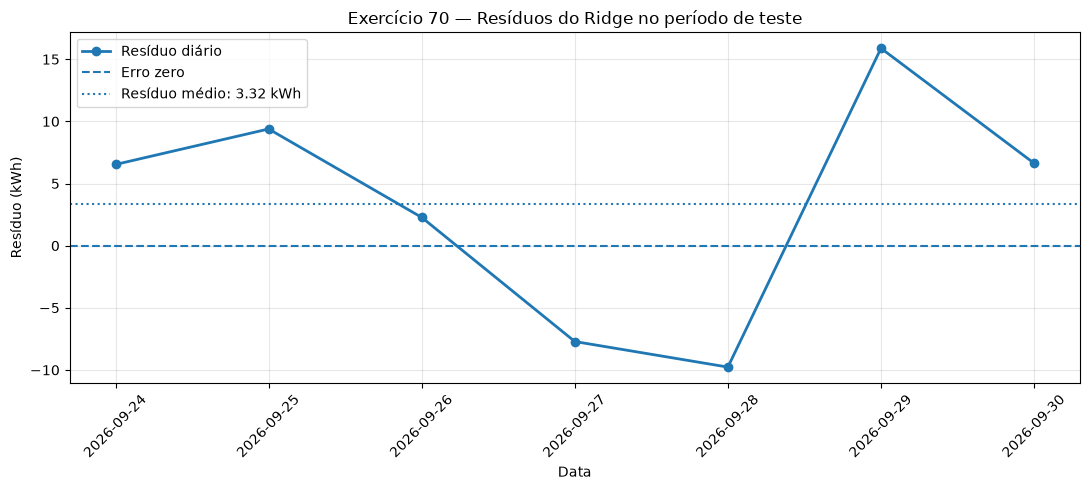

=== EXERCÍCIO 70 — DIAGNÓSTICO VISUAL ===
Período: 2026-09-24 a 2026-09-30
Resíduo médio: 3.3175 kWh
Gráfico gerado com sucesso.


In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Ordenar os resultados cronologicamente
dados_grafico_ex70 = (
    residuos_ex70.sort_values("data").reset_index(drop=True)
)

# Criar gráfico de resíduos
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    dados_grafico_ex70["data"],
    dados_grafico_ex70["residuo_kwh"],
    marker="o",
    linewidth=2,
    label="Resíduo diário"
)

ax.axhline(
    y=0,
    linestyle="--",
    label="Erro zero"
)

ax.axhline(
    y=media_residuos_ex70,
    linestyle=":",
    label=f"Resíduo médio: {media_residuos_ex70:.2f} kWh"
)

ax.set_title("Exercício 70 — Resíduos do Ridge no período de teste")
ax.set_xlabel("Data")
ax.set_ylabel("Resíduo (kWh)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Verificações
assert len(dados_grafico_ex70) == 7
assert np.isfinite(dados_grafico_ex70["residuo_kwh"]).all()

print("=== EXERCÍCIO 70 — DIAGNÓSTICO VISUAL ===")
print("Período:", dados_grafico_ex70["data"].min().date(),
      "a", dados_grafico_ex70["data"].max().date())
print("Resíduo médio:", round(media_residuos_ex70, 4), "kWh")
print("Gráfico gerado com sucesso.")



### Exercício 70 — Conclusões técnicas

**Modelo avaliado:** Ridge com alpha = 0.01, selecionado por validação temporal.

**Período de teste:** 24/09/2026 a 30/09/2026, com 7 registros.

**Resultados da análise de resíduos:**
- MAE: 8,3139 kWh.
- Resíduo médio: +3,3175 kWh.
- Desvio-padrão dos resíduos: 9,2217 kWh.
- Subestimações: 5 dias.
- Superestimações: 2 dias.
- Maior erro absoluto: 15,8832 kWh, em 29/09/2026.

**Diagnóstico de data drift:**
- Média de horas no treinamento: 9,1739.
- Média de horas no teste: 9,2857.
- Diferença padronizada: 0,0543.
- Não foi observada mudança expressiva na média de horas de operação.

**Limitações:**
- Apenas 30 registros sintéticos disponíveis.
- Somente 7 registros no conjunto de teste.
- Modelo utiliza apenas horas de operação como variável preditora.
- A análise descritiva não permite descartar data drift.
- Os resíduos observados não são suficientes para diagnosticar concept drift.
- Os resultados não devem ser generalizados para ambientes industriais reais sem validação adicional.

**Conclusão:**

O modelo apresentou erros moderados no conjunto analisado,
com tendência de subestimação do consumo no período de teste.
A análise de distribuição da variável de entrada não identificou
mudança expressiva na média entre treinamento e teste.

O experimento demonstra a importância de monitorar resíduos,
distribuições de entrada e limitações dos dados antes de
utilizar modelos preditivos em sistemas de auditoria energética.


## EXERCÍCIO 71 — ETAPA 1
### PREPARAÇÃO PARA DETECÇÃO DE ANOMALIAS


In [10]:
import pandas as pd
import numpy as np

# 1. Reutilizar os dados originais do Exercício 68
df_ex71 = df_ex68.copy()

# 2. Selecionar variáveis de análise
variaveis_ex71 = [
    "horas_operacao",
    "consumo_kwh"
]

X_ex71 = df_ex71[variaveis_ex71].copy()

# 3. Verificar integridade
assert len(df_ex71) == 30
assert df_ex71["data"].is_monotonic_increasing
assert df_ex71["data"].is_unique
assert X_ex71.notna().all().all()
assert np.isfinite(X_ex71.to_numpy()).all()

# 4. Estatísticas descritivas
print("=== EXERCÍCIO 71 — PREPARAÇÃO DOS DADOS ===")
print()
print("Registros:", len(df_ex71))
print("Variáveis:", variaveis_ex71)
print()
print("Estatísticas descritivas:")
print(X_ex71.describe().to_string())
print()
print("Primeiros registros:")
print(
    df_ex71[
        ["data", "horas_operacao", "consumo_kwh"]
    ].head().to_string(index=False)
)
print()
print("Preparação concluída com sucesso.")


=== EXERCÍCIO 71 — PREPARAÇÃO DOS DADOS ===

Registros: 30
Variáveis: ['horas_operacao', 'consumo_kwh']

Estatísticas descritivas:
       horas_operacao  consumo_kwh
count        30.00000    30.000000
mean          9.20000   216.807466
std           2.04096    36.313820
min           6.00000   161.965646
25%           7.25000   183.583867
50%          10.00000   225.339681
75%          11.00000   242.041477
max          12.00000   282.217498

Primeiros registros:
      data  horas_operacao  consumo_kwh
2026-09-01              11   240.631779
2026-09-02               7   171.154997
2026-09-03               6   164.579122
2026-09-04              10   228.434206
2026-09-05               8   177.506886

Preparação concluída com sucesso.


EXERCÍCIO 71 — ETAPA 2. 
DETECÇÃO DE ANOMALIAS COM ISOLATION FOREST


In [11]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# 1. Construir o pipeline
pipeline_isolation_ex71 = Pipeline([
    ("padronizacao", StandardScaler()),
    (
        "detector",
        IsolationForest(
            n_estimators=100,
            contamination=0.10,
            random_state=42
        )
    )
])

# 2. Ajustar o detector aos dados exploratórios
pipeline_isolation_ex71.fit(X_ex71)

# 3. Identificar observações
#  1 = comportamento considerado normal
# -1 = possível anomalia
rotulos_ex71 = pipeline_isolation_ex71.predict(X_ex71)

# 4. Calcular pontuações de anomalia
# Valores menores indicam observações mais anômalas
pontuacoes_ex71 = pipeline_isolation_ex71.decision_function(
    X_ex71
)

# 5. Organizar os resultados
resultado_isolation_ex71 = df_ex71[
    ["data", "horas_operacao", "consumo_kwh"]
].copy()

resultado_isolation_ex71["rotulo"] = rotulos_ex71
resultado_isolation_ex71["pontuacao"] = pontuacoes_ex71

resultado_isolation_ex71["possivel_anomalia"] = (
    resultado_isolation_ex71["rotulo"] == -1
)

# 6. Validar a execução
assert len(resultado_isolation_ex71) == 30
assert set(np.unique(rotulos_ex71)).issubset({-1, 1})
assert np.isfinite(pontuacoes_ex71).all()
assert resultado_isolation_ex71["data"].is_unique

# 7. Calcular a quantidade de possíveis anomalias
quantidade_anomalias_ex71 = int(
    resultado_isolation_ex71["possivel_anomalia"].sum()
)

percentual_anomalias_ex71 = (
    100 * quantidade_anomalias_ex71
    / len(resultado_isolation_ex71)
)

# 8. Apresentar os resultados
print("=== EXERCÍCIO 71 — ISOLATION FOREST ===")
print()

print("Registros analisados:", len(resultado_isolation_ex71))
print("Possíveis anomalias:", quantidade_anomalias_ex71)
print(f"Percentual sinalizado: {percentual_anomalias_ex71:.2f}%")

print()
print("Registros sinalizados:")

anomalias_ex71 = resultado_isolation_ex71.loc[
    resultado_isolation_ex71["possivel_anomalia"]
].sort_values("pontuacao")

if anomalias_ex71.empty:
    print("Nenhuma possível anomalia identificada.")
else:
    print(
        anomalias_ex71.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.4f}"
        )
    )

print()
print("Detecção exploratória concluída.")


=== EXERCÍCIO 71 — ISOLATION FOREST ===

Registros analisados: 30
Possíveis anomalias: 3
Percentual sinalizado: 10.00%

Registros sinalizados:
      data  horas_operacao  consumo_kwh  rotulo  pontuacao  possivel_anomalia
2026-09-17              12     282.2175      -1    -0.0749               True
2026-09-16               7     161.9656      -1    -0.0168               True
2026-09-29               6     175.3318      -1    -0.0029               True

Detecção exploratória concluída.


EXERCÍCIO 71 — ETAPA 3. 
COMPARAÇÃO COM REGRA BASEADA EM IQR



In [12]:
import numpy as np
import pandas as pd

# 1. Reutilizar os resultados do Isolation Forest
comparacao_ex71 = resultado_isolation_ex71.copy()

# 2. Calcular intensidade energética
comparacao_ex71["kwh_por_hora"] = (
    comparacao_ex71["consumo_kwh"]
    / comparacao_ex71["horas_operacao"]
)

# 3. Calcular quartis e intervalo interquartil (IQR)
q1_ex71 = comparacao_ex71["kwh_por_hora"].quantile(0.25)
q3_ex71 = comparacao_ex71["kwh_por_hora"].quantile(0.75)

iqr_ex71 = q3_ex71 - q1_ex71

limite_inferior_ex71 = q1_ex71 - 1.5 * iqr_ex71
limite_superior_ex71 = q3_ex71 + 1.5 * iqr_ex71

# 4. Aplicar regra exploratória
comparacao_ex71["anomalia_regra"] = (
    (comparacao_ex71["kwh_por_hora"] < limite_inferior_ex71)
    | (comparacao_ex71["kwh_por_hora"] > limite_superior_ex71)
)

# 5. Comparar os dois métodos
comparacao_ex71["concordancia"] = (
    comparacao_ex71["possivel_anomalia"]
    == comparacao_ex71["anomalia_regra"]
)

# 6. Verificações
assert (comparacao_ex71["horas_operacao"] > 0).all()
assert np.isfinite(comparacao_ex71["kwh_por_hora"]).all()
assert iqr_ex71 >= 0
assert len(comparacao_ex71) == 30

# 7. Resultados
print("=== EXERCÍCIO 71 — COMPARAÇÃO DE MÉTODOS ===")
print()
print(f"Q1: {q1_ex71:.4f} kWh/h")
print(f"Q3: {q3_ex71:.4f} kWh/h")
print(f"IQR: {iqr_ex71:.4f} kWh/h")
print(f"Limite inferior: {limite_inferior_ex71:.4f} kWh/h")
print(f"Limite superior: {limite_superior_ex71:.4f} kWh/h")
print()

print(
    "Sinalizações Isolation Forest:",
    int(comparacao_ex71["possivel_anomalia"].sum())
)

print(
    "Sinalizações regra IQR:",
    int(comparacao_ex71["anomalia_regra"].sum())
)

print(
    "Concordância entre classificações:",
    f"{comparacao_ex71['concordancia'].mean() * 100:.2f}%"
)

print()
print("Registros sinalizados por pelo menos um método:")

registros_sinalizados_ex71 = comparacao_ex71.loc[
    comparacao_ex71["possivel_anomalia"]
    | comparacao_ex71["anomalia_regra"],
    [
        "data",
        "horas_operacao",
        "consumo_kwh",
        "kwh_por_hora",
        "possivel_anomalia",
        "anomalia_regra"
    ]
]

if registros_sinalizados_ex71.empty:
    print("Nenhum registro sinalizado.")
else:
    print(
        registros_sinalizados_ex71.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.4f}"
        )
    )

print()
print("Comparação concluída.")


=== EXERCÍCIO 71 — COMPARAÇÃO DE MÉTODOS ===

Q1: 22.3531 kWh/h
Q3: 24.5974 kWh/h
IQR: 2.2443 kWh/h
Limite inferior: 18.9867 kWh/h
Limite superior: 27.9638 kWh/h

Sinalizações Isolation Forest: 3
Sinalizações regra IQR: 2
Concordância entre classificações: 90.00%

Registros sinalizados por pelo menos um método:
      data  horas_operacao  consumo_kwh  kwh_por_hora  possivel_anomalia  anomalia_regra
2026-09-16               7     161.9656       23.1379               True           False
2026-09-17              12     282.2175       23.5181               True           False
2026-09-19               6     171.6526       28.6088              False            True
2026-09-29               6     175.3318       29.2220               True            True

Comparação concluída.


EXERCÍCIO 71 — ETAPA 4. 
COMPARAÇÃO COM LOCAL OUTLIER FACTOR (LOF)


In [13]:
import numpy as np
import pandas as pd

from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# 1. Padronizar as variáveis
escalonador_lof_ex71 = StandardScaler()

X_padronizado_lof_ex71 = escalonador_lof_ex71.fit_transform(
    X_ex71
)

# 2. Configurar o detector LOF
modelo_lof_ex71 = LocalOutlierFactor(
    n_neighbors=5,
    contamination=0.10
)

# 3. Ajustar o modelo e identificar anomalias
rotulos_lof_ex71 = modelo_lof_ex71.fit_predict(
    X_padronizado_lof_ex71
)

# 4. Organizar comparação entre os três métodos
comparacao_tres_metodos_ex71 = comparacao_ex71.copy()

comparacao_tres_metodos_ex71["anomalia_lof"] = (
    rotulos_lof_ex71 == -1
)

# 5. Identificar registros sinalizados por qualquer método
colunas_metodos_ex71 = [
    "possivel_anomalia",
    "anomalia_regra",
    "anomalia_lof"
]

comparacao_tres_metodos_ex71["total_alertas"] = (
    comparacao_tres_metodos_ex71[
        colunas_metodos_ex71
    ].sum(axis=1)
)

# 6. Verificações
assert len(comparacao_tres_metodos_ex71) == 30
assert np.isfinite(X_padronizado_lof_ex71).all()
assert set(np.unique(rotulos_lof_ex71)).issubset({-1, 1})
assert comparacao_tres_metodos_ex71["total_alertas"].between(
    0, 3
).all()

# 7. Exibir resultados
print("=== EXERCÍCIO 71 — COMPARAÇÃO COM LOF ===")
print()

print(
    "Isolation Forest:",
    int(comparacao_tres_metodos_ex71["possivel_anomalia"].sum())
)

print(
    "Regra IQR:",
    int(comparacao_tres_metodos_ex71["anomalia_regra"].sum())
)

print(
    "LOF:",
    int(comparacao_tres_metodos_ex71["anomalia_lof"].sum())
)

print()
print("Registros sinalizados por pelo menos um método:")

alertas_ex71 = comparacao_tres_metodos_ex71.loc[
    comparacao_tres_metodos_ex71["total_alertas"] > 0,
    [
        "data",
        "horas_operacao",
        "consumo_kwh",
        "possivel_anomalia",
        "anomalia_regra",
        "anomalia_lof",
        "total_alertas"
    ]
].sort_values(
    ["total_alertas", "data"],
    ascending=[False, True]
)

if alertas_ex71.empty:
    print("Nenhum registro sinalizado.")
else:
    print(
        alertas_ex71.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.4f}"
        )
    )

print()
print("Comparação com LOF concluída.")


=== EXERCÍCIO 71 — COMPARAÇÃO COM LOF ===

Isolation Forest: 3
Regra IQR: 2
LOF: 3

Registros sinalizados por pelo menos um método:
      data  horas_operacao  consumo_kwh  possivel_anomalia  anomalia_regra  anomalia_lof  total_alertas
2026-09-17              12     282.2175               True           False          True              2
2026-09-29               6     175.3318               True            True         False              2
2026-09-06               9     206.2727              False           False          True              1
2026-09-16               7     161.9656               True           False         False              1
2026-09-19               6     171.6526              False            True         False              1
2026-09-30               9     219.1274              False           False          True              1

Comparação com LOF concluída.


EXERCÍCIO 71 — ETAPA 5. 
PRIORIZAÇÃO OPERACIONAL DOS ALERTAS



In [14]:
import numpy as np
import pandas as pd

# 1. Reutilizar a comparação dos três métodos
relatorio_alertas_ex71 = comparacao_tres_metodos_ex71.copy()

# 2. Definir prioridade experimental
condicoes_ex71 = [
    relatorio_alertas_ex71["total_alertas"] >= 2,
    relatorio_alertas_ex71["total_alertas"] == 1
]

prioridades_ex71 = [
    "Alta - investigar",
    "Revisao - verificar"
]

relatorio_alertas_ex71["prioridade"] = np.select(
    condicoes_ex71,
    prioridades_ex71,
    default="Sem alerta"
)

# 3. Selecionar registros que precisam de análise
fila_investigacao_ex71 = relatorio_alertas_ex71.loc[
    relatorio_alertas_ex71["total_alertas"] > 0,
    [
        "data",
        "horas_operacao",
        "consumo_kwh",
        "kwh_por_hora",
        "possivel_anomalia",
        "anomalia_regra",
        "anomalia_lof",
        "total_alertas",
        "prioridade"
    ]
].sort_values(
    ["total_alertas", "data"],
    ascending=[False, True]
)

# 4. Validar consistência
assert len(relatorio_alertas_ex71) == 30

assert (
    relatorio_alertas_ex71["total_alertas"]
    == relatorio_alertas_ex71[
        [
            "possivel_anomalia",
            "anomalia_regra",
            "anomalia_lof"
        ]
    ].sum(axis=1)
).all()

assert (
    fila_investigacao_ex71["total_alertas"] > 0
).all()

# 5. Exibir resumo
print("=== EXERCÍCIO 71 — PRIORIZAÇÃO DE ALERTAS ===")
print()

print("Registros analisados:", len(relatorio_alertas_ex71))
print("Registros com alerta:", len(fila_investigacao_ex71))

print(
    "Prioridade alta:",
    int((relatorio_alertas_ex71["total_alertas"] >= 2).sum())
)

print(
    "Prioridade de revisão:",
    int((relatorio_alertas_ex71["total_alertas"] == 1).sum())
)

print()
print("Fila de investigação:")

print(
    fila_investigacao_ex71.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}"
    )
)

print()
print("Priorização operacional concluída.")


=== EXERCÍCIO 71 — PRIORIZAÇÃO DE ALERTAS ===

Registros analisados: 30
Registros com alerta: 6
Prioridade alta: 2
Prioridade de revisão: 4

Fila de investigação:
      data  horas_operacao  consumo_kwh  kwh_por_hora  possivel_anomalia  anomalia_regra  anomalia_lof  total_alertas          prioridade
2026-09-17              12     282.2175       23.5181               True           False          True              2   Alta - investigar
2026-09-29               6     175.3318       29.2220               True            True         False              2   Alta - investigar
2026-09-06               9     206.2727       22.9192              False           False          True              1 Revisao - verificar
2026-09-16               7     161.9656       23.1379               True           False         False              1 Revisao - verificar
2026-09-19               6     171.6526       28.6088              False            True         False              1 Revisao - verificar
2026-09-3


### Exercício 71 — Detecção de Anomalias Energéticas

**Objetivo:** identificar e priorizar comportamentos atípicos
em registros de consumo energético.

**Métodos utilizados:**
- Isolation Forest com contamination = 0.10.
- Regra estatística baseada no IQR do consumo por hora.
- Local Outlier Factor (LOF), com 5 vizinhos.

**Resultados:**
- Registros analisados: 30.
- Alertas do Isolation Forest: 3.
- Alertas da regra IQR: 2.
- Alertas do LOF: 3.
- Registros sinalizados por pelo menos um método: 6.
- Prioridade alta: 2 registros.
- Prioridade de revisão: 4 registros.
- Nenhum registro foi sinalizado pelos três métodos.

**Registros prioritários:**
- 17/09/2026: sinalizado por Isolation Forest e LOF.
- 29/09/2026: sinalizado por Isolation Forest e IQR.

**Limitações:**
- Dados sintéticos e amostra reduzida.
- Ausência de rótulos de anomalias confirmadas.
- Impossibilidade de medir falsos positivos, precisão e recall.
- Parâmetros experimentais ainda não calibrados.
- Análise exploratória realizada na mesma amostra utilizada
  para ajustar os detectores.
- Alertas não constituem evidência de fraude ou desperdício.

**Conclusão:**

A combinação de métodos permitiu identificar diferentes
padrões de comportamento atípico e organizar uma fila
preliminar de investigação.

O resultado poderá integrar o módulo de monitoramento
do AI Energy Auditor, desde que seja submetido a
validação operacional e testes com dados independentes.


## EXERCÍCIO 72 — ETAPA 1
### TESTES DE INTEGRIDADE DOS DETECTORES


In [15]:
import numpy as np
import pandas as pd

# 1. Verificar preservação dos registros
assert len(df_ex71) == 30
assert len(comparacao_tres_metodos_ex71) == len(df_ex71)

assert (
    comparacao_tres_metodos_ex71["data"].to_numpy()
    == df_ex71["data"].to_numpy()
).all()

# 2. Verificar integridade dos dados originais
for coluna in ["horas_operacao", "consumo_kwh"]:
    np.testing.assert_allclose(
        comparacao_tres_metodos_ex71[coluna].to_numpy(),
        df_ex71[coluna].to_numpy()
    )

# 3. Verificar consistência das sinalizações
colunas_alertas_ex72 = [
    "possivel_anomalia",
    "anomalia_regra",
    "anomalia_lof"
]

for coluna in colunas_alertas_ex72:
    assert (
        comparacao_tres_metodos_ex71[coluna].dtype == bool
    )

total_calculado_ex72 = (
    comparacao_tres_metodos_ex71[colunas_alertas_ex72]
    .sum(axis=1)
)

np.testing.assert_array_equal(
    comparacao_tres_metodos_ex71["total_alertas"].to_numpy(),
    total_calculado_ex72.to_numpy()
)

# 4. Verificar a fila de investigação
assert len(fila_investigacao_ex71) == int(
    (total_calculado_ex72 > 0).sum()
)

assert (
    fila_investigacao_ex71["total_alertas"] > 0
).all()

# 5. Verificar ausência de dados inválidos
assert np.isfinite(
    comparacao_tres_metodos_ex71[
        ["horas_operacao", "consumo_kwh", "kwh_por_hora"]
    ].to_numpy()
).all()

print("=== EXERCÍCIO 72 — TESTES DE INTEGRIDADE ===")
print()
print("Preservação dos 30 registros: OK")
print("Integridade das variáveis originais: OK")
print("Consistência das sinalizações: OK")
print("Contagem dos alertas: OK")
print("Fila de investigação: OK")
print("Ausência de valores inválidos: OK")
print()
print("Todos os testes de integridade foram aprovados.")


=== EXERCÍCIO 72 — TESTES DE INTEGRIDADE ===

Preservação dos 30 registros: OK
Integridade das variáveis originais: OK
Consistência das sinalizações: OK
Contagem dos alertas: OK
Fila de investigação: OK
Ausência de valores inválidos: OK

Todos os testes de integridade foram aprovados.


 EXERCÍCIO 72 — ETAPA 2. 
TESTES DE REPRODUTIBILIDADE DOS DETECTORES



In [16]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# 1. Recriar o Isolation Forest com os mesmos parâmetros
pipeline_reteste_ex72 = Pipeline([
    ("padronizacao", StandardScaler()),
    (
        "detector",
        IsolationForest(
            n_estimators=100,
            contamination=0.10,
            random_state=42
        )
    )
])

rotulos_reteste_isolation_ex72 = (
    pipeline_reteste_ex72.fit_predict(X_ex71)
)

# 2. Comparar com os resultados originais
np.testing.assert_array_equal(
    rotulos_reteste_isolation_ex72,
    rotulos_ex71
)

# 3. Verificar também as pontuações
pontuacoes_reteste_ex72 = (
    pipeline_reteste_ex72.decision_function(X_ex71)
)

np.testing.assert_allclose(
    pontuacoes_reteste_ex72,
    pontuacoes_ex71,
    rtol=1e-10,
    atol=1e-12
)

# 4. Recriar o LOF com os mesmos parâmetros
escalonador_reteste_ex72 = StandardScaler()

X_reteste_lof_ex72 = (
    escalonador_reteste_ex72.fit_transform(X_ex71)
)

modelo_reteste_lof_ex72 = LocalOutlierFactor(
    n_neighbors=5,
    contamination=0.10
)

rotulos_reteste_lof_ex72 = (
    modelo_reteste_lof_ex72.fit_predict(
        X_reteste_lof_ex72
    )
)

# 5. Comparar com os resultados originais do LOF
np.testing.assert_array_equal(
    rotulos_reteste_lof_ex72,
    rotulos_lof_ex71
)

# 6. Confirmar as quantidades de alertas
assert int(
    (rotulos_reteste_isolation_ex72 == -1).sum()
) == 3

assert int(
    (rotulos_reteste_lof_ex72 == -1).sum()
) == 3

# 7. Exibir resultado
print("=== EXERCÍCIO 72 — REPRODUTIBILIDADE ===")
print()
print("Isolation Forest — classificações reproduzidas: OK")
print("Isolation Forest — pontuações reproduzidas: OK")
print("LOF — classificações reproduzidas: OK")
print("Quantidade de alertas preservada: OK")
print()
print("Todos os testes de reprodutibilidade foram aprovados.")


=== EXERCÍCIO 72 — REPRODUTIBILIDADE ===

Isolation Forest — classificações reproduzidas: OK
Isolation Forest — pontuações reproduzidas: OK
LOF — classificações reproduzidas: OK
Quantidade de alertas preservada: OK

Todos os testes de reprodutibilidade foram aprovados.


EXERCÍCIO 73 — ETAPA 6. 
PRIMEIRA API DO AI ENERGY AUDITOR


In [17]:
from fastapi import FastAPI
from fastapi.testclient import TestClient

# 1. Criar a aplicação
app_ex73 = FastAPI(
    title="AI Energy Auditor",
    description="Protótipo de auditoria energética com IA",
    version="0.1.0"
)

# 2. Endpoint principal
@app_ex73.get("/")
def pagina_inicial_ex73():
    return {
        "sistema": "AI Energy Auditor",
        "versao": "0.1.0",
        "status": "em desenvolvimento"
    }

# 3. Endpoint de saúde
@app_ex73.get("/health")
def verificar_saude_ex73():
    return {
        "status": "ok",
        "servico": "AI Energy Auditor"
    }

# 4. Testar a API sem iniciar um servidor externo
cliente_ex73 = TestClient(app_ex73)

resposta_inicial_ex73 = cliente_ex73.get("/")
resposta_saude_ex73 = cliente_ex73.get("/health")

# 5. Validar os resultados
assert resposta_inicial_ex73.status_code == 200
assert resposta_saude_ex73.status_code == 200
assert resposta_saude_ex73.json()["status"] == "ok"

# 6. Exibir os resultados
print("=== EXERCÍCIO 73 — PRIMEIRA API ===")
print()
print("GET /")
print(resposta_inicial_ex73.json())
print()
print("GET /health")
print(resposta_saude_ex73.json())
print()
print("Testes iniciais da API aprovados.")


=== EXERCÍCIO 73 — PRIMEIRA API ===

GET /
{'sistema': 'AI Energy Auditor', 'versao': '0.1.0', 'status': 'em desenvolvimento'}

GET /health
{'status': 'ok', 'servico': 'AI Energy Auditor'}

Testes iniciais da API aprovados.


c:\Engenharia-IA\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


EXERCÍCIO 73 — ETAPA 7. 
ENDPOINT DE RESUMO DOS DADOS ENERGÉTICOS


In [19]:
from pathlib import Path
import pandas as pd

# 1. Localizar o arquivo original
arquivo_dados_ex73 = Path(
    r"C:\Engenharia-IA\01-Fundamentos-Python-ML"
    r"\dados\consumo_energetico_v1.csv"
)

assert arquivo_dados_ex73.is_file(), (
    f"Arquivo não encontrado: {arquivo_dados_ex73}"
)

# 2. Criar endpoint de consulta
@app_ex73.get("/dados/resumo")
def resumo_energetico_ex73():

    dados = pd.read_csv(arquivo_dados_ex73)

    colunas_obrigatorias = {
        "data",
        "horas_operacao",
        "consumo_kwh"
    }

    if not colunas_obrigatorias.issubset(dados.columns):
        raise ValueError(
            "O arquivo não contém todas as colunas obrigatórias."
        )

    return {
        "total_registros": int(len(dados)),
        "consumo_total_kwh": round(
            float(dados["consumo_kwh"].sum()), 4
        ),
        "consumo_medio_kwh": round(
            float(dados["consumo_kwh"].mean()), 4
        ),
        "horas_operacao_total": int(
            dados["horas_operacao"].sum()
        )
    }

# 3. Testar o endpoint
resposta_resumo_ex73 = cliente_ex73.get("/dados/resumo")

assert resposta_resumo_ex73.status_code == 200

resumo_ex73 = resposta_resumo_ex73.json()

assert resumo_ex73["total_registros"] == 30
assert resumo_ex73["consumo_total_kwh"] > 0
assert resumo_ex73["horas_operacao_total"] > 0

print("=== EXERCÍCIO 73 — RESUMO ENERGÉTICO ===")
print()
print("Endpoint: GET /dados/resumo")
print("HTTP:", resposta_resumo_ex73.status_code)
print()
for chave, valor in resumo_ex73.items():
    print(f"{chave}: {valor}")

print()
print("Endpoint de dados energéticos validado.")


=== EXERCÍCIO 73 — RESUMO ENERGÉTICO ===

Endpoint: GET /dados/resumo
HTTP: 200

total_registros: 30
consumo_total_kwh: 6504.224
consumo_medio_kwh: 216.8075
horas_operacao_total: 276

Endpoint de dados energéticos validado.


EXERCÍCIO 73 — ETAPA 8. 
ENDPOINT DE INTEGRIDADE CRIPTOGRÁFICA



In [21]:
import sys
from pathlib import Path

# 1. Garantir acesso ao módulo existente
raiz_projeto_ex73 = arquivo_dados_ex73.parent.parent

if str(raiz_projeto_ex73) not in sys.path:
    sys.path.insert(0, str(raiz_projeto_ex73))

from exercicios.integridade_qualidade import (
    calcular_sha256_artefato
)

# 2. Criar endpoint
@app_ex73.get("/dados/integridade")
def integridade_dados_ex73():

    hash_sha256 = calcular_sha256_artefato(
        arquivo_dados_ex73
    )

    return {
        "arquivo": arquivo_dados_ex73.name,
        "algoritmo": "SHA-256",
        "sha256": hash_sha256
    }

# 3. Testar endpoint
resposta_integridade_ex73 = cliente_ex73.get(
    "/dados/integridade"
)

assert resposta_integridade_ex73.status_code == 200

resultado_integridade_ex73 = (
    resposta_integridade_ex73.json()
)

assert resultado_integridade_ex73["algoritmo"] == "SHA-256"
assert len(resultado_integridade_ex73["sha256"]) == 64

# 4. Confirmar que o hash corresponde ao arquivo original
assert (
    resultado_integridade_ex73["sha256"]
    == calcular_sha256_artefato(arquivo_dados_ex73)
)

print("=== EXERCÍCIO 73 — INTEGRIDADE DOS DADOS ===")
print()
print("Endpoint: GET /dados/integridade")
print("HTTP:", resposta_integridade_ex73.status_code)
print("Arquivo:", resultado_integridade_ex73["arquivo"])
print("Algoritmo:", resultado_integridade_ex73["algoritmo"])
print("SHA-256:", resultado_integridade_ex73["sha256"])
print()
print("Verificação de integridade aprovada.")


=== EXERCÍCIO 73 — INTEGRIDADE DOS DADOS ===

Endpoint: GET /dados/integridade
HTTP: 200
Arquivo: consumo_energetico_v1.csv
Algoritmo: SHA-256
SHA-256: c24a08ea24623e98ac6b180e0ce9aa0b74e9807a3433882906f42e93884144de

Verificação de integridade aprovada.


EXERCÍCIO 73 — ETAPA 9. 
ENDPOINT DE PREVISÃO ENERGÉTICA COM RIDGE



In [22]:
import numpy as np
import pandas as pd

from pydantic import BaseModel, Field

# 1. Confirmar que o modelo do Exercício 69 está disponível
assert hasattr(pipeline_ridge_final_ex69, "predict"), (
    "O modelo Ridge do Exercício 69 não está disponível."
)

# 2. Definir o contrato de entrada da API
class EntradaPrevisaoEx73(BaseModel):
    horas_operacao: float = Field(
        ...,
        gt=0,
        le=24,
        description="Horas de operação no período diário"
    )

# 3. Criar o endpoint
@app_ex73.post("/previsao")
def prever_consumo_ex73(entrada: EntradaPrevisaoEx73):

    dados_entrada = pd.DataFrame({
        "horas_operacao": [entrada.horas_operacao]
    })

    previsao = pipeline_ridge_final_ex69.predict(
        dados_entrada
    )

    consumo_previsto = float(previsao[0])

    if not np.isfinite(consumo_previsto):
        raise ValueError("Previsão numérica inválida.")

    return {
        "modelo": "Ridge",
        "horas_operacao": entrada.horas_operacao,
        "consumo_previsto_kwh": round(
            consumo_previsto, 4
        ),
        "unidade": "kWh"
    }

# 4. Testar uma previsão válida
resposta_previsao_ex73 = cliente_ex73.post(
    "/previsao",
    json={"horas_operacao": 8.0}
)

assert resposta_previsao_ex73.status_code == 200

resultado_previsao_ex73 = resposta_previsao_ex73.json()

# 5. Comparar com o modelo original
previsao_direta_ex73 = float(
    pipeline_ridge_final_ex69.predict(
        pd.DataFrame({"horas_operacao": [8.0]})
    )[0]
)

assert np.isclose(
    resultado_previsao_ex73["consumo_previsto_kwh"],
    previsao_direta_ex73,
    atol=0.00005
)

# 6. Testar rejeição de entradas inválidas
for horas_invalidas in [-1, 0, 25]:
    resposta_invalida = cliente_ex73.post(
        "/previsao",
        json={"horas_operacao": horas_invalidas}
    )
    assert resposta_invalida.status_code == 422

print("=== EXERCÍCIO 73 — PREVISÃO ENERGÉTICA ===")
print()
print("Endpoint: POST /previsao")
print("HTTP:", resposta_previsao_ex73.status_code)
print("Resultado:", resultado_previsao_ex73)
print()
print("Previsão consistente com o modelo original: OK")
print("Validação de entradas inválidas: OK")
print()
print("Endpoint de previsão energética validado.")


=== EXERCÍCIO 73 — PREVISÃO ENERGÉTICA ===

Endpoint: POST /previsao
HTTP: 200
Resultado: {'modelo': 'Ridge', 'horas_operacao': 8.0, 'consumo_previsto_kwh': 194.8141, 'unidade': 'kWh'}

Previsão consistente com o modelo original: OK
Validação de entradas inválidas: OK

Endpoint de previsão energética validado.


EXERCÍCIO 73 — ETAPA 10. 
ENDPOINT DE ALERTAS DE ANOMALIAS


In [24]:

# 1. Preservar uma cópia da fila validada
fila_api_ex73 = fila_investigacao_ex71.copy()

# 2. Criar endpoint de consulta
@app_ex73.get("/anomalias")
def consultar_anomalias_ex73():

    alertas = []

    for _, registro in fila_api_ex73.iterrows():

        metodos = []

        if bool(registro["possivel_anomalia"]):
            metodos.append("Isolation Forest")

        if bool(registro["anomalia_regra"]):
            metodos.append("IQR")

        if bool(registro["anomalia_lof"]):
            metodos.append("LOF")

        alertas.append({
            "data": pd.Timestamp(
                registro["data"]
            ).strftime("%Y-%m-%d"),
            "horas_operacao": int(
                registro["horas_operacao"]
            ),
            "consumo_kwh": round(
                float(registro["consumo_kwh"]), 4
            ),
            "total_alertas": int(
                registro["total_alertas"]
            ),
            "prioridade": str(
                registro["prioridade"]
            ),
            "metodos": metodos
        })

    return {
        "total_registros_analisados": int(len(df_ex71)),
        "total_registros_sinalizados": len(alertas),
        "alertas": alertas,
        "observacao": (
            "Alertas estatísticos não comprovam "
            "fraude ou desperdício energético."
        )
    }

# 3. Testar endpoint
resposta_anomalias_ex73 = cliente_ex73.get("/anomalias")

assert resposta_anomalias_ex73.status_code == 200

resultado_anomalias_ex73 = resposta_anomalias_ex73.json()

# 4. Validar os resultados esperados
assert resultado_anomalias_ex73[
    "total_registros_analisados"
] == 30

assert resultado_anomalias_ex73[
    "total_registros_sinalizados"
] == 6

assert len(resultado_anomalias_ex73["alertas"]) == 6

assert sum(
    alerta["total_alertas"] >= 2
    for alerta in resultado_anomalias_ex73["alertas"]
) == 2

# 5. Confirmar consistência dos métodos
for alerta in resultado_anomalias_ex73["alertas"]:
    assert len(alerta["metodos"]) == alerta["total_alertas"]

# 6. Exibir resultado
print("=== EXERCÍCIO 73 — ALERTAS DE ANOMALIAS ===")
print()
print("Endpoint: GET /anomalias")
print("HTTP:", resposta_anomalias_ex73.status_code)
print(
    "Registros analisados:",
    resultado_anomalias_ex73["total_registros_analisados"]
)
print(
    "Registros sinalizados:",
    resultado_anomalias_ex73["total_registros_sinalizados"]
)
print()

for alerta in resultado_anomalias_ex73["alertas"]:
    print(
        f'{alerta["data"]} | '
        f'{alerta["prioridade"]} | '
        f'{", ".join(alerta["metodos"])}'
    )

print()
print("Endpoint de anomalias validado.")


=== EXERCÍCIO 73 — ALERTAS DE ANOMALIAS ===

Endpoint: GET /anomalias
HTTP: 200
Registros analisados: 30
Registros sinalizados: 6

2026-09-17 | Alta - investigar | Isolation Forest, LOF
2026-09-29 | Alta - investigar | Isolation Forest, IQR
2026-09-06 | Revisao - verificar | LOF
2026-09-16 | Revisao - verificar | Isolation Forest
2026-09-19 | Revisao - verificar | IQR
2026-09-30 | Revisao - verificar | LOF

Endpoint de anomalias validado.


EXERCÍCIO 73 — ETAPA 11. 
TESTE INTEGRADO DA API



In [25]:
# 1. Consultar todos os endpoints
testes_api_ex73 = [
    ("GET", "/", None),
    ("GET", "/health", None),
    ("GET", "/dados/resumo", None),
    ("GET", "/dados/integridade", None),
    ("POST", "/previsao", {"horas_operacao": 8.0}),
    ("GET", "/anomalias", None),
]

for metodo, caminho, corpo in testes_api_ex73:

    if metodo == "GET":
        resposta = cliente_ex73.get(caminho)
    else:
        resposta = cliente_ex73.post(
            caminho,
            json=corpo
        )

    assert resposta.status_code == 200, (
        f"Falha em {metodo} {caminho}: "
        f"HTTP {resposta.status_code}"
    )

    print(
        f"{metodo:4} {caminho:22} "
        f"HTTP {resposta.status_code} — OK"
    )

# 2. Verificar entrada inválida
resposta_invalida_ex73 = cliente_ex73.post(
    "/previsao",
    json={"horas_operacao": -5}
)

assert resposta_invalida_ex73.status_code == 422

print()
print(
    "POST /previsao (entrada inválida): "
    "HTTP 422 — OK"
)

# 3. Verificar rota inexistente
resposta_inexistente_ex73 = cliente_ex73.get(
    "/rota-inexistente"
)

assert resposta_inexistente_ex73.status_code == 404

print(
    "GET /rota-inexistente: "
    "HTTP 404 — OK"
)

print()
print("=== RESULTADO FINAL ===")
print("6 requisições válidas aprovadas.")
print("Validação de entrada inválida aprovada.")
print("Tratamento de rota inexistente aprovado.")
print()
print("Teste integrado da API concluído.")


GET  /                      HTTP 200 — OK
GET  /health                HTTP 200 — OK
GET  /dados/resumo          HTTP 200 — OK
GET  /dados/integridade     HTTP 200 — OK
POST /previsao              HTTP 200 — OK
GET  /anomalias             HTTP 200 — OK

POST /previsao (entrada inválida): HTTP 422 — OK
GET /rota-inexistente: HTTP 404 — OK

=== RESULTADO FINAL ===
6 requisições válidas aprovadas.
Validação de entrada inválida aprovada.
Tratamento de rota inexistente aprovado.

Teste integrado da API concluído.


 EXERCÍCIO 73 — ETAPA 12. 
INSPEÇÃO DA CONFIGURAÇÃO DO MODELO RIDGE


In [26]:
print("=== MODELO RIDGE — EXERCÍCIO 69 ===")
print()

print("Pipeline:")
print(pipeline_ridge_final_ex69)

print()
print("Parâmetros:")
print(pipeline_ridge_final_ex69.get_params())

print()
print("Quantidade de registros de treinamento:")
print(len(X_treino_ex68))

print()
print("Quantidade de registros de teste:")
print(len(X_teste_ex68))

print()
print("Alpha selecionado:")
print(melhor_alpha_ex69)


=== MODELO RIDGE — EXERCÍCIO 69 ===

Pipeline:
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('padronizacao',
                                                  StandardScaler(),
                                                  ['horas_operacao'])])),
                ('modelo', Ridge(alpha=0.01))])

Parâmetros:
{'memory': None, 'steps': [('preprocessamento', ColumnTransformer(transformers=[('padronizacao', StandardScaler(),
                                 ['horas_operacao'])])), ('modelo', Ridge(alpha=0.01))], 'transform_input': None, 'verbose': False, 'preprocessamento': ColumnTransformer(transformers=[('padronizacao', StandardScaler(),
                                 ['horas_operacao'])]), 'modelo': Ridge(alpha=0.01), 'preprocessamento__n_jobs': None, 'preprocessamento__remainder': 'drop', 'preprocessamento__sparse_threshold': 0.3, 'preprocessamento__transformer_weights': None, 'preprocessamento__transformers': [('padronizacao', StandardScale

EXERCÍCIO 73 — ETAPA 17.
CONFERÊNCIA DOS DETECTORES DE ANOMALIAS



In [27]:
print("=== ISOLATION FOREST ===")
print(pipeline_isolation_ex71)
print()

print("=== LOCAL OUTLIER FACTOR ===")
print("Vizinhos: 5")
print("Contamination: 0.10")
print()

print("=== REGRA IQR ===")

consumo_hora = (
    df_ex71["consumo_kwh"]
    / df_ex71["horas_operacao"]
)

q1 = consumo_hora.quantile(0.25)
q3 = consumo_hora.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print(f"Q1: {q1:.4f}")
print(f"Q3: {q3:.4f}")
print(f"IQR: {iqr:.4f}")
print(f"Limite inferior: {limite_inferior:.4f}")
print(f"Limite superior: {limite_superior:.4f}")

print()
print("=== RESULTADOS DE REFERÊNCIA ===")
print("Isolation Forest:", int(
    comparacao_tres_metodos_ex71["possivel_anomalia"].sum()
))
print("IQR:", int(
    comparacao_tres_metodos_ex71["anomalia_regra"].sum()
))
print("LOF:", int(
    comparacao_tres_metodos_ex71["anomalia_lof"].sum()
))
print("Registros sinalizados:", len(fila_investigacao_ex71))


=== ISOLATION FOREST ===
Pipeline(steps=[('padronizacao', StandardScaler()),
                ('detector',
                 IsolationForest(contamination=0.1, random_state=42))])

=== LOCAL OUTLIER FACTOR ===
Vizinhos: 5
Contamination: 0.10

=== REGRA IQR ===
Q1: 22.3531
Q3: 24.5974
IQR: 2.2443
Limite inferior: 18.9867
Limite superior: 27.9638

=== RESULTADOS DE REFERÊNCIA ===
Isolation Forest: 3
IQR: 2
LOF: 3
Registros sinalizados: 6
